# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** Esbeide Ibarra
**Date:** [Add date]
**GitHub Repository:** https://github.com/EsbeideIbarra0217/ITAI2373-NLP

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [1]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 41.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


✅ All packages installed successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [2]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

Some different industries and uses cases are:

Finance and investing: Companies can analyze news sentiment about businesses and track mentions of things like CEOs, mergers, or lawsuits to help identify risks and investment opportunities.

Public relations and brand management: Organizations can monitor how their brand, products, or executives are being discussed in the media and quickly respond if negative sentiment starts increasing.

Government and public policy: Agencies can track discussions about legislation, public health concerns, or emerging events to better understand what issues are receiving the most attention.

Security and risk intelligence: Businesses can monitor global news for supply chain disruptions, cyberattacks, or political events that may impact their operations.

Healthcare and pharmaceuticals: Healthcare organizations can follow news related to disease outbreaks, drug recalls, clinical trials, and competitor developments.

Legal and compliance: Companies can identify negative media coverage involving clients, vendors, or business partners during background checks and compliance reviews.

Journalism and news organizations: Newsrooms can automatically categorize articles, connect stories to related coverage, and identify trending topics more efficiently.

Education and research: Researchers can analyze how media coverage of a topic changes over time and study trends in public opinion or reporting.

Competitive intelligence: Businesses can track competitor activities such as product launches, partnerships, and hiring trends across multiple news sources.

Customer service and e-commerce: The same sentiment analysis and entity extraction techniques can be applied to customer reviews, support tickets, and social media posts to better understand customer feedback.

In [8]:
# Step 1: Install Kaggle API
!pip install kaggle

# Step 2: Upload your kaggle.json file
from google.colab import files
print("Please upload your kaggle.json file:")
uploaded = files.upload()

# Step 3: Set up API credentials
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("✅ Kaggle API setup complete!")

# For BBC News Dataset (recommended):

# Download BBC News Dataset
!kaggle competitions download -c learn-ai-bbc

# Unzip the files
!unzip learn-ai-bbc.zip

# List the files to see what we have
!ls -la

# Load the dataset
import pandas as pd
import os

# Check what files are available
print("Available files:")
for file in os.listdir('.'):
    if file.endswith('.csv'):
        print(f"  - {file}")

# Load the main dataset (adjust filename as needed)
# Common filenames: train.csv, bbc-text.csv, or similar
df = pd.read_csv('BBC News Train.csv')  # Updated to match extracted filename
print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"Categories: {df['Category'].unique()}")  # Updated to capital 'Category' to fix KeyError

Please upload your kaggle.json file:


Saving learn-ai-bbc.zip to learn-ai-bbc (2).zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
✅ Kaggle API setup complete!
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
Archive:  learn-ai-bbc.zip
replace BBC News Sample Solution.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: yes
  inflating: BBC News Sample Solution.csv  
replace BBC News Test.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: yes
  inflating: BBC News Test.csv       
replace BBC News Train.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: yes
  inflating: BBC News Train.csv      
total 10656
drwxr-xr-x 1 root root    4096 Oct 30 02:56  .
drwxr-xr-x 1 root root    4096 Oct 30 01:47  ..
-rw-r--r-- 1 root root   10369 Dec  2  2019 'BBC News Sample Solution.csv'
-rw-r--r-- 1 root root 1712432 Dec  2  2019 'BBC News Test.csv'

In [10]:
# Data preparation template
import pandas as pd
import numpy as np

# 1. Examine your dataset
print("Dataset Info:")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nFirst few rows:")
print(df.head())

# 2. Identify text and category columns
# Adjust these column names based on your dataset
text_column = 'Text'  # Updated to match the capitalized column name 'Text'
category_column = 'Category'  # Updated to match the capitalized column name 'Category'

# 3. Check for missing values
print(f"\nMissing values:")
print(df.isnull().sum())

# 4. Remove rows with missing text or categories
df_clean = df.dropna(subset=[text_column, category_column])

# 5. Check category distribution
print(f"\nCategory distribution:")
print(df_clean[category_column].value_counts())

# 6. Sample if dataset is too large (keep under 2000 for Colab)
if len(df_clean) > 2000:
    df_final = df_clean.sample(n=2000, random_state=42)
    print(f"\nSampled dataset to {len(df_final)} rows")
else:
    df_final = df_clean

# 7. Rename columns for consistency
df_final = df_final.rename(columns={
    text_column: 'content',
    category_column: 'category'
})

# 8. Save prepared dataset
df_final.to_csv('newsbot_dataset.csv', index=False)
print("\n✅ Dataset prepared and saved as 'newsbot_dataset.csv'")

Dataset Info:
Shape: (1490, 3)
Columns: ['ArticleId', 'Text', 'Category']

First few rows:
   ArticleId                                               Text  Category
0       1833  worldcom ex-boss launches defence lawyers defe...  business
1        154  german business confidence slides german busin...  business
2       1101  bbc poll indicates economic gloom citizens in ...  business
3       1976  lifestyle  governs mobile choice  faster  bett...      tech
4        917  enron bosses in $168m payout eighteen former e...  business

Missing values:
ArticleId    0
Text         0
Category     0
dtype: int64

Category distribution:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

✅ Dataset prepared and saved as 'newsbot_dataset.csv'


In [12]:
# Load your dataset
# 💡 TIP: If using the provided dataset, upload it to Colab first
# 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# Option 1: Load prepared dataset
# df = pd.read_csv('newsbot_dataset.csv')

# Option 2: Load BBC News dataset (if using alternative)
# You can download this from: https://www.kaggle.com/c/learn-ai-bbc/data

# Option 3: Create sample data for testing (remove this when you have real data)
sample_data = {
    'article_id': range(1, 11),
    'title': [
        'Apple Inc. Reports Record Quarterly Earnings',
        'Manchester United Defeats Chelsea 3-1',
        'New AI Technology Revolutionizes Healthcare',
        'President Biden Announces Climate Initiative',
        'Netflix Releases New Original Series',
        'Tesla Stock Rises After Production Update',
        'Olympic Games Begin in Paris',
        'Google Launches New Search Algorithm',
        'Congress Passes Infrastructure Bill',
        'Disney+ Subscriber Numbers Grow'
    ],
    'content': [
        'Apple Inc. announced record quarterly earnings today, with CEO Tim Cook highlighting strong iPhone sales and services revenue growth.',
        'Manchester United secured a convincing 3-1 victory over Chelsea at Old Trafford, with goals from Marcus Rashford and Bruno Fernandes.',
        'A breakthrough AI system developed by researchers at Stanford University shows promise for early disease detection in medical imaging.',
        'President Joe Biden unveiled a comprehensive climate change initiative aimed at reducing carbon emissions by 50% over the next decade.',
        'Netflix premiered its latest original series to critical acclaim, featuring an ensemble cast and innovative storytelling techniques.',
        'Tesla shares jumped 8% in after-hours trading following the company\'s announcement of increased production capacity at its Texas facility.',
        'The 2024 Olympic Games officially began in Paris with a spectacular opening ceremony attended by world leaders and celebrities.',
        'Google introduced a new search algorithm that promises more accurate and contextually relevant results for users worldwide.',
        'The U.S. Congress passed a bipartisan infrastructure bill allocating $1.2 trillion for roads, bridges, and broadband expansion.',
        'Disney+ reported strong subscriber growth in Q3, reaching 150 million subscribers globally across all markets.'
    ],
    'category': ['Business', 'Sports', 'Technology', 'Politics', 'Entertainment',
                'Business', 'Sports', 'Technology', 'Politics', 'Entertainment'],
    'date': ['2024-01-15'] * 10,
    'source': ['TechNews', 'SportsTimes', 'TechDaily', 'PoliticsToday', 'EntertainmentWeekly',
              'BusinessWire', 'SportsCentral', 'TechReview', 'NewsNow', 'ShowBiz']
}

df = pd.DataFrame(sample_data)

# ➕ UPDATED: Option 1 is now active and loads 'newsbot_dataset.csv' instead of 'news_dataset.csv'
# This runs AFTER the sample data is built, so if newsbot_dataset.csv is found,
# it replaces the sample df. If the file is missing, the sample data stays as a fallback.
try:
    df = pd.read_csv('newsbot_dataset.csv')
    # Map 'ArticleId' to 'article_id' for consistency if needed
    if 'ArticleId' in df.columns:
        df = df.rename(columns={'ArticleId': 'article_id'})
    # Add dummy date and source columns if they are expected down the pipeline
    if 'date' not in df.columns:
        df['date'] = '2024-01-15'
    if 'source' not in df.columns:
        df['source'] = 'BBC News'
    if 'title' not in df.columns:
        # Generate a placeholder title from content
        df['title'] = df['content'].apply(lambda x: ' '.join(str(x).split()[:5]) + '...')
    print("✅ Loaded prepared dataset: newsbot_dataset.csv")
except FileNotFoundError:
    print("⚠️ newsbot_dataset.csv not found. Using the sample data instead.")
    print("   Please run the preparation cell above first.")

# ➕ ADDED: Quick sanity checks on the loaded data
expected_columns = ['article_id', 'title', 'content', 'category', 'date', 'source']
missing_columns = [col for col in expected_columns if col not in df.columns]
if missing_columns:
    print(f"⚠️ Columns not found in this dataset: {missing_columns}")
    print(f"   Columns it does have: {list(df.columns)}")
else:
    print("✅ All expected columns are present")

print(f"\n🔍 Missing values per column:\n{df.isnull().sum()}")

if 'category' in df.columns:
    print(f"\n🏷️ Articles per category:\n{df['category'].value_counts()}")

print(f"\n📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()

✅ Loaded prepared dataset: newsbot_dataset.csv
✅ All expected columns are present

🔍 Missing values per column:
article_id    0
content       0
category      0
date          0
source        0
title         0
dtype: int64

🏷️ Articles per category:
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

📊 Dataset loaded successfully!
📈 Shape: (1490, 6)
📋 Columns: ['article_id', 'content', 'category', 'date', 'source', 'title']


,article_id,content,category,date,source,title
0,1833,worldcom ex-boss launches defence lawyers defe...,business,2024-01-15,BBC News,worldcom ex-boss launches defence lawyers...
1,154,german business confidence slides german busin...,business,2024-01-15,BBC News,german business confidence slides german...
2,1101,bbc poll indicates economic gloom citizens in ...,business,2024-01-15,BBC News,bbc poll indicates economic gloom...
3,1976,lifestyle governs mobile choice faster bett...,tech,2024-01-15,BBC News,lifestyle governs mobile choice faster...
4,917,enron bosses in $168m payout eighteen former e...,business,2024-01-15,BBC News,enron bosses in $168m payout...


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']
Date range: 2024-01-15 to 2024-01-15
Unique sources: 1

📈 CATEGORY DISTRIBUTION
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


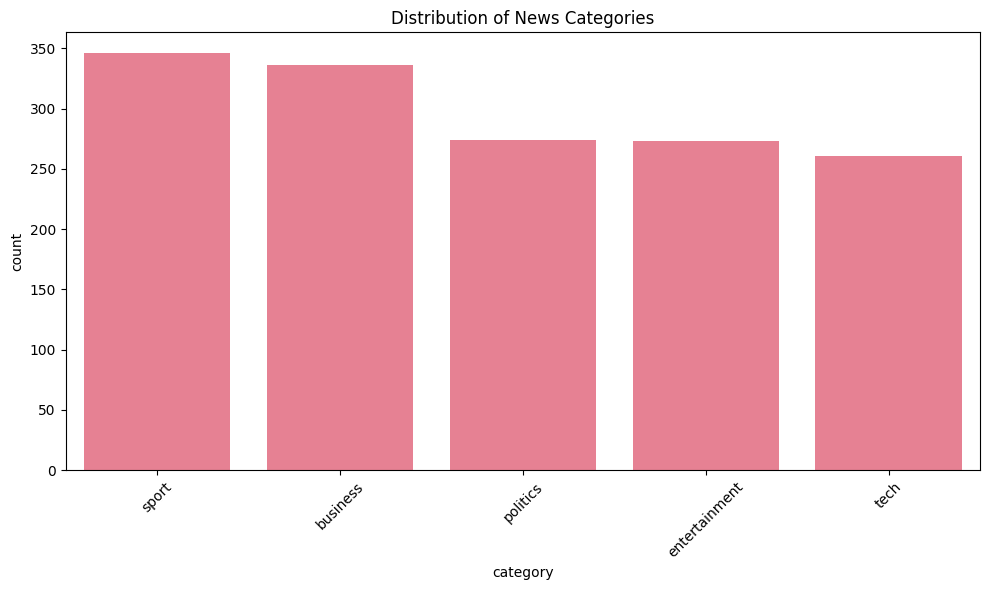


🔍 EXPLORATORY ANALYSIS (STUDENT TASK)

1️⃣ MISSING VALUES
--------------------------------------------------
            missing_count  missing_percent
article_id              0              0.0
content                 0              0.0
category                0              0.0
date                    0              0.0
source                  0              0.0
title                   0              0.0

Empty/whitespace-only articles: 0
✅ No missing or empty values found

2️⃣ TEXT LENGTH DISTRIBUTION
--------------------------------------------------
       char_count  word_count
count      1490.0      1490.0
mean       2233.5       385.0
std        1205.2       210.9
min         501.0        90.0
25%        1453.0       253.0
50%        1961.0       337.0
75%        2751.2       468.8
max       18387.0      3345.0

Average length by category:
              char_count         word_count       
                    mean  median       mean median
category                             

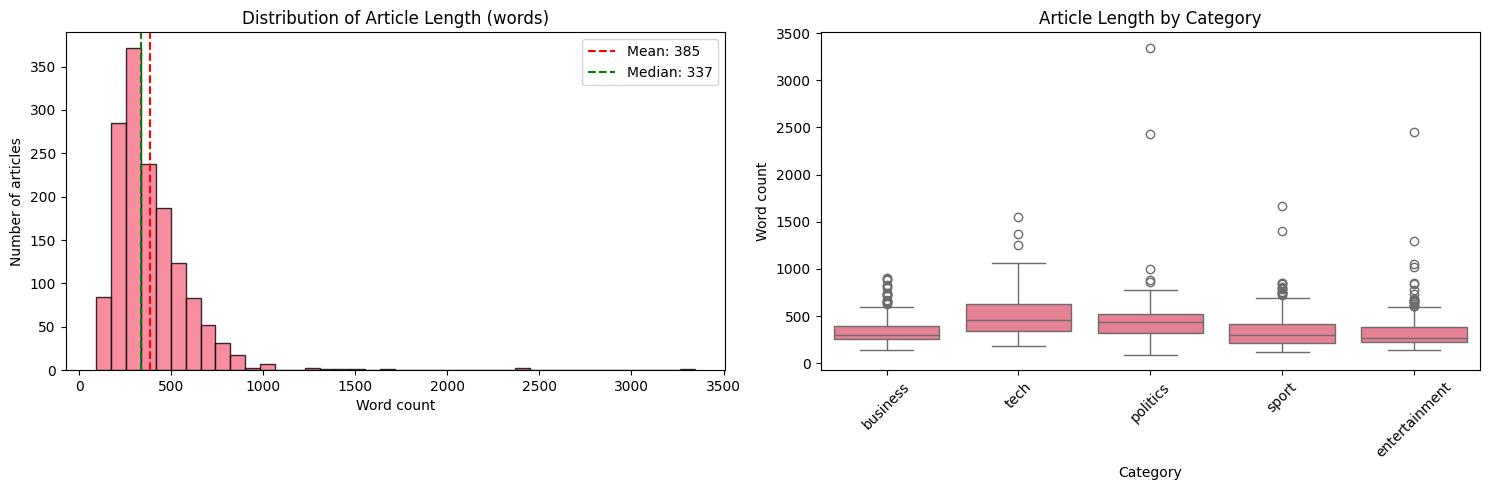


3️⃣ SOURCE DISTRIBUTION
--------------------------------------------------
source
BBC News    1490
Name: count, dtype: int64
⚠️ Only one source in the data (placeholder value), so a source comparison is not meaningful.

4️⃣ DATA QUALITY CHECKS
--------------------------------------------------
Duplicate article IDs: 0
Duplicate article texts: 50
Duplicate texts labeled with different categories: 0
Very short articles (under 50 words or below the IQR cutoff): 0
Unusually long articles (over 792 words): 49
Articles with non-ASCII characters: 435

Class imbalance ratio (largest / smallest category): 1.33
Largest category: sport (346)
Smallest category: tech (261)

📝 SUMMARY
--------------------------------------------------
• 1490 articles across 5 categories
• Average article length: 385 words (median 337)
• Missing values: 0, empty texts: 0
• Duplicates: 50 repeated texts
• 'date' and 'source' are placeholders, so they carry no real information


In [14]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique sources: {df['source'].nunique()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Examine source distribution
# - Look for any data quality issues

# ➕ ADDED: ================= STUDENT TASK ANALYSIS =================
print("\n" + "=" * 50)
print("🔍 EXPLORATORY ANALYSIS (STUDENT TASK)")
print("=" * 50)

# ➕ ADDED: 1) MISSING VALUES
print("\n1️⃣ MISSING VALUES")
print("-" * 50)
missing_df = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_percent': (df.isnull().sum() / len(df) * 100).round(2)
})
print(missing_df)

# Empty or whitespace-only text is not NaN, so isnull() misses it
empty_content = (df['content'].astype(str).str.strip() == '').sum()
print(f"\nEmpty/whitespace-only articles: {empty_content}")
if df.isnull().sum().sum() == 0 and empty_content == 0:
    print("✅ No missing or empty values found")

# ➕ ADDED: 2) TEXT LENGTH DISTRIBUTION
# 📝 NOTE: This adds char_count and word_count columns to df.
# They can be reused in later cells (e.g., as extra features).
print("\n2️⃣ TEXT LENGTH DISTRIBUTION")
print("-" * 50)
df['char_count'] = df['content'].astype(str).str.len()
df['word_count'] = df['content'].astype(str).str.split().str.len()

print(df[['char_count', 'word_count']].describe().round(1))

print("\nAverage length by category:")
length_by_category = df.groupby('category')[['char_count', 'word_count']].agg(['mean', 'median']).round(1)
print(length_by_category)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram of word counts, with mean and median lines
axes[0].hist(df['word_count'], bins=40, edgecolor='black', alpha=0.8)
axes[0].axvline(df['word_count'].mean(), color='red', linestyle='--',
                label=f"Mean: {df['word_count'].mean():.0f}")
axes[0].axvline(df['word_count'].median(), color='green', linestyle='--',
                label=f"Median: {df['word_count'].median():.0f}")
axes[0].set_title('Distribution of Article Length (words)')
axes[0].set_xlabel('Word count')
axes[0].set_ylabel('Number of articles')
axes[0].legend()

# Boxplot of word counts per category
sns.boxplot(data=df, x='category', y='word_count', ax=axes[1])
axes[1].set_title('Article Length by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Word count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# ➕ ADDED: 3) SOURCE DISTRIBUTION
# 📝 NOTE: In this dataset 'source' is a placeholder ('BBC News' for every row),
# so there is only one source and nothing real to compare.
print("\n3️⃣ SOURCE DISTRIBUTION")
print("-" * 50)
source_counts = df['source'].value_counts()
print(source_counts)
if df['source'].nunique() == 1:
    print("⚠️ Only one source in the data (placeholder value), so a source comparison is not meaningful.")
else:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, y='source', order=source_counts.index)
    plt.title('Articles per Source')
    plt.tight_layout()
    plt.show()

# ➕ ADDED: 4) DATA QUALITY CHECKS
print("\n4️⃣ DATA QUALITY CHECKS")
print("-" * 50)

# Duplicate IDs and duplicate article text
dup_ids = df['article_id'].duplicated().sum()
dup_content = df['content'].duplicated().sum()
print(f"Duplicate article IDs: {dup_ids}")
print(f"Duplicate article texts: {dup_content}")

# Duplicate text that appears under different categories would confuse a classifier
conflicting = df[df.duplicated(subset='content', keep=False)].groupby('content')['category'].nunique()
print(f"Duplicate texts labeled with different categories: {(conflicting > 1).sum()}")

# Very short and very long articles (outliers) using the IQR rule
q1, q3 = df['word_count'].quantile([0.25, 0.75])
iqr = q3 - q1
low_cut, high_cut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
short_articles = (df['word_count'] < max(low_cut, 50)).sum()
long_articles = (df['word_count'] > high_cut).sum()
print(f"Very short articles (under 50 words or below the IQR cutoff): {short_articles}")
print(f"Unusually long articles (over {high_cut:.0f} words): {long_articles}")

# Non-ASCII characters (currency symbols, curly quotes) may need cleaning later
non_ascii = df['content'].astype(str).str.contains(r'[^\x00-\x7F]', regex=True).sum()
print(f"Articles with non-ASCII characters: {non_ascii}")

# Class imbalance
imbalance_ratio = category_counts.max() / category_counts.min()
print(f"\nClass imbalance ratio (largest / smallest category): {imbalance_ratio:.2f}")
print(f"Largest category: {category_counts.idxmax()} ({category_counts.max()})")
print(f"Smallest category: {category_counts.idxmin()} ({category_counts.min()})")

# Summary
print("\n📝 SUMMARY")
print("-" * 50)
print(f"• {len(df)} articles across {df['category'].nunique()} categories")
print(f"• Average article length: {df['word_count'].mean():.0f} words (median {df['word_count'].median():.0f})")
print(f"• Missing values: {df.isnull().sum().sum()}, empty texts: {empty_content}")
print(f"• Duplicates: {dup_content} repeated texts")
print("• 'date' and 'source' are placeholders, so they carry no real information")

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

Preprocessing is important because computers don’t understand text the way we do, so if we leave it messy, the model treats “Apple,” “apple,” and “APPLE” like three different words. Cleaning the text, making it lowercase, removing stop words like “the” and “and,” and lemmatizing words like “running” to “run” gets rid of the noise and leaves the words that actually matter. If we skip these steps, the vocabulary gets huge, the word counts get split up, and the model can end up learning from random things like punctuation or capitalization instead of the real topic of the article. That usually means worse accuracy and less useful results. One thing I noticed is that some steps can also remove useful info, like “not” in sentiment analysis, so it’s best to keep the original text too and use the cleaned version only where it helps.

In [19]:
# html is used to convert entities like &amp; and &quot; into normal characters
import html
import re
import pandas as pd
import nltk

try:
    nltk.download('punkt_tab', quiet=True)
    nltk.download('omw-1.4', quiet=True)  # extra WordNet data some lemmatizer versions use
except Exception as e:
    print(f"Optional NLTK download skipped: {e}")

# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def expand_contractions(text):
    """Expand common English contractions (expects lowercase text)"""
    # Curly apostrophes (common in news text) -> straight apostrophes
    text = text.replace("’", "'").replace("‘", "'")
    # Irregular forms first
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bain't\b", "is not", text)
    # General patterns
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"'re\b", " are", text)
    text = re.sub(r"'ve\b", " have", text)
    text = re.sub(r"'ll\b", " will", text)
    text = re.sub(r"'d\b", " would", text)
    text = re.sub(r"'m\b", " am", text)
    # Possessive / "is" ('s) is ambiguous, so just drop it: "company's" -> "company"
    text = re.sub(r"'s\b", "", text)
    return text

def clean_text(text):
    """
    Comprehensive text cleaning function
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # Convert HTML entities (&amp;, &quot;, &#39;) BEFORE removing tags
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Expand contractions
    text = expand_contractions(text)

    # Remove numbers and special characters (leaving only letters and single spaces)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

  Preprocessing all articles...
✅ Preprocessing complete!

  BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers... worldcom ex-boss launches defence lawyers defending for...
Processed: worldcom bos launch defence lawyer worldcom bos launch defence lawyer defending former worldcom chie...

Example 2:
Original: german business confidence slides german... german business confidence slides german business confid...
Processed: german business confidence slide german german business confidence slide german business confidence ...

Example 3:
Original: bbc poll indicates economic gloom... bbc poll indicates economic gloom citizens in a majority of nat...
Processed: bbc poll indicates economic gloom bbc poll indicates economic gloom citizen majority nation surveyed...

  PREPROCESSING RESULTS ANALYSIS (STUDENT TASK)

1  AVERAGE TEXT LENGTH
------------------------------------------------------------
Average words per article: 390.0 -> 213.6 (45.2% reducti

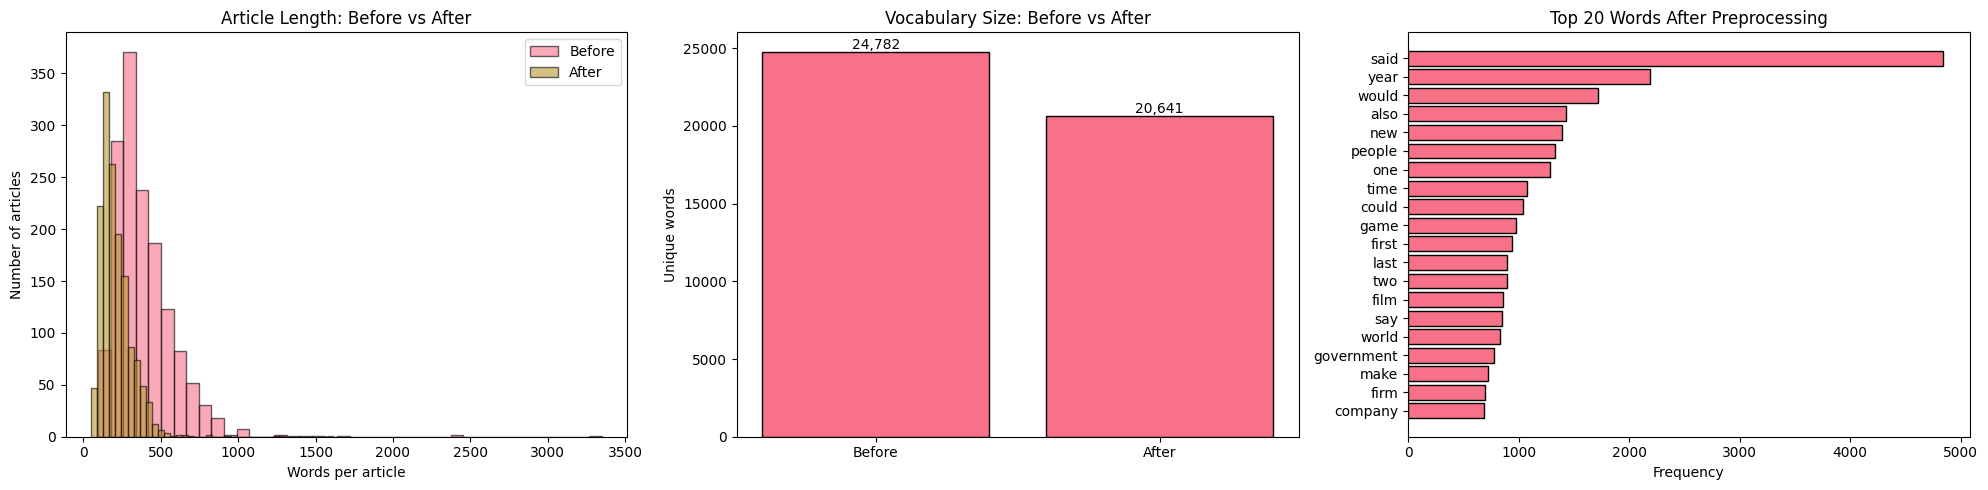


  SUMMARY
------------------------------------------------------------
• Average article length dropped from 390 to 214 words
• Vocabulary shrank from 24,782 to 20,641 unique words
• Most common word after preprocessing: 'said' (4,840 times)


In [20]:
# Define the missing preprocessing function
def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline
    """
    # Clean text using the clean_text function from previous cell
    text = clean_text(text)

    if not text:
        return ""

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Apply preprocessing to the dataset
print("  Preprocessing all articles...")

# Create new columns for processed text
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['title'] + ' ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n  BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

#   STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
# - Count unique words before and after
# - Identify the most common words after preprocessing

print("\n" + "=" * 60)
print("  PREPROCESSING RESULTS ANALYSIS (STUDENT TASK)")
print("=" * 60)

# 1) AVERAGE TEXT LENGTH BEFORE AND AFTER
# Note: "before" is the raw full_text, "after" is full_text_processed
print("\n1  AVERAGE TEXT LENGTH")
print("-" * 60)
before_words = df['full_text'].str.split().str.len()
after_words = df['full_text_processed'].str.split().str.len()
before_chars = df['full_text'].str.len()
after_chars = df['full_text_processed'].str.len()

print(f"Average words per article: {before_words.mean():.1f} -> {after_words.mean():.1f} "
      f"({(1 - after_words.mean() / before_words.mean()) * 100:.1f}% reduction)")
print(f"Average characters per article: {before_chars.mean():.1f} -> {after_chars.mean():.1f} "
      f"({(1 - after_chars.mean() / before_chars.mean()) * 100:.1f}% reduction)")
print(f"Median words per article: {before_words.median():.0f} -> {after_words.median():.0f}")

# Check for articles that became empty after processing (these would break later steps)
empty_processed = (df['full_text_processed'].str.strip() == '').sum()
print(f"Articles empty after preprocessing: {empty_processed}")

# 2) UNIQUE WORDS BEFORE AND AFTER
# Note: the raw text is lowercased and split on word boundaries so punctuation
# doesn't inflate the "before" count (otherwise "said," and "said" count as different words)
print("\n2  UNIQUE WORDS (VOCABULARY SIZE)")
print("-" * 60)
raw_tokens = re.findall(r'\b\w+\b', ' '.join(df['full_text'].astype(str)).lower())
processed_tokens = ' '.join(df['full_text_processed']).split()

unique_before = len(set(raw_tokens))
unique_after = len(set(processed_tokens))
print(f"Total words: {len(raw_tokens):,} -> {len(processed_tokens):,}")
print(f"Unique words: {unique_before:,} -> {unique_after:,} "
      f"({(1 - unique_after / unique_before) * 100:.1f}% reduction)")

# 3) MOST COMMON WORDS AFTER PREPROCESSING
print("\n3  MOST COMMON WORDS AFTER PREPROCESSING")
print("-" * 60)
word_freq = Counter(processed_tokens)
top_words = word_freq.most_common(20)
for rank, (word, count) in enumerate(top_words, 1):
    print(f"{rank:>2}. {word:<15} {count:,}")

# Most common words per category (shows which words separate the topics)
print("\n  TOP 8 WORDS PER CATEGORY")
print("-" * 60)
for category in df['category'].unique():
    cat_tokens = ' '.join(df.loc[df['category'] == category, 'full_text_processed']).split()
    cat_top = [word for word, _ in Counter(cat_tokens).most_common(8)]
    print(f"{category:<15} {', '.join(cat_top)}")

# VISUALIZATIONS
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Word count before vs after
axes[0].hist(before_words, bins=40, alpha=0.6, label='Before', edgecolor='black')
axes[0].hist(after_words, bins=40, alpha=0.6, label='After', edgecolor='black')
axes[0].set_title('Article Length: Before vs After')
axes[0].set_xlabel('Words per article')
axes[0].set_ylabel('Number of articles')
axes[0].legend()

# Unique words before vs after
axes[1].bar(['Before', 'After'], [unique_before, unique_after], edgecolor='black')
axes[1].set_title('Vocabulary Size: Before vs After')
axes[1].set_ylabel('Unique words')
for idx, value in enumerate([unique_before, unique_after]):
    axes[1].text(idx, value, f"{value:,}", ha='center', va='bottom')

# Top 20 words after preprocessing
words, counts = zip(*top_words)
axes[2].barh(list(words)[::-1], list(counts)[::-1], edgecolor='black')
axes[2].set_title('Top 20 Words After Preprocessing')
axes[2].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

# SUMMARY
print("\n  SUMMARY")
print("-" * 60)
print(f"• Average article length dropped from {before_words.mean():.0f} to {after_words.mean():.0f} words")
print(f"• Vocabulary shrank from {unique_before:,} to {unique_after:,} unique words")
print(f"• Most common word after preprocessing: '{top_words[0][0]}' ({top_words[0][1]:,} times)")

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [21]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1490, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.44%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0382
  company: 0.0354
  market: 0.0335
  bank: 0.0332
  growth: 0.0331
  share: 0.0319
  year: 0.0319
  economy: 0.0314
  sale: 0.0311
  profit: 0.0286

📰 TECH:
  mobile: 0.0548
  phone: 0.0461
  people: 0.0439
  technology: 0.0390
  game: 0.0378
  user: 0.0366
  service: 0.0356
  software: 0.0343
  computer: 0.0330
  net: 0.0328

📰 POLITICS:
  labour: 0.0650
  election: 0.0635
  blair: 0.0583
  party: 0.0521
  tory: 0.0480
  would: 0.0438
  government: 0.0438
  minister: 0.0414
  brown: 0.0394
  tax: 0.0323

📰 SPORT:
  game: 0.0425
  england: 0.0372
  win: 0.0331
  player: 0.0306
  match: 0.0302
  cup: 0.0276
  champion: 0.0270
  team: 0.0264
  final: 0.0255
  chelsea: 0.0251

📰 ENTERTAINMENT:
  film: 0.1002
  award: 0.0509
  best: 0.0460
  star: 0.0399
  show: 0.0368
  music: 0.0352
  actor: 0.0332
  band: 0.0332
  oscar: 0.0327
  year: 0.0302

📊 TF-IDF VISUALIZATIONS (STUDENT TASK)


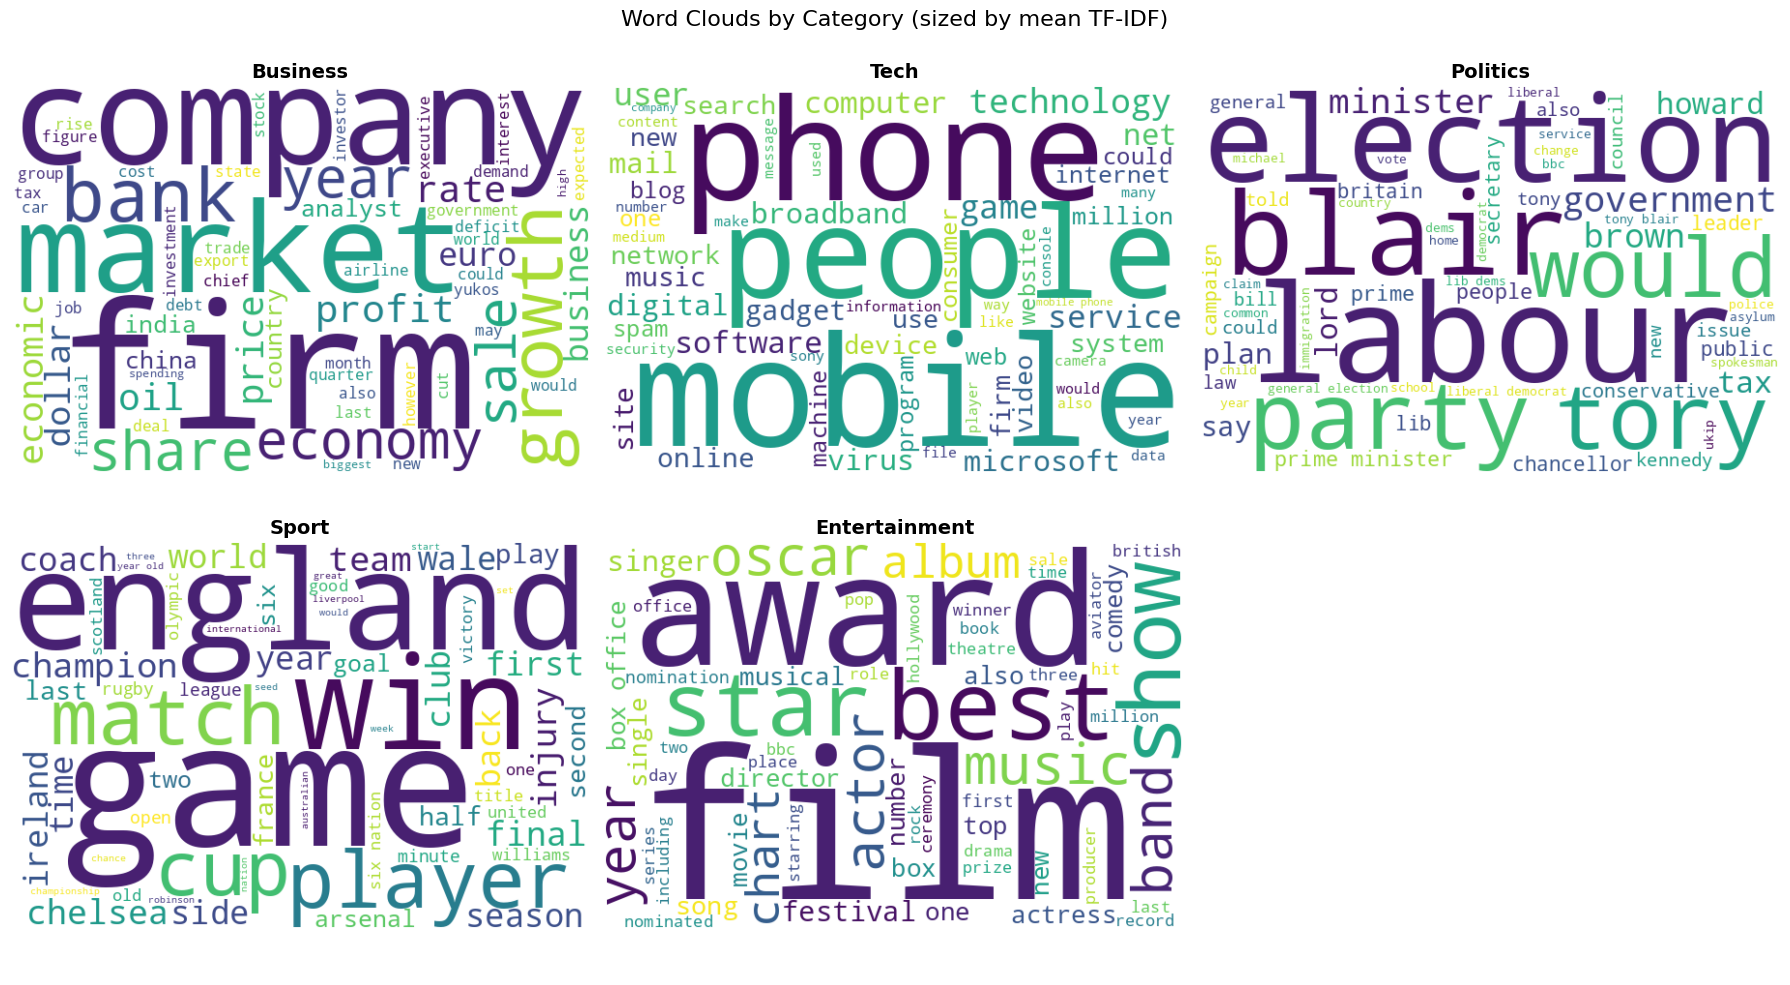

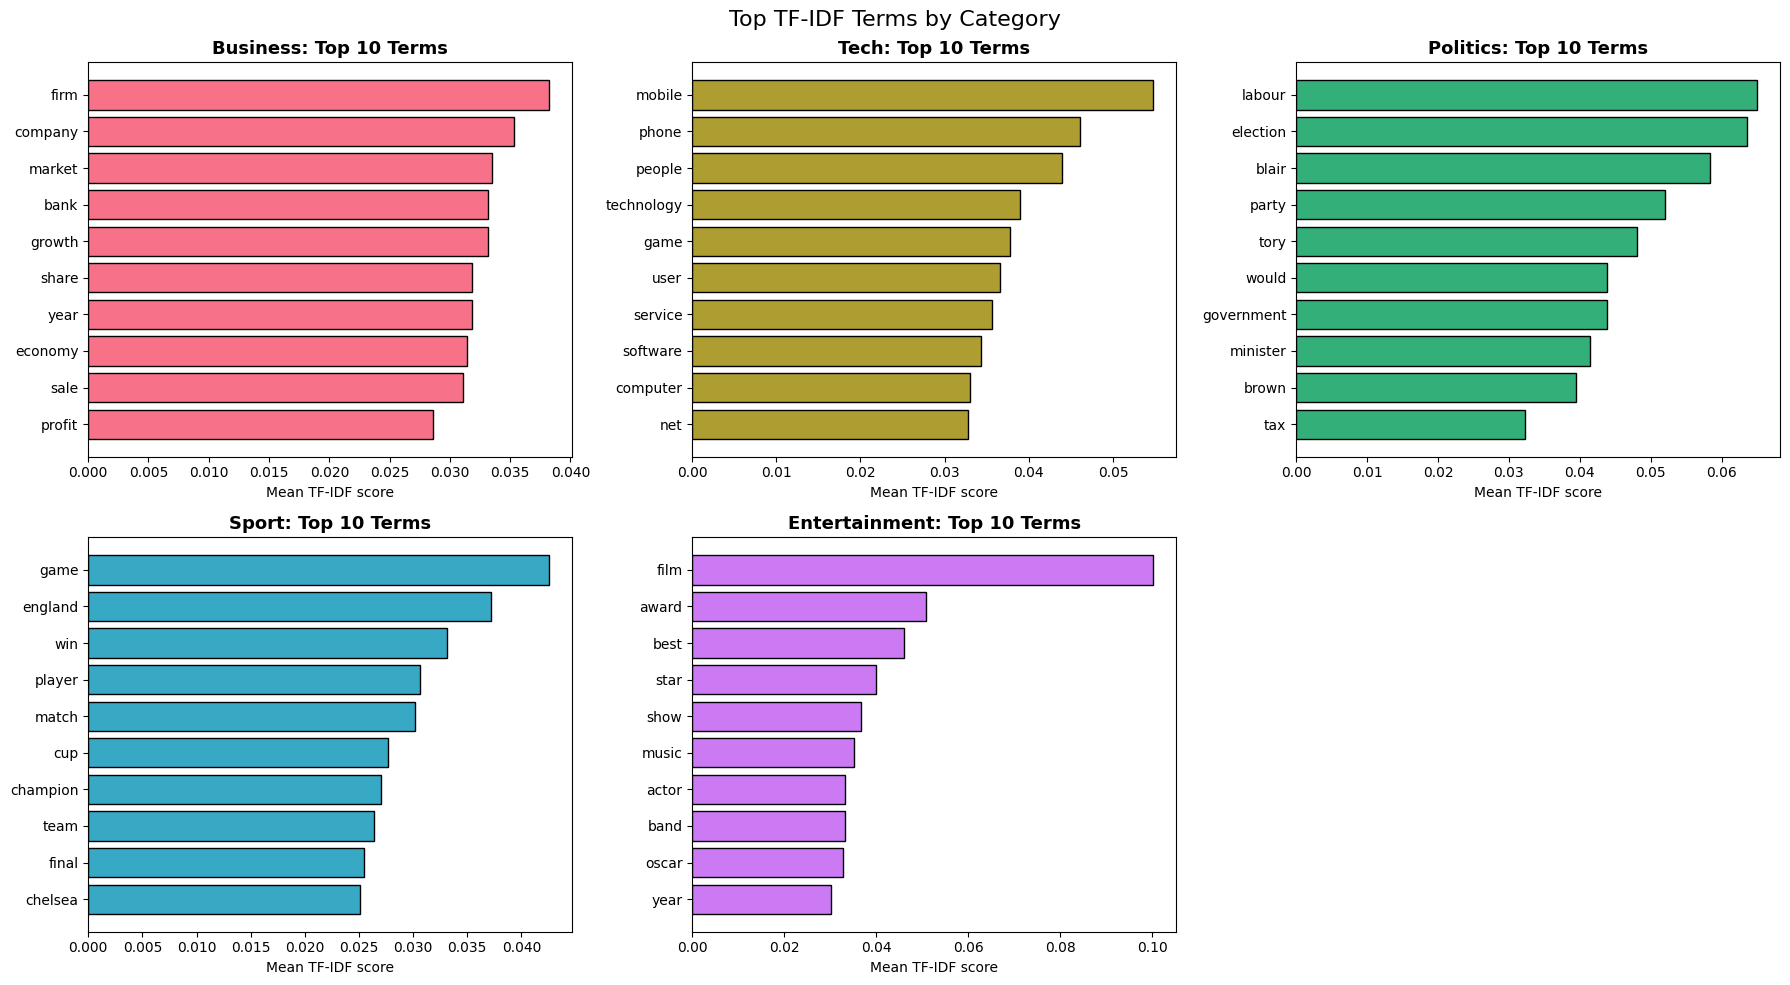

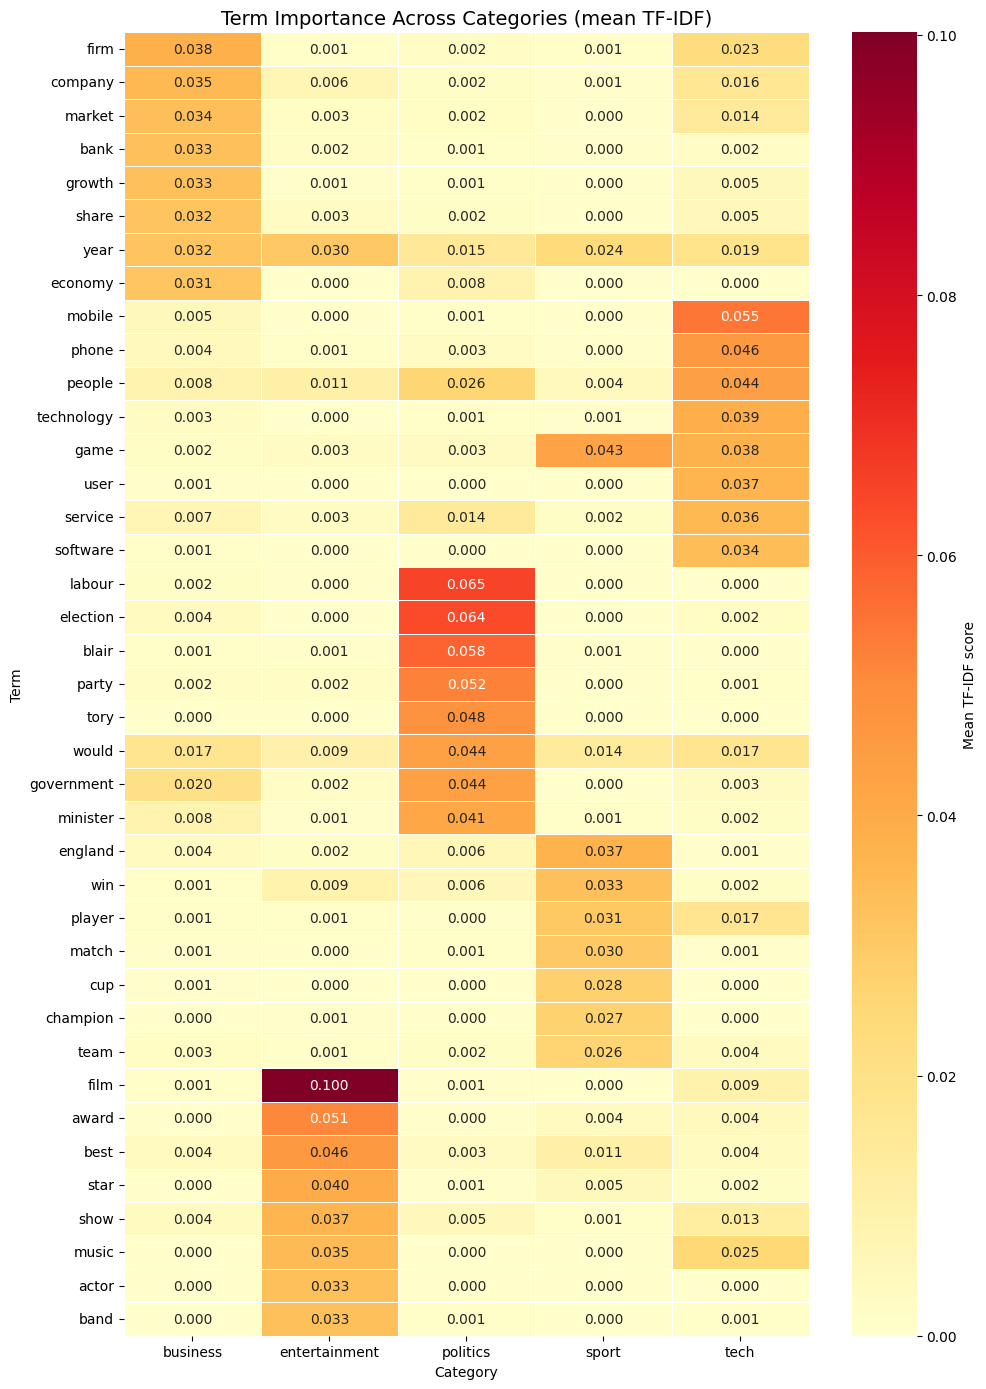


🔎 Top-10 terms that also appear in another category's top 10:
  business: 1
  tech: 1
  politics: 0
  sport: 1
  entertainment: 1


In [22]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

print("\n" + "=" * 50)
print("📊 TF-IDF VISUALIZATIONS (STUDENT TASK)")
print("=" * 50)

# Mean TF-IDF score of every term for every category (rows = categories, columns = terms).
# This is reused by the word clouds and the heatmap below.
category_means = tfidf_df.groupby('category').mean()

# Grid layout shared by the word clouds and bar charts: 2 rows x 3 columns.
# With 5 categories, the 6th panel is left empty and hidden.
n_cols = 3
n_rows = int(np.ceil(len(categories) / n_cols))

# 1) WORD CLOUDS FOR EACH CATEGORY
# The size of each word reflects its mean TF-IDF score in that category.
# Using the top 60 terms keeps the clouds readable.
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 10))
axes = axes.flatten()

for idx, category in enumerate(categories):
    top_scores = category_means.loc[category].sort_values(ascending=False).head(60)
    wc = WordCloud(
        width=600, height=400,
        background_color='white',
        colormap='viridis',
        random_state=42
    ).generate_from_frequencies(top_scores.to_dict())

    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f"{category.title()}", fontsize=14, fontweight='bold')
    axes[idx].axis('off')

# Hide any unused panels
for idx in range(len(categories), len(axes)):
    axes[idx].axis('off')

plt.suptitle('Word Clouds by Category (sized by mean TF-IDF)', fontsize=16)
plt.tight_layout()
plt.show()

# 2) BAR CHARTS OF TOP TERMS
# Uses the category_terms dictionary already built above (top 10 terms per category).
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 10))
axes = axes.flatten()
palette = sns.color_palette("husl", len(categories))

for idx, category in enumerate(categories):
    terms = category_terms[category]
    # Reverse the order so the highest score appears at the top of the chart
    axes[idx].barh(list(terms.index)[::-1], list(terms.values)[::-1],
                   color=palette[idx], edgecolor='black')
    axes[idx].set_title(f"{category.title()}: Top 10 Terms", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('Mean TF-IDF score')

for idx in range(len(categories), len(axes)):
    axes[idx].axis('off')

plt.suptitle('Top TF-IDF Terms by Category', fontsize=16)
plt.tight_layout()
plt.show()

# 3) HEATMAP OF TERM IMPORTANCE ACROSS CATEGORIES
# Take the top 8 terms of each category, combine them (duplicates removed),
# then show every category's mean score for those terms.
# A term that is bright in one column and dark in the others is a strong category marker.
heatmap_terms = []
for category in categories:
    for term in category_means.loc[category].sort_values(ascending=False).head(8).index:
        if term not in heatmap_terms:
            heatmap_terms.append(term)

heatmap_data = category_means[heatmap_terms].T  # rows = terms, columns = categories

plt.figure(figsize=(10, 14))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='.3f',
            linewidths=0.5, cbar_kws={'label': 'Mean TF-IDF score'})
plt.title('Term Importance Across Categories (mean TF-IDF)', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Term')
plt.tight_layout()
plt.show()

# Quick takeaway: how many of the top terms are unique to a single category
overlap_counts = {}
for category in categories:
    own = set(category_terms[category].index)
    others = set().union(*[set(category_terms[c].index) for c in categories if c != category])
    overlap_counts[category] = len(own & others)
print("\n🔎 Top-10 terms that also appear in another category's top 10:")
for category, count in overlap_counts.items():
    print(f"  {category}: {count}")

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN         :        RB       VBG        IN  \
0  0.090062  0.118012  0.229814  0.003106  0.031056  0.024845  0.108696   
1  0.126437  0.068966  0.235632  0.002874  0.034483  0.031609  0.132184   
2  0.080000  0.078182  0.203636  0.003636  0.032727  0.025455  0.118182   
3  0.085799  0.107988  0.156805  0.004438  0.056213  0.022189  0.121302   
4  0.087404  0.079692  0.213368  0.007712  0.033419  0.028278  0.123393   

         DT       VBP       VBN  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.065217  0.015528  0.040373  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.080460  0.014368  0.028736  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.094545  0.016364  0.029091  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.062130  0.041420  0.017751  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.100257  0.015424  0.025707  ...

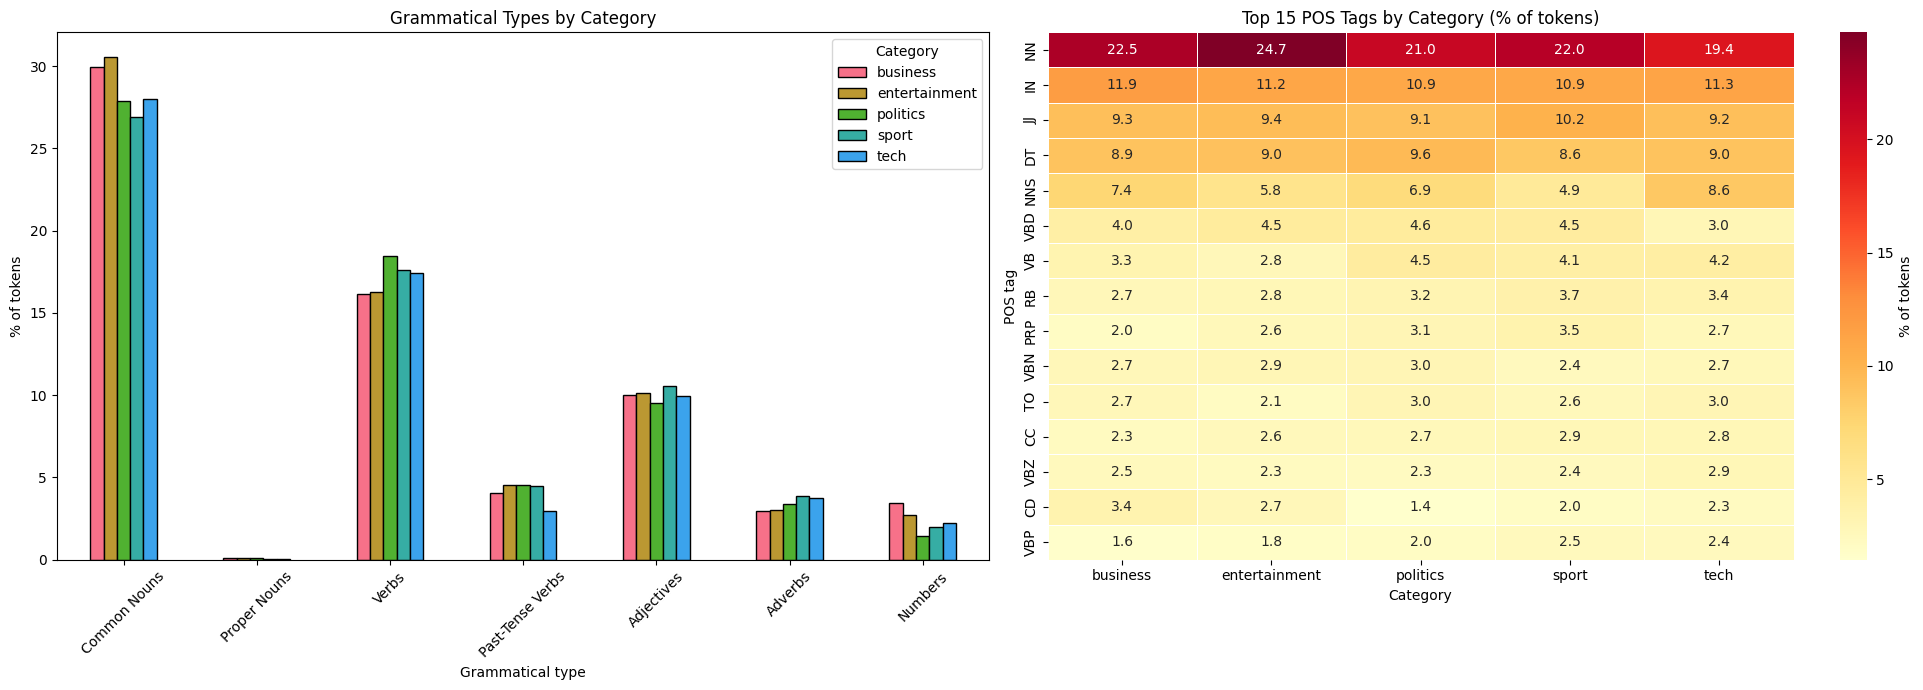


💡 HYPOTHESIS CHECK
------------------------------------------------------------
Most verbs:            politics
Most past-tense verbs: politics
Most numbers:          business
Most proper nouns:     business

Sports have the most (past-tense) verbs: ❌ not supported
Business has the most numbers:           ✅ supported
Business has the most proper nouns:      ✅ supported


In [24]:
# Newer NLTK versions need this tagger data. Safe to run even if it's already downloaded.
try:
    nltk.download('averaged_perceptron_tagger_eng', quiet=True)
except Exception as e:
    print(f"Optional NLTK download skipped: {e}")

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

print("\n" + "=" * 60)
print("🔍 POS PATTERN COMPARISON BY CATEGORY")
print("=" * 60)

# Group the detailed Penn Treebank tags into broader grammatical types.
# Each group is the sum of its tag proportions, so values are shares of an article's tokens.
pos_groups = {
    'Common Nouns': ['NN', 'NNS'],
    'Proper Nouns': ['NNP', 'NNPS'],
    'Verbs': ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'],
    'Past-Tense Verbs': ['VBD'],
    'Adjectives': ['JJ', 'JJR', 'JJS'],
    'Adverbs': ['RB', 'RBR', 'RBS'],
    'Numbers': ['CD']
}

for group_name, tags in pos_groups.items():
    # Only sum tags that actually appear in the data, so a missing tag doesn't cause a KeyError
    existing_tags = [t for t in tags if t in pos_df.columns]
    pos_df[group_name] = pos_df[existing_tags].sum(axis=1)

# Average share (as a percentage) of each grammatical type, per category
pos_summary = (pos_df.groupby('category')[list(pos_groups.keys())].mean() * 100).round(2)
print("\n📊 Average % of tokens by grammatical type:")
print(pos_summary)

# Which category scores highest on each type
print("\n🏆 Highest category for each type:")
for group_name in pos_groups:
    top_cat = pos_summary[group_name].idxmax()
    print(f"  {group_name:<18} {top_cat} ({pos_summary[group_name].max():.2f}%)")

# VISUALIZATIONS
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Grouped bar chart: grammatical types compared across categories
pos_summary.T.plot(kind='bar', ax=axes[0], edgecolor='black')
axes[0].set_title('Grammatical Types by Category')
axes[0].set_xlabel('Grammatical type')
axes[0].set_ylabel('% of tokens')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Category')

# Heatmap of the 15 most common individual tags (punctuation tags removed)
tag_cols = [c for c in pos_df.columns
            if c not in ['category', 'article_id'] and c not in pos_groups and c.isalpha()]
top_tags = pos_df[tag_cols].mean().sort_values(ascending=False).head(15).index
tag_means = (pos_df.groupby('category')[list(top_tags)].mean() * 100).T
sns.heatmap(tag_means, cmap='YlOrRd', annot=True, fmt='.1f', linewidths=0.5,
            cbar_kws={'label': '% of tokens'}, ax=axes[1])
axes[1].set_title('Top 15 POS Tags by Category (% of tokens)')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('POS tag')

plt.tight_layout()
plt.show()

# HYPOTHESIS CHECK
# Hypothesis: sports articles have more action verbs, business articles have more numbers and proper nouns
print("\n💡 HYPOTHESIS CHECK")
print("-" * 60)
top_verbs = pos_summary['Verbs'].idxmax()
top_past = pos_summary['Past-Tense Verbs'].idxmax()
top_numbers = pos_summary['Numbers'].idxmax()
top_proper = pos_summary['Proper Nouns'].idxmax()

print(f"Most verbs:            {top_verbs}")
print(f"Most past-tense verbs: {top_past}")
print(f"Most numbers:          {top_numbers}")
print(f"Most proper nouns:     {top_proper}")

sports_verbs = str(top_verbs).lower().startswith('sport') or str(top_past).lower().startswith('sport')
business_numbers = str(top_numbers).lower().startswith('business')
business_proper = str(top_proper).lower().startswith('business')

print(f"\nSports have the most (past-tense) verbs: {'✅ supported' if sports_verbs else '❌ not supported'}")
print(f"Business has the most numbers:           {'✅ supported' if business_numbers else '❌ not supported'}")
print(f"Business has the most proper nouns:      {'✅ supported' if business_proper else '❌ not supported'}")

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
business       0.2254  0.0742  0.0011  0.0000  0.0331  0.0403  0.0199  0.0273   
entertainment  0.2472  0.0580  0.0008  0.0000  0.0280  0.0455  0.0191  0.0292   
politics       0.2100  0.0687  0.0007  0.0003  0.0453  0.0457  0.0207  0.0300   
sport          0.2200  0.0488  0.0005  0.0000  0.0407  0.0451  0.0174  0.0244   
tech           0.1943  0.0859  0.0006  0.0000  0.0418  0.0297  0.0235  0.0267   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
business       0.0161  0.0245  0.0926  0.0045  0.0032  0.0273  0.0017  0.0006   
entertainment  0.0184  0.0227  0.0940  0.0024  0.0050  0.0283  0.0010  0.0009   
politics       0.0200  0.0227  0.0906  0.0032  0

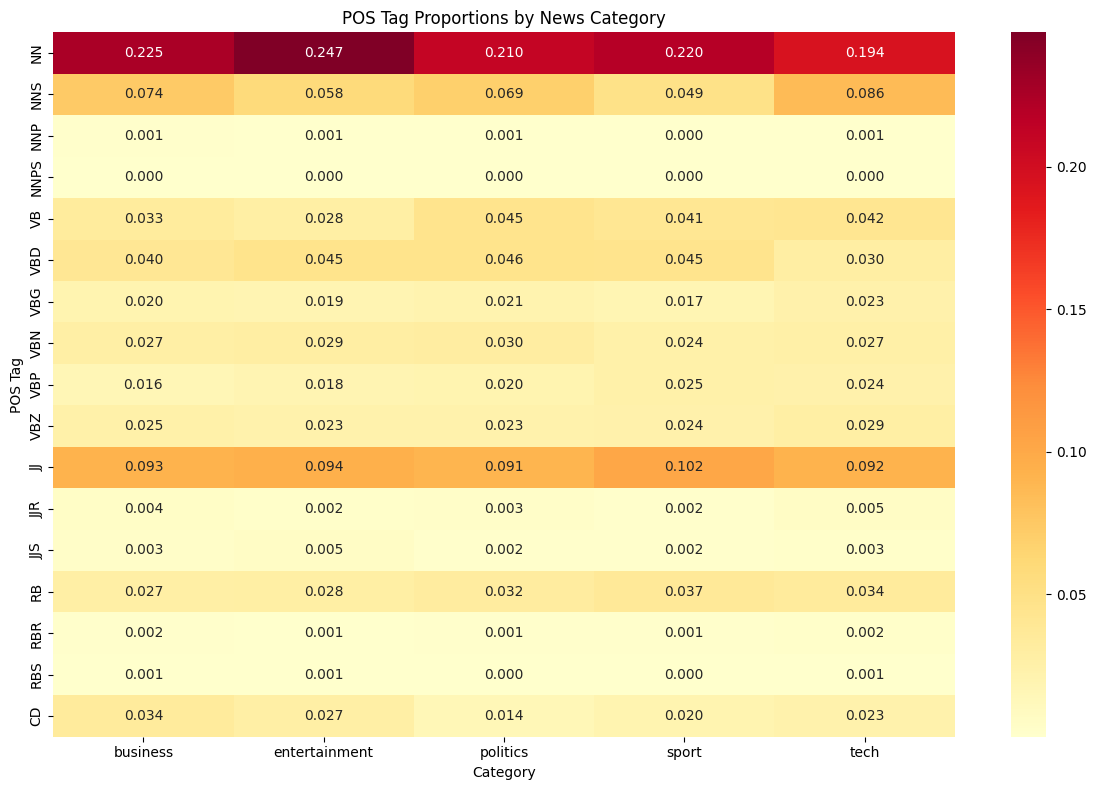


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?

🔍 PATTERN ANALYSIS (STUDENT TASK)

📊 Summary table (average % of tokens per category):
               Nouns %  Verbs %  Proper nouns %  Action verbs %  Adjectives %  \
category                                                                        
business         30.08    16.13            0.11            9.34         10.03   
entertainment    30.59    16.29            0.08            9.25         10.14   
politics         27.97    18.45            0.10           11.18          9.54   
sport            26.92    17.62            0.05           10.32         10.56   
tech             28.09    17.40            0.06            9.49          9.95   

               Numbers %  Noun/verb ratio  
category                      

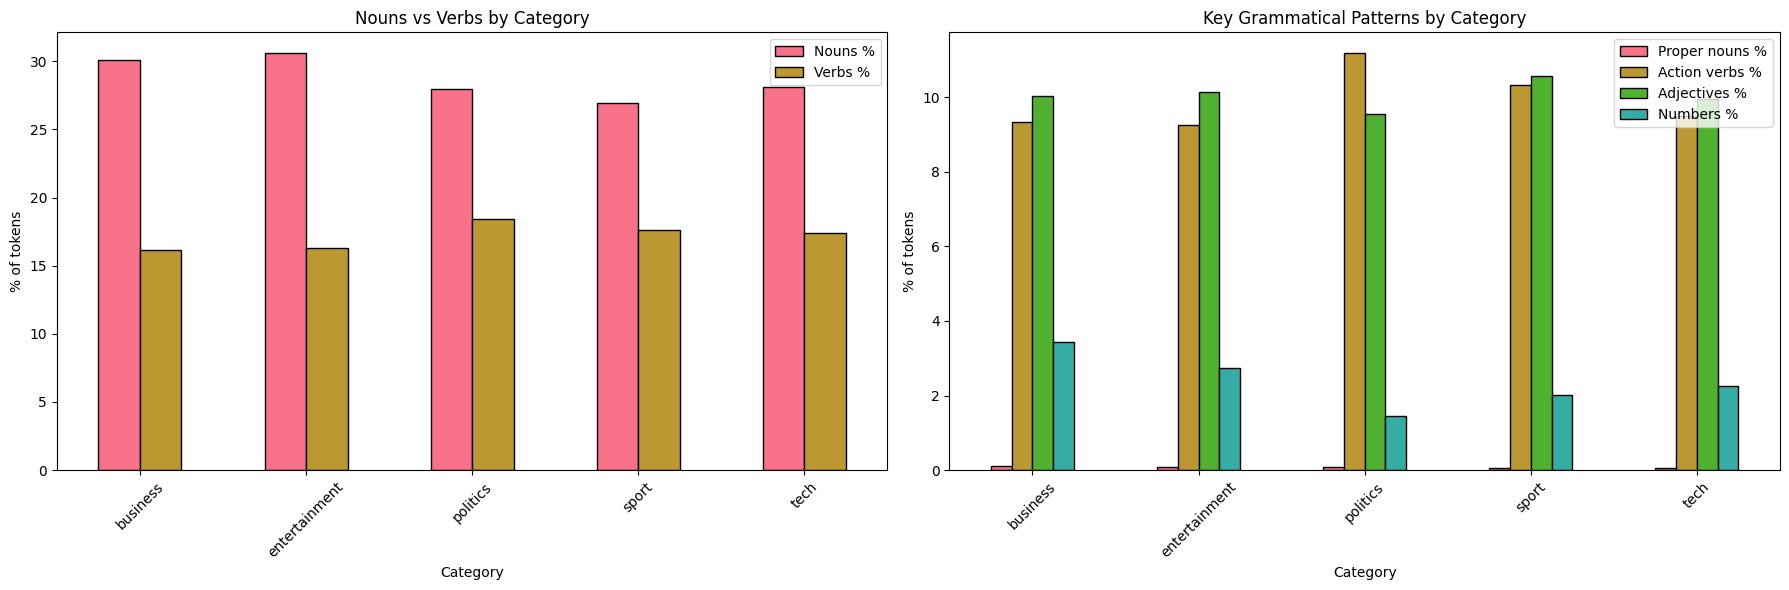


💡 HYPOTHESIS CHECK
--------------------------------------------------
Sports have the most action verbs:  ❌ not supported (highest: politics)
Business has the most numbers:      ✅ supported (highest: business)
Business has the most proper nouns: ✅ supported (highest: business)


In [25]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")

    print("\n" + "=" * 50)
    print("🔍 PATTERN ANALYSIS (STUDENT TASK)")
    print("=" * 50)

    # Helper: average share (in %) of a group of tags for each category.
    # Only tags that exist in the data are summed, so a missing tag can't cause a KeyError.
    def group_share(tags):
        existing = [t for t in tags if t in pos_summary.columns]
        return pos_summary[existing].sum(axis=1) * 100

    analysis_table = pd.DataFrame({
        'Nouns %': group_share(['NN', 'NNS', 'NNP', 'NNPS']),
        'Verbs %': group_share(['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ']),
        'Proper nouns %': group_share(['NNP', 'NNPS']),
        'Action verbs %': group_share(['VB', 'VBD', 'VBG']),
        'Adjectives %': group_share(['JJ', 'JJR', 'JJS']),
        'Numbers %': group_share(['CD'])
    })
    analysis_table['Noun/verb ratio'] = analysis_table['Nouns %'] / analysis_table['Verbs %']

    print("\n📊 Summary table (average % of tokens per category):")
    print(analysis_table.round(2))

    # Nouns vs verbs
    print("\n1️⃣ NOUNS vs VERBS")
    print("-" * 50)
    for cat in analysis_table['Noun/verb ratio'].sort_values(ascending=False).index:
        print(f"  {cat:<15} nouns {analysis_table.loc[cat, 'Nouns %']:.1f}%  |  "
              f"verbs {analysis_table.loc[cat, 'Verbs %']:.1f}%  |  "
              f"ratio {analysis_table.loc[cat, 'Noun/verb ratio']:.2f}")
    print(f"  ➜ Most noun-heavy: {analysis_table['Noun/verb ratio'].idxmax()}")
    print(f"  ➜ Most verb-heavy: {analysis_table['Noun/verb ratio'].idxmin()}")

    # Answers to the four analysis questions
    questions = [
        ("2️⃣ Q1: PROPER NOUNS (NNP/NNPS)", 'Proper nouns %'),
        ("3️⃣ Q2: ACTION VERBS (VB, VBD, VBG)", 'Action verbs %'),
        ("4️⃣ Q3: ADJECTIVES (JJ, JJR, JJS)", 'Adjectives %'),
        ("5️⃣ Q4: NUMBERS (CD)", 'Numbers %')
    ]
    for title, column in questions:
        print(f"\n{title}")
        print("-" * 50)
        ranked = analysis_table[column].sort_values(ascending=False)
        for cat, value in ranked.items():
            print(f"  {cat:<15} {value:.2f}%")
        gap = ranked.iloc[0] - ranked.iloc[-1]
        print(f"  ➜ Highest: {ranked.index[0]} | Lowest: {ranked.index[-1]} | Gap: {gap:.2f} percentage points")

    # Visualization of the four question metrics plus nouns vs verbs
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    analysis_table[['Nouns %', 'Verbs %']].plot(kind='bar', ax=axes[0], edgecolor='black')
    axes[0].set_title('Nouns vs Verbs by Category')
    axes[0].set_xlabel('Category')
    axes[0].set_ylabel('% of tokens')
    axes[0].tick_params(axis='x', rotation=45)

    analysis_table[['Proper nouns %', 'Action verbs %', 'Adjectives %', 'Numbers %']].plot(
        kind='bar', ax=axes[1], edgecolor='black')
    axes[1].set_title('Key Grammatical Patterns by Category')
    axes[1].set_xlabel('Category')
    axes[1].set_ylabel('% of tokens')
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    # Check the hypothesis from the start of the module.
    # Category labels are lowercase in this dataset, so match case-insensitively.
    print("\n💡 HYPOTHESIS CHECK")
    print("-" * 50)
    top_action = analysis_table['Action verbs %'].idxmax()
    top_numbers = analysis_table['Numbers %'].idxmax()
    top_proper = analysis_table['Proper nouns %'].idxmax()
    print(f"Sports have the most action verbs:  {'✅ supported' if 'sport' in str(top_action).lower() else '❌ not supported'} (highest: {top_action})")
    print(f"Business has the most numbers:      {'✅ supported' if 'business' in str(top_numbers).lower() else '❌ not supported'} (highest: {top_numbers})")
    print(f"Business has the most proper nouns: {'✅ supported' if 'business' in str(top_proper).lower() else '❌ not supported'} (highest: {top_proper})")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 16
  Tokens: 354
  Noun phrases: ['worldcom ex', '-', 'boss']...
  Subjects: ['ex', '-', 'boss']...
  Objects: ['lawyers', 'ebbers', 'battery']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 374
  Noun phrases: ['german business confidence', 'german business confidence', 'german business confidence']...
  Subjects: ['confidence', 'confidence', 'slides']...
  Objects: ['german', 'confidence', 'february']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 593
  Noun phrases: ['bbc poll', 'economic gloom', 'bbc poll']...
  Subjects: ['poll', 'poll', 'citizens']...
  Objects: ['gloom', 'majority', 'nations']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 730
  Noun phrases: ['mobile choice', 'faster  better or funkier hardware', 'phone firms']...
  Subjects: ['governs', 'firms', 'firms']...
  Objects: ['choice', 'hardware', 'research']...

📰 Article 5 (business):
  Sentences

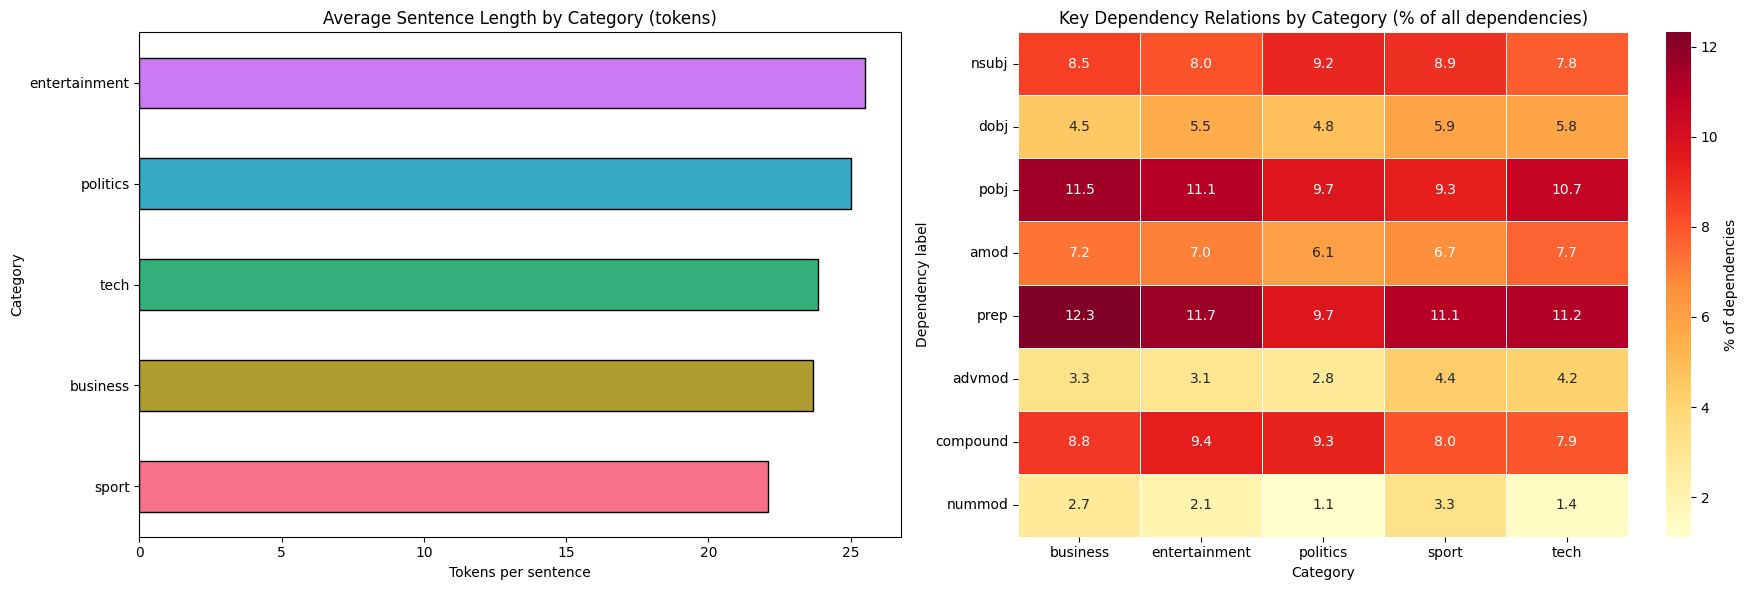


💡 TAKEAWAYS
------------------------------------------------------------
Longest sentences:  entertainment (25.5 tokens)
Shortest sentences: sport (22.1 tokens)
Most numeric modifiers (nummod): sport
Most adjective modifiers (amod): tech


In [26]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # Subject-verb-object triples: (who, did what, to whom/what)
    features['svo_triples'] = []

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Extract verb phrases: the main verb plus its auxiliaries, negation, and particles
    # Example: "has not been announced" or "pulled out"
    for token in doc:
        if token.pos_ == 'VERB':
            parts = [token] + [c for c in token.children if c.dep_ in ('aux', 'auxpass', 'neg', 'prt')]
            parts = sorted(parts, key=lambda t: t.i)  # keep original word order
            features['verb_phrases'].append(' '.join(t.text.lower() for t in parts))

    # Extract subject-verb-object triples ("who did what to whom")
    # Helper: include compound words so "Tim Cook" is not reduced to just "cook"
    def full_name(tok):
        compounds = [c for c in tok.children if c.dep_ == 'compound']
        parts = sorted(compounds + [tok], key=lambda t: t.i)
        return ' '.join(t.text.lower() for t in parts)

    for token in doc:
        if token.pos_ == 'VERB':
            subjects = [c for c in token.children if c.dep_ in ('nsubj', 'nsubjpass')]
            objects = [c for c in token.children if c.dep_ == 'dobj']
            for s in subjects:
                for o in objects:
                    features['svo_triples'].append((full_name(s), token.lemma_.lower(), full_name(o)))

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

# Verb phrases and subject-verb-object triples for the same 5 articles
print("\n🔗 VERB PHRASES AND 'WHO DID WHAT TO WHOM' (first 5 articles)")
print("-" * 60)
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Verb phrases: {result['verb_phrases'][:5]}...")
    print(f"  SVO triples: {result['svo_triples'][:3]}")

# Compare syntactic patterns across categories
# The demo above only covers 5 articles, so here we take 10 articles per category
# (50 total) to keep the runtime reasonable. Increase the 10 for a bigger sample.
print("\n" + "=" * 60)
print("🔍 SYNTACTIC COMPARISON BY CATEGORY")
print("=" * 60)

sample_df = df.groupby('category').head(10)
print(f"Analyzing {len(sample_df)} articles across {sample_df['category'].nunique()} categories...")

category_results = []
for idx, row in sample_df.iterrows():
    f = extract_syntactic_features(row['full_text'])
    if not f:
        continue
    f['category'] = row['category']
    category_results.append(f)

# Key dependency labels to compare (as % of all dependencies in an article)
# nsubj = subject, dobj = direct object, pobj = object of a preposition, amod = adjective modifier,
# prep = preposition, advmod = adverb modifier, compound = noun compound, nummod = number modifier
key_deps = ['nsubj', 'dobj', 'pobj', 'amod', 'prep', 'advmod', 'compound', 'nummod']

article_rows = []
for f in category_results:
    total_deps = max(sum(f['dependency_counts'].values()), 1)
    row_data = {
        'category': f['category'],
        'avg_sentence_length': f['num_tokens'] / max(f['num_sentences'], 1),
        'noun_phrases_per_sentence': len(f['noun_phrases']) / max(f['num_sentences'], 1),
        'verb_phrases_per_sentence': len(f['verb_phrases']) / max(f['num_sentences'], 1),
        'svo_triples_per_article': len(f['svo_triples'])
    }
    for dep in key_deps:
        row_data[dep] = f['dependency_counts'].get(dep, 0) / total_deps * 100
    article_rows.append(row_data)

syntax_df = pd.DataFrame(article_rows)
syntax_summary = syntax_df.groupby('category').mean().round(2)

print("\n📊 Average syntactic features per category:")
print(syntax_summary[['avg_sentence_length', 'noun_phrases_per_sentence',
                      'verb_phrases_per_sentence', 'svo_triples_per_article']])

# Most common subjects and verbs per category (pronouns removed so real entities show up)
pronouns = {'he', 'she', 'it', 'they', 'we', 'i', 'you', 'who', 'which', 'that', 'this', 'there'}
print("\n🏷️ TOP SUBJECTS AND ACTIONS BY CATEGORY")
print("-" * 60)
for category in sorted(syntax_summary.index):
    cat_results = [f for f in category_results if f['category'] == category]
    all_subjects = [s for f in cat_results for s in f['subjects'] if s not in pronouns]
    all_verbs = [t[1] for f in cat_results for t in f['svo_triples']]
    all_triples = [t for f in cat_results for t in f['svo_triples']]
    print(f"\n{category.upper()}")
    print(f"  Top subjects: {[w for w, _ in Counter(all_subjects).most_common(5)]}")
    print(f"  Top actions:  {[w for w, _ in Counter(all_verbs).most_common(5)]}")
    print(f"  Example triples: {all_triples[:2]}")

# VISUALIZATIONS
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Sentence length by category (a simple measure of writing complexity)
syntax_summary['avg_sentence_length'].sort_values().plot(
    kind='barh', ax=axes[0], edgecolor='black', color=sns.color_palette("husl", len(syntax_summary)))
axes[0].set_title('Average Sentence Length by Category (tokens)')
axes[0].set_xlabel('Tokens per sentence')
axes[0].set_ylabel('Category')

# Heatmap of key dependency relations across categories
sns.heatmap(syntax_summary[key_deps].T, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': '% of dependencies'}, ax=axes[1])
axes[1].set_title('Key Dependency Relations by Category (% of all dependencies)')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Dependency label')

plt.tight_layout()
plt.show()

# Quick takeaways
print("\n💡 TAKEAWAYS")
print("-" * 60)
print(f"Longest sentences:  {syntax_summary['avg_sentence_length'].idxmax()} "
      f"({syntax_summary['avg_sentence_length'].max():.1f} tokens)")
print(f"Shortest sentences: {syntax_summary['avg_sentence_length'].idxmin()} "
      f"({syntax_summary['avg_sentence_length'].min():.1f} tokens)")
print(f"Most numeric modifiers (nummod): {syntax_summary['nummod'].idxmax()}")
print(f"Most adjective modifiers (amod): {syntax_summary['amod'].idxmax()}")

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b


🔍 EXTENDED SYNTACTIC ANALYSIS (STUDENT TASK)

📝 First sentence only: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  



⚙️ Parsing 200 articles (40 per category)...
✅ Parsing complete!

1️⃣ SYNTACTIC COMPLEXITY BY CATEGORY
------------------------------------------------------------
               avg_sentence_length  avg_tree_depth  clauses_per_sentence  \
category                                                                   
business                     22.35            6.39                  1.51   
entertainment                21.40            5.86                  1.33   
politics                     22.14            6.28                  1.80   
sport                        19.23            5.34                  1.37   
tech                         22.19            6.36                  1.69   

               noun_phrases_per_sentence  passive_share  
category                                                 
business                            5.70           8.89  
entertainment                       5.49          15.04  
politics                            5.84          10.96  
sport       

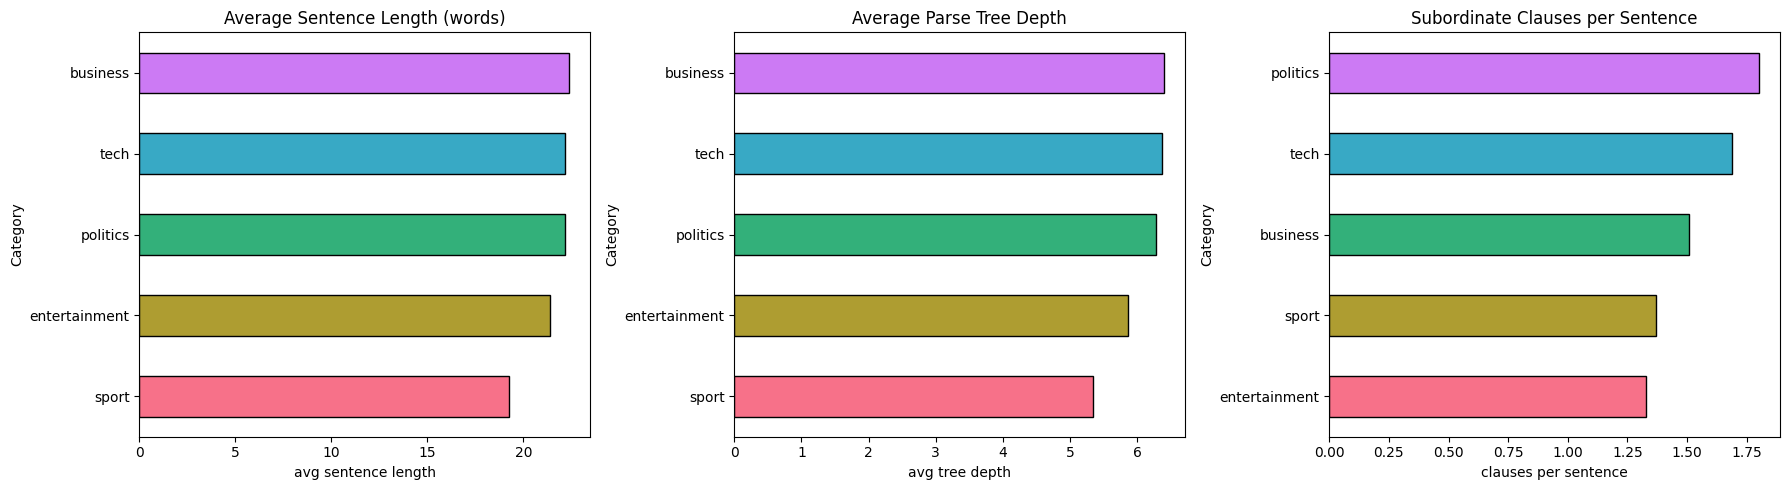


2️⃣ ACTION PATTERNS: WHO DID WHAT
------------------------------------------------------------

BUSINESS (266 triples)
  Top actors:  ['mr ebbers', 'nasdaq', 'company', 'shares', 'news']
  Top actions: ['have', 'make', 'hit', 'raise', 'take']
  Examples:    [('nasdaq', 'plan', 'm share sale'), ('nasdaq', 'plan', 'm share sale'), ('observers', 'see', 'this')]

ENTERTAINMENT (205 triples)
  Top actors:  ['band', 'film', 'brando', 'stars', 'people']
  Top actions: ['include', 'win', 'tell', 'take', 'enter']
  Examples:    [('berlin', 'celebrate', 'cinema organisers'), ('berlin film festival', 'celebrate', 'european cinema'), ('director dieter kosslick', 'say', 'showing signals')]

POLITICS (364 triples)
  Top actors:  ['people', 'government', 'labour', 'lib dems', 'mr howard']
  Top actions: ['tell', 'have', 'make', 'take', 'get']
  Examples:    [('election pr', 'appoint', 'figure'), ('lib dems', 'appoint', 'figure'), ('areas', 'have', 'access')]

SPORT (323 triples)
  Top actors:  ['nad

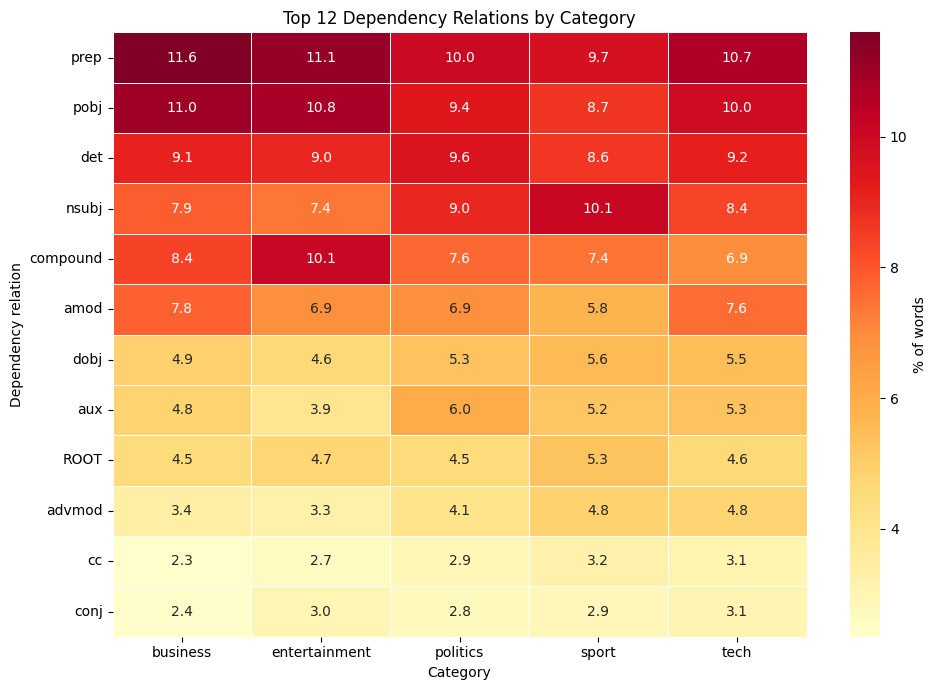


4️⃣ SYNTAX FEATURES FOR CLASSIFICATION
------------------------------------------------------------
Feature matrix: 200 articles x 20 syntactic features
Features: ['avg_sentence_length', 'avg_tree_depth', 'max_tree_depth', 'noun_phrases_per_sentence', 'clauses_per_sentence', 'passive_share', 'svo_per_sentence', 'dep_nsubj', 'dep_nsubjpass', 'dep_dobj', 'dep_pobj', 'dep_amod', 'dep_prep', 'dep_advmod', 'dep_compound', 'dep_nummod', 'dep_conj', 'dep_cc', 'dep_aux', 'dep_neg']

5-fold cross-validation accuracy (syntax features only): 49.50% (+/- 5.79%)
Random guessing would get about 20%

📝 SUMMARY
------------------------------------------------------------
• Parsed 200 articles (40 per category)
• Longest sentences: business, shortest: sport
• 20 syntactic features created for classification
• Syntax-only accuracy: 49.50% vs 20% chance


In [27]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

from sklearn.preprocessing import StandardScaler

print("\n" + "=" * 60)
print("🔍 EXTENDED SYNTACTIC ANALYSIS (STUDENT TASK)")
print("=" * 60)

# The sample above is a whole article, so its tree is very wide.
# Here is the same parse for just the first sentence, which is much easier to read.
first_sentence = next(doc.sents).text
print(f"\n📝 First sentence only: {first_sentence}")
try:
    displacy.render(nlp(first_sentence), style="dep", jupyter=True,
                    options={'compact': True, 'distance': 90})
except Exception as e:
    print(f"(Tree display skipped: {e})")

# PARSE A SAMPLE OF ARTICLES
# Parsing every article is slow, so we take an equal number from each category.
# Raise sample_per_category for more reliable averages (it also raises the runtime).
sample_per_category = 40
sample_size = min(sample_per_category, df['category'].value_counts().min())
syn_sample = df.groupby('category').sample(n=sample_size, random_state=42).reset_index(drop=True)

# nlp.pipe processes articles in batches, which is much faster than calling nlp() in a loop.
# The entity recognizer is switched off because we only need the parser here.
print(f"\n⚙️ Parsing {len(syn_sample)} articles ({sample_size} per category)...")
parsed_docs = list(nlp.pipe(syn_sample['full_text'].astype(str).tolist(),
                            batch_size=20, disable=['ner']))
print("✅ Parsing complete!")

# Dependency labels used as syntactic features (nsubj = subject, dobj = direct object,
# pobj = object of a preposition, amod = adjective modifier, nummod = number modifier, etc.)
key_deps_ext = ['nsubj', 'nsubjpass', 'dobj', 'pobj', 'amod', 'prep', 'advmod',
                'compound', 'nummod', 'conj', 'cc', 'aux', 'neg']
# Labels that signal subordinate or embedded clauses (a sign of more complex sentences)
clause_deps = ['advcl', 'ccomp', 'relcl', 'acl', 'xcomp']

def span_text(tok):
    """Return a token with its compound words, so 'Tim Cook' stays whole"""
    parts = sorted([c for c in tok.children if c.dep_ == 'compound'] + [tok], key=lambda t: t.i)
    return ' '.join(t.text.lower() for t in parts)

def syntax_feature_row(parsed):
    """Compute syntactic features, dependency counts, and who-did-what triples for one article"""
    sents = list(parsed.sents)
    words = [t for t in parsed if not t.is_space and not t.is_punct]
    n_words = max(len(words), 1)
    n_sents = max(len(sents), 1)
    dep_counts = Counter(t.dep_ for t in words)

    # Tree depth = how many steps a word is from the root of its sentence.
    # Deeper trees mean more nested, more complex sentences.
    depths = [max((len(list(t.ancestors)) for t in s), default=0) for s in sents]

    # Who did what to whom: subject + verb + direct object
    triples = []
    for tok in parsed:
        if tok.pos_ == 'VERB':
            subjects = [c for c in tok.children if c.dep_ in ('nsubj', 'nsubjpass')]
            objects = [c for c in tok.children if c.dep_ == 'dobj']
            for s in subjects:
                for o in objects:
                    triples.append((span_text(s), tok.lemma_.lower(), span_text(o)))

    subj_total = dep_counts.get('nsubj', 0) + dep_counts.get('nsubjpass', 0)
    row = {
        'avg_sentence_length': len(words) / n_sents,
        'avg_tree_depth': float(np.mean(depths)) if depths else 0.0,
        'max_tree_depth': max(depths) if depths else 0,
        'noun_phrases_per_sentence': len(list(parsed.noun_chunks)) / n_sents,
        'clauses_per_sentence': sum(dep_counts.get(d, 0) for d in clause_deps) / n_sents,
        'passive_share': dep_counts.get('nsubjpass', 0) / max(subj_total, 1) * 100,
        'svo_per_sentence': len(triples) / n_sents
    }
    # Each key dependency label as a % of all words in the article
    for d in key_deps_ext:
        row[f'dep_{d}'] = dep_counts.get(d, 0) / n_words * 100
    return row, dep_counts, triples

feature_rows = []
dep_counters = defaultdict(Counter)   # dependency counts per category
action_triples = defaultdict(list)    # who-did-what triples per category

for parsed, (_, article) in zip(parsed_docs, syn_sample.iterrows()):
    row_features, dep_counts, triples = syntax_feature_row(parsed)
    row_features['category'] = article['category']
    row_features['article_id'] = article['article_id']
    feature_rows.append(row_features)
    dep_counters[article['category']].update(dep_counts)
    action_triples[article['category']].extend(triples)

# This DataFrame is also the set of syntax features for classification (see section 4)
syntax_features_df = pd.DataFrame(feature_rows)

# 1) COMPARE SYNTACTIC COMPLEXITY ACROSS CATEGORIES
print("\n1️⃣ SYNTACTIC COMPLEXITY BY CATEGORY")
print("-" * 60)
complexity_cols = ['avg_sentence_length', 'avg_tree_depth', 'clauses_per_sentence',
                   'noun_phrases_per_sentence', 'passive_share']
complexity_summary = syntax_features_df.groupby('category')[complexity_cols].mean().round(2)
print(complexity_summary)

print(f"\n  ➜ Longest sentences:     {complexity_summary['avg_sentence_length'].idxmax()}")
print(f"  ➜ Shortest sentences:    {complexity_summary['avg_sentence_length'].idxmin()}")
print(f"  ➜ Deepest parse trees:   {complexity_summary['avg_tree_depth'].idxmax()}")
print(f"  ➜ Most clauses:          {complexity_summary['clauses_per_sentence'].idxmax()}")
print(f"  ➜ Most passive voice:    {complexity_summary['passive_share'].idxmax()}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, title) in zip(axes, [('avg_sentence_length', 'Average Sentence Length (words)'),
                                   ('avg_tree_depth', 'Average Parse Tree Depth'),
                                   ('clauses_per_sentence', 'Subordinate Clauses per Sentence')]):
    complexity_summary[col].sort_values().plot(kind='barh', ax=ax, edgecolor='black',
                                               color=sns.color_palette("husl", len(complexity_summary)))
    ax.set_title(title)
    ax.set_xlabel(col.replace('_', ' '))
    ax.set_ylabel('Category')
plt.tight_layout()
plt.show()

# 2) EXTRACT ACTION PATTERNS (WHO DID WHAT)
print("\n2️⃣ ACTION PATTERNS: WHO DID WHAT")
print("-" * 60)
# Pronouns are removed so real people and organizations show up instead of 'he' and 'it'
pronoun_set = {'he', 'she', 'it', 'they', 'we', 'i', 'you', 'who', 'which', 'that', 'this', 'there'}
for category in sorted(action_triples):
    triples = [t for t in action_triples[category] if t[0] not in pronoun_set]
    top_subjects = [w for w, _ in Counter(t[0] for t in triples).most_common(5)]
    top_actions = [w for w, _ in Counter(t[1] for t in triples).most_common(5)]
    print(f"\n{category.upper()} ({len(triples)} triples)")
    print(f"  Top actors:  {top_subjects}")
    print(f"  Top actions: {top_actions}")
    print(f"  Examples:    {triples[:3]}")

# 3) MOST COMMON DEPENDENCY RELATIONS PER CATEGORY
print("\n3️⃣ MOST COMMON DEPENDENCY RELATIONS PER CATEGORY")
print("-" * 60)
dep_table = pd.DataFrame(dep_counters).fillna(0)   # rows = relations, columns = categories
dep_pct = dep_table / dep_table.sum() * 100        # share of each category's words
for category in dep_pct.columns:
    top8 = dep_pct[category].sort_values(ascending=False).head(8)
    print(f"\n{category.upper()}: " + ", ".join(f"{dep} ({val:.1f}%)" for dep, val in top8.items()))

top_dep_labels = dep_pct.mean(axis=1).sort_values(ascending=False).head(12).index
plt.figure(figsize=(10, 7))
sns.heatmap(dep_pct.loc[top_dep_labels], annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': '% of words'})
plt.title('Top 12 Dependency Relations by Category')
plt.xlabel('Category')
plt.ylabel('Dependency relation')
plt.tight_layout()
plt.show()

# 4) CREATE FEATURES FOR CLASSIFICATION BASED ON SYNTAX
print("\n4️⃣ SYNTAX FEATURES FOR CLASSIFICATION")
print("-" * 60)
feature_cols = [c for c in syntax_features_df.columns if c not in ('category', 'article_id')]
X_syntax = syntax_features_df[feature_cols]
y_syntax = syntax_features_df['category']
print(f"Feature matrix: {X_syntax.shape[0]} articles x {X_syntax.shape[1]} syntactic features")
print(f"Features: {feature_cols}")

# Quick test: how well can syntax alone predict the category?
# Features are scaled first because they are on very different ranges.
syntax_clf = Pipeline([('scale', StandardScaler()),
                       ('clf', LogisticRegression(max_iter=1000))])
syntax_scores = cross_val_score(syntax_clf, X_syntax, y_syntax, cv=5)
chance = 1 / y_syntax.nunique()
print(f"\n5-fold cross-validation accuracy (syntax features only): "
      f"{syntax_scores.mean():.2%} (+/- {syntax_scores.std():.2%})")
print(f"Random guessing would get about {chance:.0%}")

# SUMMARY
print("\n📝 SUMMARY")
print("-" * 60)
print(f"• Parsed {len(syn_sample)} articles ({sample_size} per category)")
print(f"• Longest sentences: {complexity_summary['avg_sentence_length'].idxmax()}, "
      f"shortest: {complexity_summary['avg_sentence_length'].idxmin()}")
print(f"• {len(feature_cols)} syntactic features created for classification")
print(f"• Syntax-only accuracy: {syntax_scores.mean():.2%} vs {chance:.0%} chance")

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1490 articles

📝 Sample sentiment results:
   category  full_sentiment full_label
0  business         -0.9694   negative
1  business          0.8276   positive
2  business         -0.9318   negative
3      tech          0.9554   positive
4  business         -0.9486   negative

🔍 SENTIMENT ANALYSIS BY CATEGORY

1️⃣ OVERALL SENTIMENT DISTRIBUTION
------------------------------------------------------------
  positive    1045  (70.1%)
  negative     434  (29.1%)
  neutral       11  (0.7%)
  Average compound score: 0.390

2️⃣ SENTIMENT SCORE BY CATEGORY (compound, -1 to +1)
------------------------------------------------------------
                mean  median    std    min    max
category                                         
entertainment  0.598   0.970  0.681 -0.998  1.000
sport          0.551   0.966  0.730 -0.997  1.000
tech           0.517   0.955  0.761 -0.999  0.999
business       0.236   0.793  0.840 -0.998  1

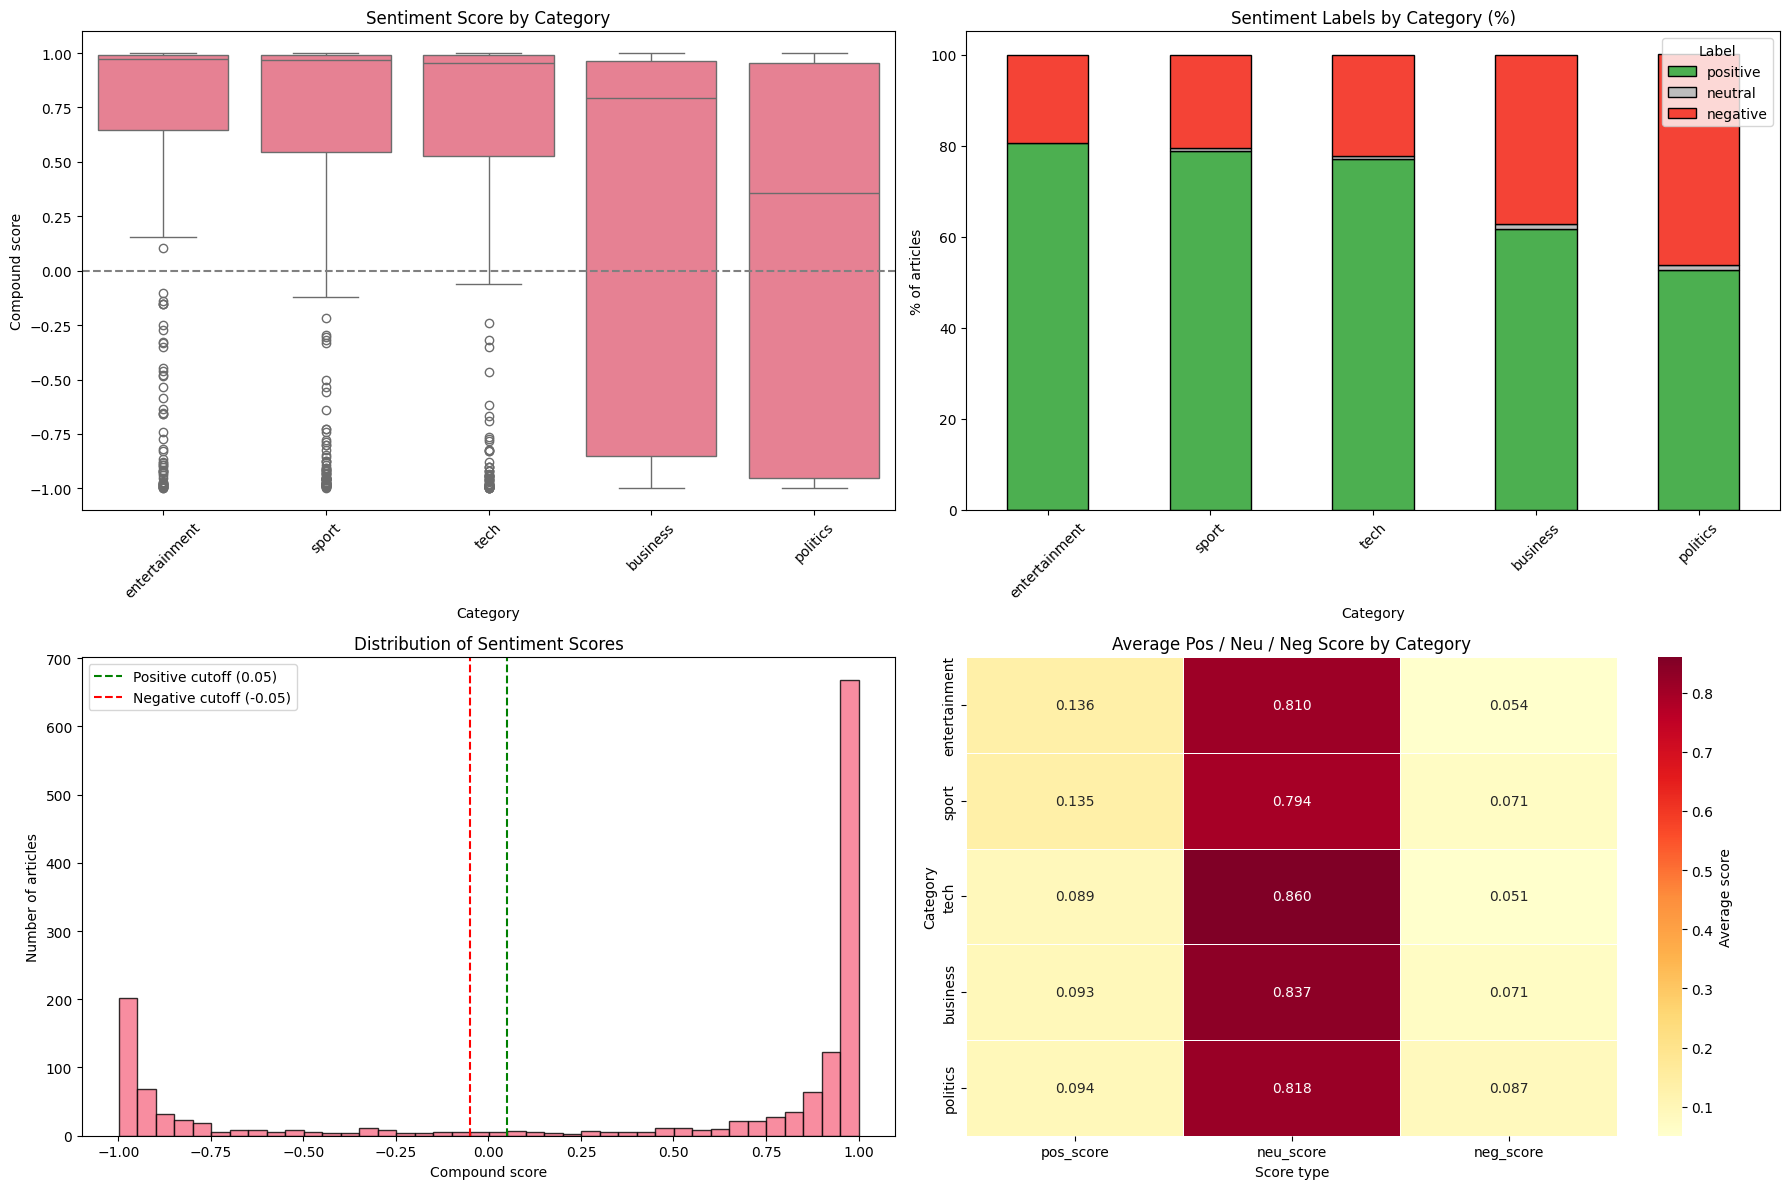


4️⃣ MOST POSITIVE AND MOST NEGATIVE ARTICLES
------------------------------------------------------------

🟢 Most positive:
  [entertainment] score 1.000: the producers scoops stage awards the producers has beaten mary poppins in the battle of the blockbuster west end musicals at the olivier awards.  the...
  [entertainment] score 1.000: aviator and vera take bafta glory hollywood blockbuster the aviator and low-budget british movie vera drake have shared the main honours at the 2005 b...
  [politics] score 1.000: kilroy launches  veritas  party ex-bbc chat show host and east midlands mep robert kilroy-silk said he wanted to  change the face of british politics ...

🔴 Most negative:
  [tech] score -0.999: call for action on internet scam phone companies are not doing enough to warn customers about internet  rogue-dialling  scams  according to premium ph...
  [tech] score -0.999: bond game fails to shake or stir for gaming fans  the word goldeneye evokes excited memories not only of th

In [28]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

from scipy import stats

print("\n" + "=" * 60)
print("🔍 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 60)

# Keep the overall score on df so it can be used as a classification feature later.
# Both frames use the same row order, so the values line up article by article.
df['sentiment_score'] = sentiment_df['full_sentiment'].values

# 1) OVERALL SENTIMENT DISTRIBUTION
print("\n1️⃣ OVERALL SENTIMENT DISTRIBUTION")
print("-" * 60)
for label, count in sentiment_df['full_label'].value_counts().items():
    print(f"  {label:<10} {count:>5}  ({count / len(sentiment_df) * 100:.1f}%)")
print(f"  Average compound score: {sentiment_df['full_sentiment'].mean():.3f}")

# 2) SENTIMENT BY CATEGORY
print("\n2️⃣ SENTIMENT SCORE BY CATEGORY (compound, -1 to +1)")
print("-" * 60)
sentiment_stats = (sentiment_df.groupby('category')['full_sentiment']
                   .agg(['mean', 'median', 'std', 'min', 'max'])
                   .round(3)
                   .sort_values('mean', ascending=False))
print(sentiment_stats)

# Share of positive / neutral / negative articles within each category
label_pct = (pd.crosstab(sentiment_df['category'], sentiment_df['full_label'], normalize='index') * 100)
label_pct = label_pct.reindex(columns=['positive', 'neutral', 'negative'], fill_value=0).round(1)
print("\n📊 % of articles by sentiment label:")
print(label_pct)

# Average positive / neutral / negative score (the share of words VADER counts in each bucket)
score_means = sentiment_df.groupby('category')[['pos_score', 'neu_score', 'neg_score']].mean().round(3)
print("\n🎭 Average pos / neu / neg score:")
print(score_means)

# Are the differences real or just noise? A one-way ANOVA compares the category averages.
groups = [g['full_sentiment'].values for _, g in sentiment_df.groupby('category')]
f_stat, p_value = stats.f_oneway(*groups)
print(f"\n📐 ANOVA across categories: F = {f_stat:.2f}, p = {p_value:.4g}")
if p_value < 0.05:
    print("  ➜ The category averages differ by more than chance would explain (p < 0.05).")
else:
    print("  ➜ The differences between categories could be due to chance (p >= 0.05).")

# 3) TITLE vs CONTENT SENTIMENT
# Note: in this dataset the 'title' is a placeholder (first five words of the article),
# so this comparison is weaker than it would be with real headlines.
print("\n3️⃣ TITLE vs CONTENT SENTIMENT")
print("-" * 60)
title_content_corr = sentiment_df['title_sentiment'].corr(sentiment_df['content_sentiment'])
print(f"Correlation between title and content sentiment: {title_content_corr:.3f}")
print(sentiment_df.groupby('category')[['title_sentiment', 'content_sentiment']].mean().round(3))

# VISUALIZATIONS
order = sentiment_stats.index.tolist()   # categories sorted from most to least positive
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Distribution of compound scores per category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', order=order, ax=axes[0, 0])
axes[0, 0].axhline(0, color='gray', linestyle='--')
axes[0, 0].set_title('Sentiment Score by Category')
axes[0, 0].set_xlabel('Category')
axes[0, 0].set_ylabel('Compound score')
axes[0, 0].tick_params(axis='x', rotation=45)

# Share of positive / neutral / negative articles per category
label_pct.loc[order].plot(kind='bar', stacked=True, ax=axes[0, 1], edgecolor='black',
                          color=['#4CAF50', '#BDBDBD', '#F44336'])
axes[0, 1].set_title('Sentiment Labels by Category (%)')
axes[0, 1].set_xlabel('Category')
axes[0, 1].set_ylabel('% of articles')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend(title='Label')

# Histogram of all compound scores, with the +/-0.05 label cutoffs
axes[1, 0].hist(sentiment_df['full_sentiment'], bins=40, edgecolor='black', alpha=0.8)
axes[1, 0].axvline(0.05, color='green', linestyle='--', label='Positive cutoff (0.05)')
axes[1, 0].axvline(-0.05, color='red', linestyle='--', label='Negative cutoff (-0.05)')
axes[1, 0].set_title('Distribution of Sentiment Scores')
axes[1, 0].set_xlabel('Compound score')
axes[1, 0].set_ylabel('Number of articles')
axes[1, 0].legend()

# Heatmap of the average pos / neu / neg scores
sns.heatmap(score_means.loc[order], annot=True, fmt='.3f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Average score'}, ax=axes[1, 1])
axes[1, 1].set_title('Average Pos / Neu / Neg Score by Category')
axes[1, 1].set_xlabel('Score type')
axes[1, 1].set_ylabel('Category')

plt.tight_layout()
plt.show()

# 4) MOST POSITIVE AND MOST NEGATIVE ARTICLES
# A quick sanity check: do the extremes actually read as positive or negative?
print("\n4️⃣ MOST POSITIVE AND MOST NEGATIVE ARTICLES")
print("-" * 60)
print("\n🟢 Most positive:")
for i in sentiment_df['full_sentiment'].nlargest(3).index:
    print(f"  [{sentiment_df.loc[i, 'category']}] score {sentiment_df.loc[i, 'full_sentiment']:.3f}: "
          f"{str(df['content'].iloc[i])[:150]}...")
print("\n🔴 Most negative:")
for i in sentiment_df['full_sentiment'].nsmallest(3).index:
    print(f"  [{sentiment_df.loc[i, 'category']}] score {sentiment_df.loc[i, 'full_sentiment']:.3f}: "
          f"{str(df['content'].iloc[i])[:150]}...")

# 5) HYPOTHESIS CHECK
# Hypothesis: sports might be more positive, politics more negative.
# Category labels are lowercase in this dataset, so match case-insensitively.
print("\n5️⃣ HYPOTHESIS CHECK")
print("-" * 60)
most_positive_cat = sentiment_stats['mean'].idxmax()
most_negative_cat = sentiment_stats['mean'].idxmin()
print(f"Most positive category on average: {most_positive_cat} ({sentiment_stats['mean'].max():.3f})")
print(f"Most negative category on average: {most_negative_cat} ({sentiment_stats['mean'].min():.3f})")

sport_cats = [c for c in sentiment_stats.index if 'sport' in str(c).lower()]
politics_cats = [c for c in sentiment_stats.index if 'politic' in str(c).lower()]
if sport_cats:
    print(f"\nSports are the most positive category: "
          f"{'✅ supported' if sport_cats[0] == most_positive_cat else '❌ not supported'} "
          f"(sport rank: {order.index(sport_cats[0]) + 1} of {len(order)})")
if politics_cats:
    print(f"Politics is the most negative category: "
          f"{'✅ supported' if politics_cats[0] == most_negative_cat else '❌ not supported'} "
          f"(politics rank: {order.index(politics_cats[0]) + 1} of {len(order)}, 1 = most positive)")

# SUMMARY
print("\n📝 SUMMARY")
print("-" * 60)
print(f"• {sentiment_df['full_label'].eq('positive').mean():.0%} of articles are positive, "
      f"{sentiment_df['full_label'].eq('negative').mean():.0%} negative, "
      f"{sentiment_df['full_label'].eq('neutral').mean():.0%} neutral")
print(f"• Most positive category: {most_positive_cat}, most negative: {most_negative_cat}")
print(f"• Category differences are {'statistically significant' if p_value < 0.05 else 'not statistically significant'} (p = {p_value:.4g})")

📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2357  0.8404 -0.9985  0.9995    0.0929    0.8366   
entertainment         0.5983  0.6815 -0.9978  0.9999    0.1357    0.8105   
politics              0.0498  0.8847 -0.9984  0.9999    0.0944    0.8181   
sport                 0.5507  0.7297 -0.9967  0.9996    0.1350    0.7938   
tech                  0.5166  0.7613 -0.9991  0.9993    0.0894    0.8597   

              neg_score  
                   mean  
category                 
business         0.0705  
entertainment    0.0539  
politics         0.0874  
sport            0.0712  
tech             0.0509  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

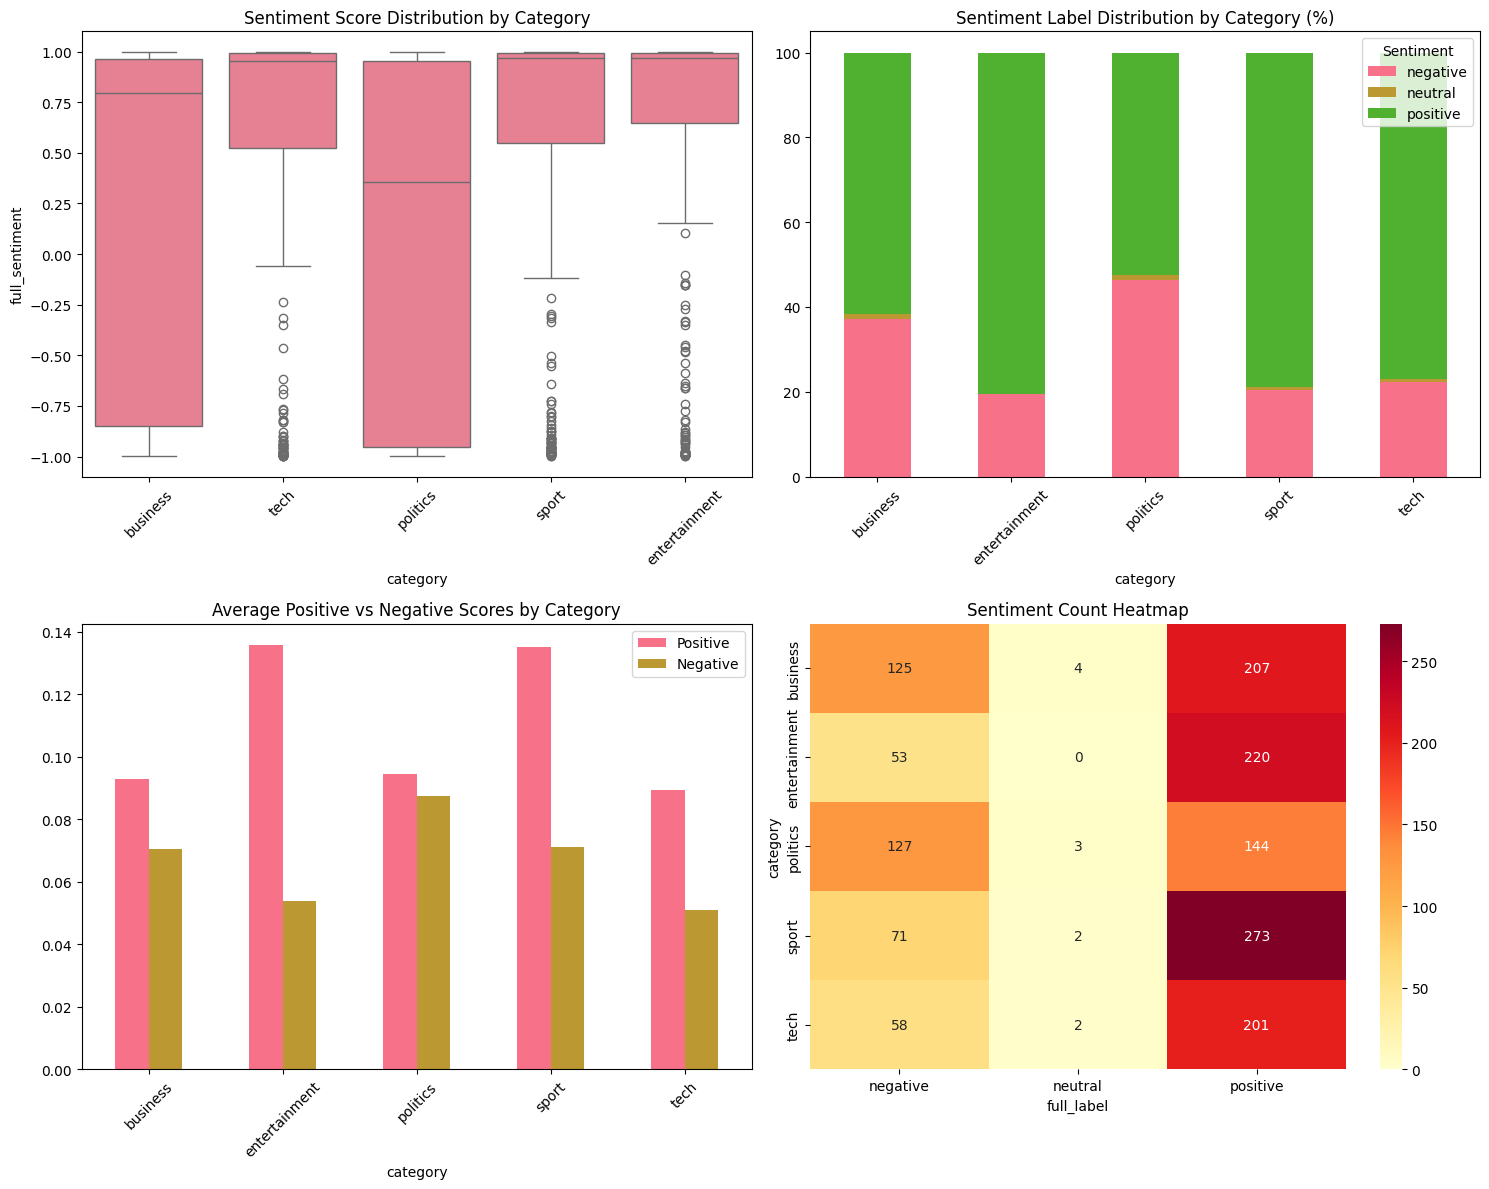


🔍 SENTIMENT PATTERN ANALYSIS (STUDENT TASK)

1️⃣ MOST POSITIVE AND MOST NEGATIVE CATEGORIES
--------------------------------------------------
                mean  median  % positive  % negative
category                                            
entertainment  0.598   0.970        80.6        19.4
sport          0.551   0.966        78.9        20.5
tech           0.517   0.955        77.0        22.2
business       0.236   0.793        61.6        37.2
politics       0.050   0.355        52.6        46.4

  ➜ Most positive: entertainment (mean 0.598)
  ➜ Most negative: politics (mean 0.050)
  ➜ ANOVA across categories: F = 26.35, p = 3.873e-21 (significant at 0.05)

2️⃣ TITLE vs CONTENT SENTIMENT
--------------------------------------------------
               title_sentiment  content_sentiment  \
category                                            
business                 0.019              0.240   
entertainment            0.073              0.599   
politics                -0

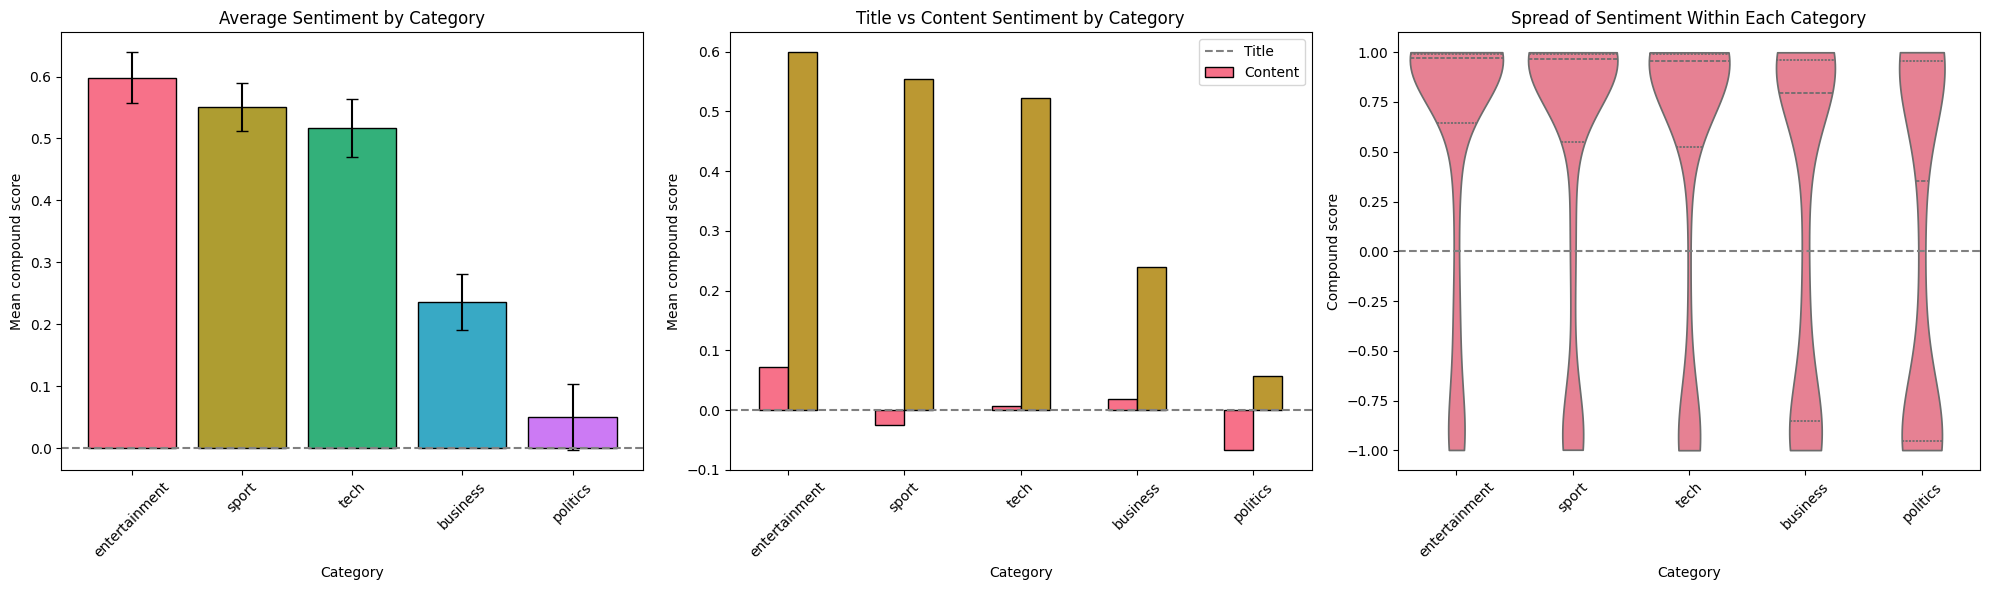


4️⃣ SENTIMENT AS A CLASSIFICATION FEATURE
--------------------------------------------------
Baselines: random guessing 20.0%, always predicting the biggest category 23.2%

Sentiment features only: 37.32% (+/- 0.93%)
TF-IDF only:             96.78% (+/- 0.99%)
TF-IDF + sentiment:      94.63% (+/- 1.90%)
  ➜ Change from adding sentiment: -2.15 percentage points

📝 SUMMARY
--------------------------------------------------
• Most positive category: entertainment, most negative: politics
• Title and content sentiment correlation: 0.30
• Category explains 6.6% of the variation in sentiment scores
• Sentiment alone predicts the category 37.3% of the time (chance is 20%)


In [29]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

from scipy import stats
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler

print("\n" + "=" * 50)
print("🔍 SENTIMENT PATTERN ANALYSIS (STUDENT TASK)")
print("=" * 50)

# Keep the overall score on df so it can be reused as a feature later.
# df and sentiment_df are in the same row order, so the values line up article by article.
df['sentiment_score'] = sentiment_df['full_sentiment'].values

# 1) WHICH CATEGORIES ARE MOST POSITIVE / NEGATIVE?
print("\n1️⃣ MOST POSITIVE AND MOST NEGATIVE CATEGORIES")
print("-" * 50)
cat_rank = (sentiment_df.groupby('category')['full_sentiment']
            .agg(['mean', 'median']).sort_values('mean', ascending=False).round(3))
cat_rank['% positive'] = ((sentiment_df['full_label'] == 'positive')
                          .groupby(sentiment_df['category']).mean() * 100).round(1)
cat_rank['% negative'] = ((sentiment_df['full_label'] == 'negative')
                          .groupby(sentiment_df['category']).mean() * 100).round(1)
print(cat_rank)
print(f"\n  ➜ Most positive: {cat_rank.index[0]} (mean {cat_rank['mean'].iloc[0]:.3f})")
print(f"  ➜ Most negative: {cat_rank.index[-1]} (mean {cat_rank['mean'].iloc[-1]:.3f})")

# Are the category averages really different, or is it noise? (one-way ANOVA)
groups = [g['full_sentiment'].values for _, g in sentiment_df.groupby('category')]
f_stat, p_value = stats.f_oneway(*groups)
print(f"  ➜ ANOVA across categories: F = {f_stat:.2f}, p = {p_value:.4g} "
      f"({'significant' if p_value < 0.05 else 'not significant'} at 0.05)")

# 2) TITLE vs CONTENT SENTIMENT
# Note: in this dataset the 'title' is a placeholder (first five words of the article),
# so this comparison is weaker than it would be with real headlines.
print("\n2️⃣ TITLE vs CONTENT SENTIMENT")
print("-" * 50)
title_content = sentiment_df.groupby('category')[['title_sentiment', 'content_sentiment']].mean().round(3)
title_content['difference (title - content)'] = (title_content['title_sentiment']
                                                 - title_content['content_sentiment']).round(3)
print(title_content)

corr = sentiment_df['title_sentiment'].corr(sentiment_df['content_sentiment'])
t_stat, t_p = stats.ttest_rel(sentiment_df['title_sentiment'], sentiment_df['content_sentiment'])
agreement = (sentiment_df['title_label'] == sentiment_df['content_label']).mean() * 100
print(f"\n  Correlation between title and content sentiment: {corr:.3f}")
print(f"  Title and content get the same label: {agreement:.1f}% of articles")
print(f"  Paired t-test (is the average title score different from content?): t = {t_stat:.2f}, p = {t_p:.4g}")
print(f"  Average title score {sentiment_df['title_sentiment'].mean():.3f} vs "
      f"content {sentiment_df['content_sentiment'].mean():.3f}")

# 3) HOW DOES SENTIMENT VARY WITHIN CATEGORIES?
print("\n3️⃣ VARIATION WITHIN CATEGORIES")
print("-" * 50)
spread = sentiment_df.groupby('category')['full_sentiment'].agg(
    std='std',
    iqr=lambda s: s.quantile(0.75) - s.quantile(0.25),
    min='min',
    max='max'
).round(3)
print(spread)

# Within each category, how many articles lean the same way as the category's majority label?
label_pct_within = pd.crosstab(sentiment_df['category'], sentiment_df['full_label'], normalize='index') * 100
print("\n  Share of articles that follow each category's most common label:")
for cat in label_pct_within.index:
    print(f"  {cat:<15} {label_pct_within.loc[cat].max():.1f}% {label_pct_within.loc[cat].idxmax()}")

# How much of the total variation comes from the category itself (eta squared)?
grand_mean = sentiment_df['full_sentiment'].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((sentiment_df['full_sentiment'] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total
print(f"\n  ➜ Category explains {eta_sq:.1%} of the variation in sentiment; "
      f"the other {1 - eta_sq:.1%} is variation within categories")

# Visualizations for sections 1-3
order = cat_rank.index.tolist()   # categories sorted from most to least positive
sem = sentiment_df.groupby('category')['full_sentiment'].sem().reindex(order)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Average sentiment per category, with error bars (standard error of the mean)
axes[0].bar(order, cat_rank['mean'], yerr=sem, capsize=4, edgecolor='black',
            color=sns.color_palette("husl", len(order)))
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title('Average Sentiment by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Mean compound score')
axes[0].tick_params(axis='x', rotation=45)

# Title vs content sentiment per category
title_content[['title_sentiment', 'content_sentiment']].loc[order].plot(
    kind='bar', ax=axes[1], edgecolor='black')
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('Title vs Content Sentiment by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Mean compound score')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['Title', 'Content'])

# Spread of scores inside each category
sns.violinplot(data=sentiment_df, x='category', y='full_sentiment', order=order,
               inner='quartile', cut=0, ax=axes[2])
axes[2].axhline(0, color='gray', linestyle='--')
axes[2].set_title('Spread of Sentiment Within Each Category')
axes[2].set_xlabel('Category')
axes[2].set_ylabel('Compound score')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 4) CAN SENTIMENT BE USED AS A FEATURE FOR CLASSIFICATION?
print("\n4️⃣ SENTIMENT AS A CLASSIFICATION FEATURE")
print("-" * 50)
sentiment_features = ['title_sentiment', 'content_sentiment', 'full_sentiment',
                      'pos_score', 'neu_score', 'neg_score']
X_sent = sentiment_df[sentiment_features].values
y_cls = sentiment_df['category'].values

chance = 1 / len(set(y_cls))
majority_baseline = pd.Series(y_cls).value_counts(normalize=True).max()
print(f"Baselines: random guessing {chance:.1%}, always predicting the biggest category {majority_baseline:.1%}")

# Sentiment features alone (scaled first because they are on different ranges)
sent_model = Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=1000))])
sent_scores = cross_val_score(sent_model, X_sent, y_cls, cv=5)
print(f"\nSentiment features only: {sent_scores.mean():.2%} (+/- {sent_scores.std():.2%})")

# Do they add anything on top of TF-IDF? Compare TF-IDF alone vs TF-IDF + sentiment.
if 'tfidf_matrix' in globals() and tfidf_matrix.shape[0] == len(sentiment_df):
    X_combined = hstack([tfidf_matrix, csr_matrix(StandardScaler().fit_transform(X_sent))]).tocsr()
    tfidf_only = cross_val_score(LogisticRegression(max_iter=1000), tfidf_matrix, y_cls, cv=5)
    combined = cross_val_score(LogisticRegression(max_iter=1000), X_combined, y_cls, cv=5)
    print(f"TF-IDF only:             {tfidf_only.mean():.2%} (+/- {tfidf_only.std():.2%})")
    print(f"TF-IDF + sentiment:      {combined.mean():.2%} (+/- {combined.std():.2%})")
    print(f"  ➜ Change from adding sentiment: {(combined.mean() - tfidf_only.mean()) * 100:+.2f} percentage points")
else:
    print("(TF-IDF matrix not found, so the TF-IDF comparison was skipped. Run the TF-IDF cell first.)")

# SUMMARY
print("\n📝 SUMMARY")
print("-" * 50)
print(f"• Most positive category: {cat_rank.index[0]}, most negative: {cat_rank.index[-1]}")
print(f"• Title and content sentiment correlation: {corr:.2f}")
print(f"• Category explains {eta_sq:.1%} of the variation in sentiment scores")
print(f"• Sentiment alone predicts the category {sent_scores.mean():.1%} of the time (chance is {chance:.0%})")

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

In [30]:
from sklearn.preprocessing import MinMaxScaler

# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# POS features (the tip above lists them as an option).
# pos_df was built from df in the same row order, so the rows line up.
# They are proportions, so they are already between 0 and 1.
if 'pos_df' in globals() and len(pos_df) == len(df):
    pos_cols = [t for t in ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
                            'JJ', 'JJR', 'JJS', 'RB', 'CD'] if t in pos_df.columns]
    pos_features = pos_df[pos_cols].values
else:
    pos_features = np.empty((len(df), 0))  # POS cell not run, so skip these features
    print("⚠️ pos_df not found, continuing without POS features")

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Attach the POS features to the combined matrix
X_combined = np.hstack([X_combined, pos_features])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

# Scale the non-TF-IDF columns (sentiment, length, POS) to the 0-1 range.
# Why: the length features are in the thousands while TF-IDF values are below 1, so without
# scaling they would dominate Logistic Regression and SVM. Sentiment scores can also be
# negative, and Naive Bayes in the next cell crashes on negative values.
# The scaler is fit on the training set only, so no test information leaks in.
n_tfidf = X_tfidf.shape[1]
extra_scaler = MinMaxScaler()
X_train[:, n_tfidf:] = extra_scaler.fit_transform(X_train[:, n_tfidf:])
# Test values can fall slightly outside the training range, so clip them back into 0-1
X_test[:, n_tfidf:] = np.clip(extra_scaler.transform(X_test[:, n_tfidf:]), 0, 1)

print(f"\n⚖️ Scaled {X_train.shape[1] - n_tfidf} non-TF-IDF features to the 0-1 range")
print(f"  Smallest value in X_train: {X_train.min():.4f} (must be >= 0 for Naive Bayes)")
print(f"  Smallest value in X_test:  {X_test.min():.4f}")

# Class balance in each split (stratify keeps them proportional)
print("\n🏷️ Class distribution (train vs test):")
print(pd.DataFrame({
    'train': pd.Series(y_train).value_counts(),
    'test': pd.Series(y_test).value_counts()
}))

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1490, 5022)
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1192 samples
  Test set: 298 samples

⚖️ Scaled 22 non-TF-IDF features to the 0-1 range
  Smallest value in X_train: 0.0000 (must be >= 0 for Naive Bayes)
  Smallest value in X_test:  0.0000

🏷️ Class distribution (train vs test):
               train  test
business         269    67
entertainment    218    55
politics         219    55
sport            277    69
tech             209    52


🤖 Training baseline classifiers to populate 'trained_models' and 'results'...
🥇 Baseline training complete! Best model: Naive Bayes (0.9597 accuracy)

📊 DETAILED EVALUATION: Naive Bayes

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.89      1.00      0.94        67
entertainment       1.00      0.96      0.98        55
     politics       1.00      0.89      0.94        55
        sport       0.96      1.00      0.98        69
         tech       0.98      0.92      0.95        52

     accuracy                           0.96       298
    macro avg       0.97      0.96      0.96       298
 weighted avg       0.96      0.96      0.96       298



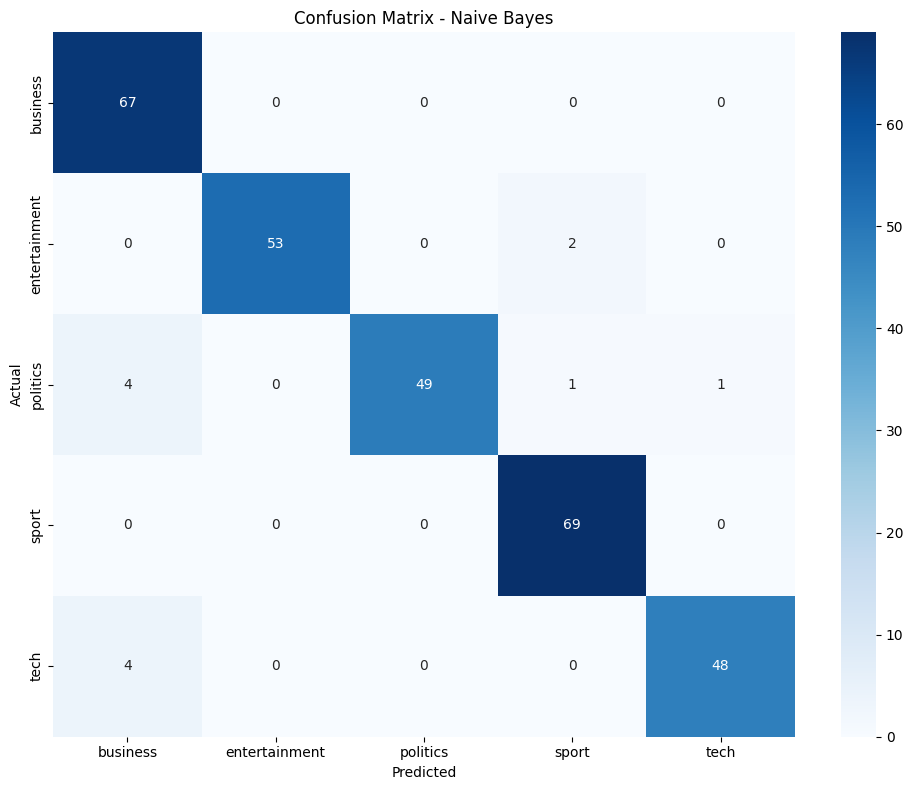


🚀 IMPROVING THE CLASSIFIER (STUDENT TASK)

1️⃣ DIFFERENT FEATURE COMBINATIONS (Logistic Regression)
------------------------------------------------------------
  TF-IDF only                                   accuracy 0.9664 | macro F1 0.9650
  TF-IDF + sentiment                            accuracy 0.9664 | macro F1 0.9656
  TF-IDF + length                               accuracy 0.9597 | macro F1 0.9586
  TF-IDF + POS                                  accuracy 0.9530 | macro F1 0.9530
  All features                                  accuracy 0.9564 | macro F1 0.9545
  No TF-IDF (sentiment + length + POS only)     accuracy 0.6409 | macro F1 0.6345

🔍 Top 8 features per category (all-features model):
  business        firm, company, bank, economy, POS_CD, market, share, economic
  entertainment   film, show, music, star, album, POS_NN, singer, band
  politics        labour, blair, election, party, POS_VB, minister, government, tory
  sport           POS_VBP, match, coach, champion, cup, p

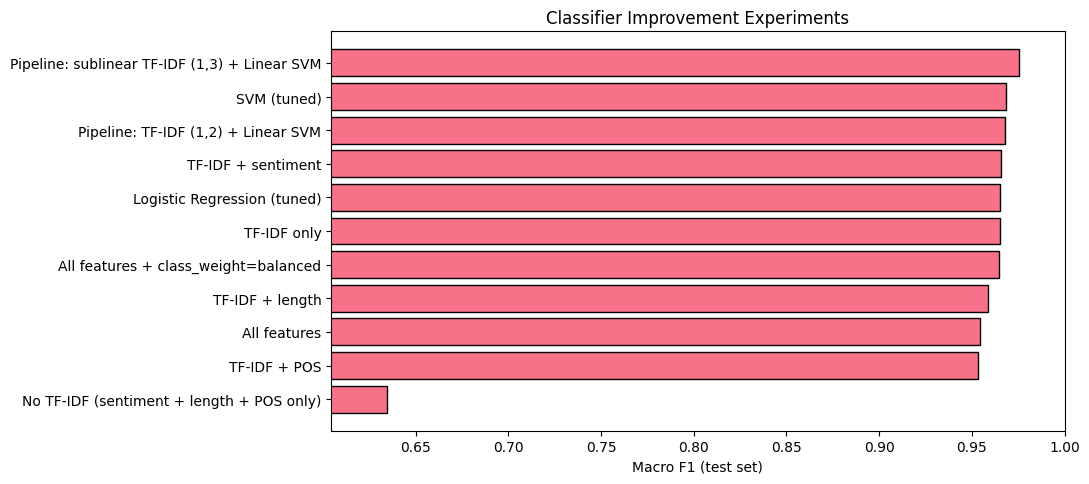


ᝅ Best experiment: Pipeline: sublinear TF-IDF (1,3) + Linear SVM (accuracy 0.9765, macro F1 0.9756)
ᜅ Original best model: Naive Bayes (accuracy 0.9597)


In [32]:
# 🚀 Train the baseline classifiers if they are not already in memory to avoid NameErrors
if 'trained_models' not in globals() or 'best_model_name' not in globals() or 'results' not in globals():
    print("🤖 Training baseline classifiers to populate 'trained_models' and 'results'...")
    classifiers_init = {
        'Naive Bayes': MultinomialNB(),
        'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
        'SVM': SVC(random_state=42, probability=True)
    }
    results = {}
    trained_models = {}

    for name, clf in classifiers_init.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        cv_scores = cross_val_score(clf, X_train, y_train, cv=3, scoring='accuracy')

        results[name] = {
            'accuracy': accuracy,
            'cv_mean': cv_scores.mean(),
            'cv_std': cv_scores.std(),
            'predictions': y_pred
        }
        trained_models[name] = clf

    best_model_name = max(results, key=lambda name: results[name]['accuracy'])
    print(f"🥇 Baseline training complete! Best model: {best_model_name} ({results[best_model_name]['accuracy']:.4f} accuracy)\n")

# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, recall_score

print("\n" + "=" * 60)
print("🚀 IMPROVING THE CLASSIFIER (STUDENT TASK)")
print("=" * 60)

# Column layout of X_train / X_test from the feature preparation cell:
# [TF-IDF terms | 4 sentiment | 3 length | POS proportions]
n_tfidf_cols = X_tfidf.shape[1]
blocks = {
    'tfidf': np.arange(0, n_tfidf_cols),
    'sentiment': np.arange(n_tfidf_cols, n_tfidf_cols + 4),
    'length': np.arange(n_tfidf_cols + 4, n_tfidf_cols + 7),
    'pos': np.arange(n_tfidf_cols + 7, X_train.shape[1])   # empty if the POS cell was not run
}

def cols(*names):
    """Column indices for one or more feature groups"""
    return np.concatenate([blocks[n] for n in names])

labels = np.unique(y)
experiments = []   # every experiment is stored here for the final comparison

def record(name, group, pred):
    """Store accuracy and macro F1 (macro F1 treats every category equally)"""
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average='macro')
    experiments.append({'Experiment': name, 'Group': group, 'Accuracy': acc, 'Macro F1': f1})
    print(f"  {name:<45} accuracy {acc:.4f} | macro F1 {f1:.4f}")

# 1) DIFFERENT FEATURE COMBINATIONS
# Same model every time (Logistic Regression), so only the features change.
print("\n1️⃣ DIFFERENT FEATURE COMBINATIONS (Logistic Regression)")
print("-" * 60)
combos = {
    'TF-IDF only': ['tfidf'],
    'TF-IDF + sentiment': ['tfidf', 'sentiment'],
    'TF-IDF + length': ['tfidf', 'length'],
    'TF-IDF + POS': ['tfidf', 'pos'],
    'All features': ['tfidf', 'sentiment', 'length', 'pos'],
    'No TF-IDF (sentiment + length + POS only)': ['sentiment', 'length', 'pos']
}
fitted_combo_models = {}
combo_preds = {}
for name, groups in combos.items():
    if any(len(blocks[g]) == 0 for g in groups):
        print(f"  (skipped '{name}': those features are not in the matrix)")
        continue
    idx = cols(*groups)
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train[:, idx], y_train)
    combo_preds[name] = model.predict(X_test[:, idx])
    fitted_combo_models[name] = model
    record(name, 'Feature combinations', combo_preds[name])

# Top terms per category from the all-features model, with names for every column
# (this includes the POS columns, which the original names list above does not cover)
if 'All features' in fitted_combo_models:
    pos_names = pos_cols if 'pos_cols' in globals() and len(pos_cols) == len(blocks['pos']) \
        else [f'pos_{i}' for i in range(len(blocks['pos']))]
    all_names = (list(feature_names)
                 + ['sentiment', 'pos_score', 'neu_score', 'neg_score']
                 + ['char_length', 'word_count', 'title_length']
                 + [f'POS_{t}' for t in pos_names])
    lr_all = fitted_combo_models['All features']
    print("\n🔍 Top 8 features per category (all-features model):")
    for i, class_name in enumerate(lr_all.classes_):
        top = np.argsort(lr_all.coef_[i])[-8:][::-1]
        print(f"  {class_name:<15} " + ", ".join(all_names[j] for j in top))

# 2) HYPERPARAMETER TUNING
# Grid search picks settings using 3-fold cross-validation on the TRAINING set only,
# so the test set stays untouched until the final score.
print("\n2️⃣ HYPERPARAMETER TUNING (grid search, 3-fold CV on the training set)")
print("-" * 60)
searches = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42),
                            {'C': [0.1, 1, 10, 100]}),
    'SVM': (SVC(random_state=42),
            {'C': [1, 10], 'kernel': ['linear', 'rbf']})
}
tuned_models = {}
for name, (estimator, grid) in searches.items():
    search = GridSearchCV(estimator, grid, cv=3, scoring='f1_macro', n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    print(f"  {name}: best parameters {search.best_params_} (CV macro F1 {search.best_score_:.4f})")
    record(f"{name} (tuned)", 'Hyperparameter tuning', search.predict(X_test))

# 3) MORE SOPHISTICATED FEATURES
# So far the TF-IDF vectorizer was fit on ALL articles, so the test set leaked into the vocabulary
# and IDF weights. Here the vectorizer sits inside a Pipeline, so it only learns from training data.
# The second version also adds trigrams and sublinear TF (log scaling, so a word repeated 20 times
# does not count 20x as much).
print("\n3️⃣ LEAK-FREE PIPELINES AND RICHER TEXT FEATURES")
print("-" * 60)

# Recreate the same split as an index split, so text can go into the pipelines directly.
# Same random_state and stratify as before, so the rows are identical to X_train / X_test.
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42, stratify=y)
assert np.array_equal(y[idx_train], y_train) and np.array_equal(y[idx_test], y_test), "Split does not match"
text_train = df['full_text_processed'].values[idx_train]
text_test = df['full_text_processed'].values[idx_test]

text_pipelines = {
    'Pipeline: TF-IDF (1,2) + Linear SVM': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8)),
        ('clf', LinearSVC(random_state=42))]),
    'Pipeline: sublinear TF-IDF (1,3) + Linear SVM': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=20000, ngram_range=(1, 3), min_df=2, max_df=0.8,
                                  sublinear_tf=True)),
        ('clf', LinearSVC(random_state=42))])
}
for name, pipe in text_pipelines.items():
    pipe.fit(text_train, y_train)
    record(name, 'Richer text features', pipe.predict(text_test))

# 4) CLASS IMBALANCE
print("\n4️⃣ CLASS IMBALANCE")
print("-" * 60)
train_counts = pd.Series(y_train).value_counts()
print(train_counts.to_string())
print(f"Imbalance ratio (largest / smallest category): {train_counts.max() / train_counts.min():.2f}")

# class_weight='balanced' gives smaller categories a larger weight in the loss
if 'All features' in combo_preds:
    balanced_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    balanced_model.fit(X_train, y_train)
    balanced_pred = balanced_model.predict(X_test)
    record('All features + class_weight=balanced', 'Class imbalance', balanced_pred)

    # Recall per category: of the real articles in each category, how many were found?
    recall_table = pd.DataFrame({
        'default': recall_score(y_test, combo_preds['All features'], average=None, labels=labels),
        'balanced': recall_score(y_test, balanced_pred, average=None, labels=labels)
    }, index=labels).round(3)
    print("\nRecall per category (default vs balanced):")
    print(recall_table)

# 5) ERROR ANALYSIS
# Which categories get mixed up, and what do the mistakes look like?
print("\n5️⃣ ERROR ANALYSIS (original best model)")
print("-" * 60)
confused_pairs = []
for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((labels[i], labels[j], cm[i, j]))
confused_pairs.sort(key=lambda t: t[2], reverse=True)
print("Most confused pairs (actual -> predicted):")
for actual, predicted, count in confused_pairs[:5]:
    print(f"  {actual} -> {predicted}: {count}")

wrong = np.where(best_predictions != y_test)[0]
print(f"\n{len(wrong)} of {len(y_test)} test articles were misclassified by {best_model_name}. Examples:")
for k in wrong[:3]:
    print(f"\n  Actual: {y_test[k]} | Predicted: {best_predictions[k]}")
    print(f"  {str(df['content'].iloc[idx_test[k]])[:200]}...")

# SUMMARY OF ALL EXPERIMENTS
print("\nᜁ ALL EXPERIMENTS (sorted by macro F1)")
print("-" * 60)
summary = pd.DataFrame(experiments).sort_values('Macro F1', ascending=False).reset_index(drop=True)
print(summary.round(4).to_string())

plt.figure(figsize=(11, max(4, 0.45 * len(summary))))
plt.barh(summary['Experiment'][::-1], summary['Macro F1'][::-1], edgecolor='black')
plt.xlim(max(0, summary['Macro F1'].min() - 0.03), 1.0)
plt.xlabel('Macro F1 (test set)')
plt.title('Classifier Improvement Experiments')
plt.tight_layout()
plt.show()

print(f"\nᝅ Best experiment: {summary.loc[0, 'Experiment']} "
      f"(accuracy {summary.loc[0, 'Accuracy']:.4f}, macro F1 {summary.loc[0, 'Macro F1']:.4f})")
print(f"ᜅ Original best model: {best_model_name} "
      f"(accuracy {results[best_model_name]['accuracy']:.4f})")

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 42941
📰 Articles processed: 1490

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business

📊 ENTITY ANALYSIS

1️⃣ ENTITY TYPES
------------------------------------------------------------
             mentions  unique_entities                                           description
label                                                                   

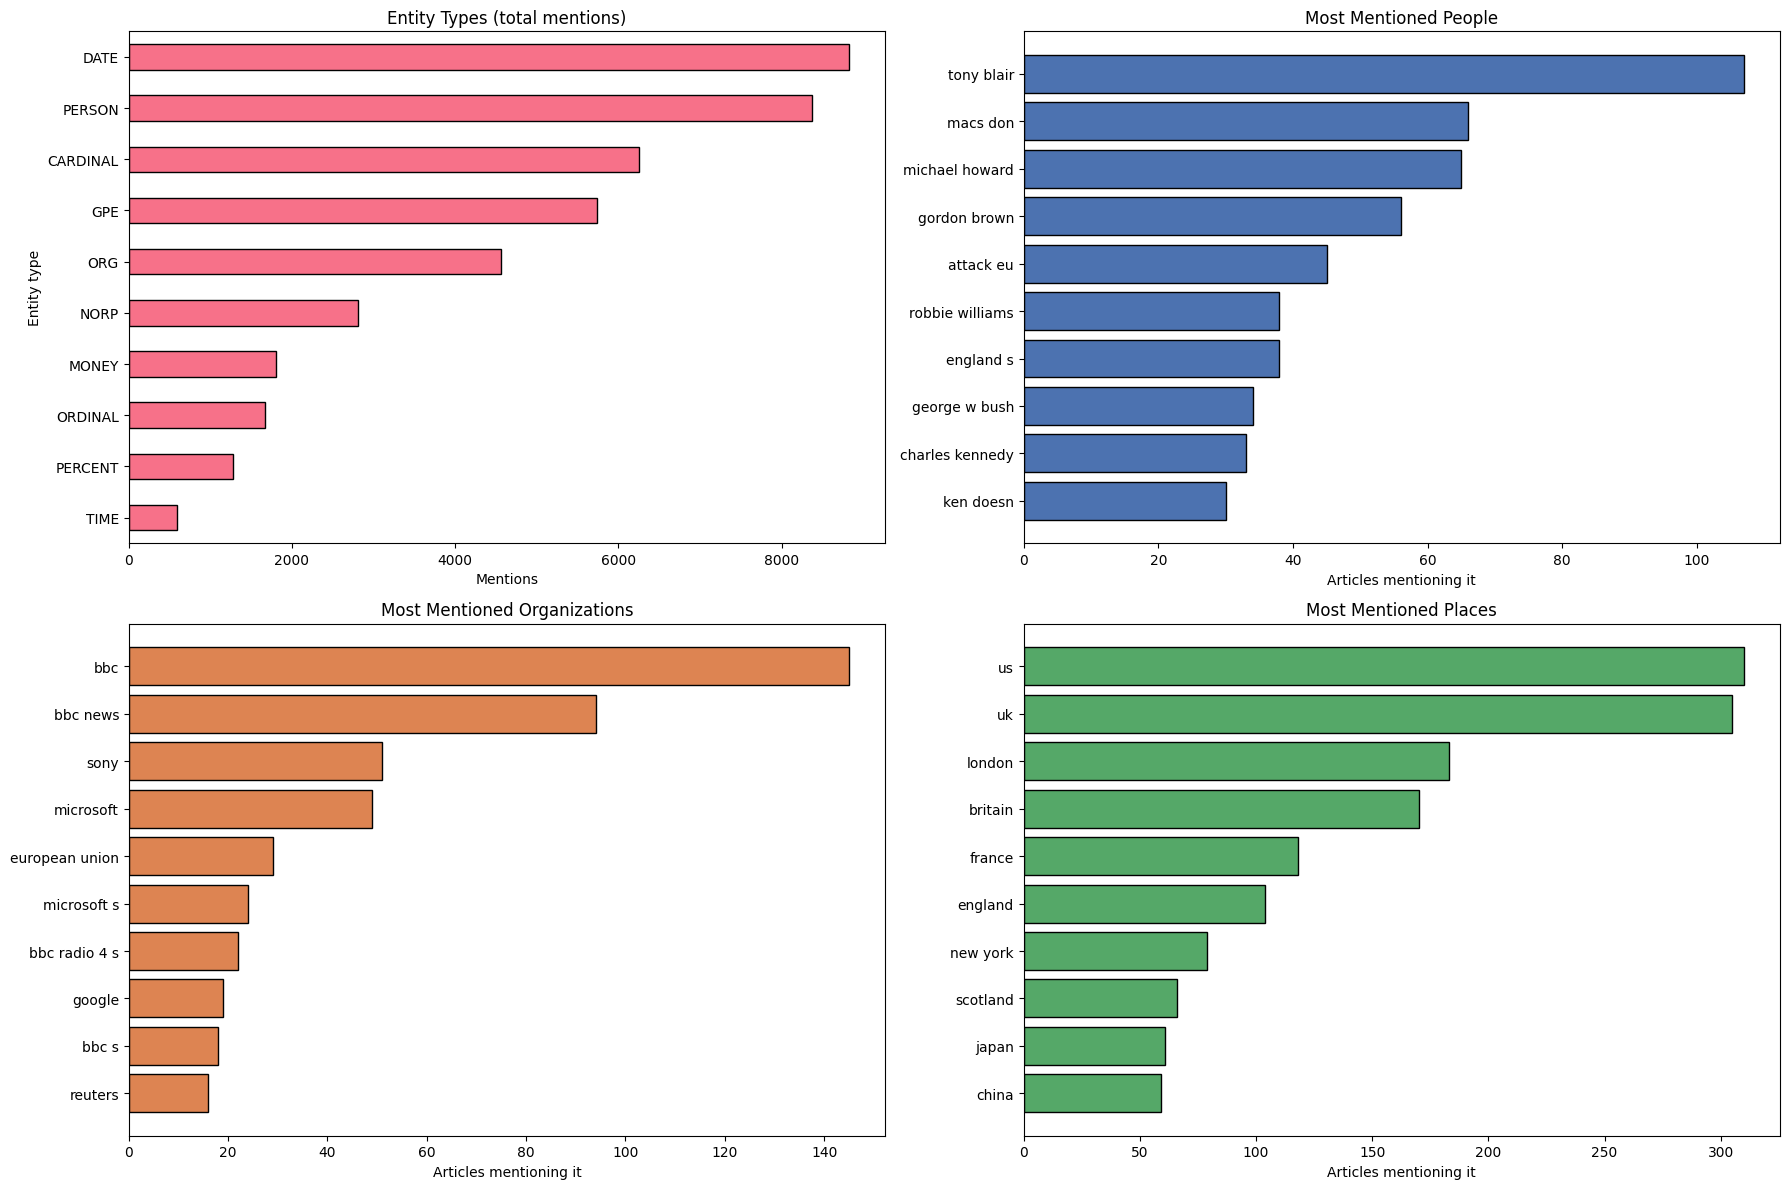

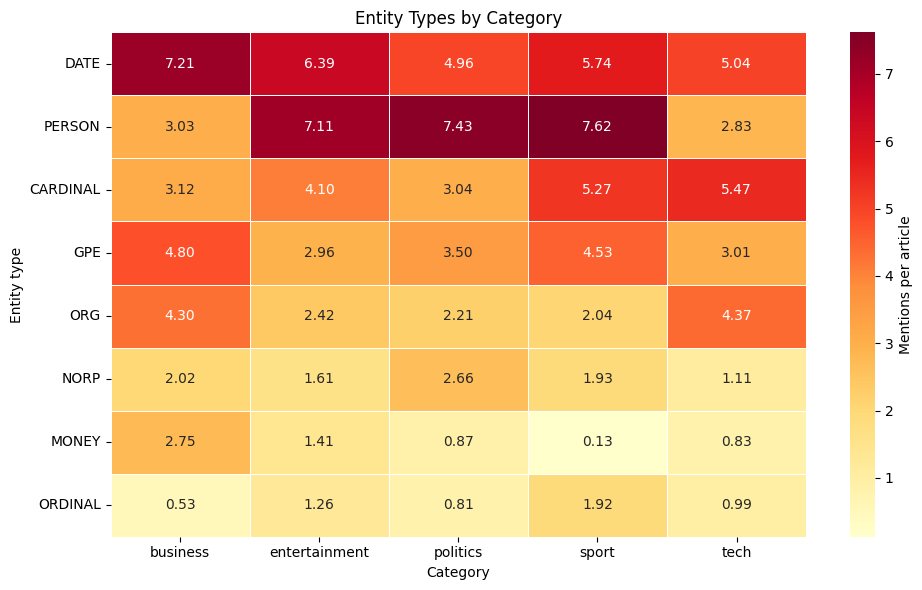


📝 SUMMARY
------------------------------------------------------------
• 42,941 entity mentions, 11,604 unique entities, 18 entity types
• Average of 28.8 entities per article
• Most common entity type: DATE
• Category with the most entities per article: business


In [33]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

from itertools import combinations

if not entities_df.empty:
    print("\n" + "=" * 60)
    print("📊 ENTITY ANALYSIS")
    print("=" * 60)

    # CLEAN THE ENTITY STRINGS
    # "Tony Blair", "tony blair" and "Mr Blair" should count as one entity, not three.
    def normalize_entity(text):
        t = re.sub(r'\s+', ' ', str(text).strip().lower())
        t = re.sub(r"'s$", '', t)                              # possessive: "blair's" -> "blair"
        t = re.sub(r'^(the|mr|mrs|ms|dr|sir)\.?\s+', '', t)    # leading titles and "the"
        return t.strip()

    entities_df['entity_norm'] = entities_df['text'].apply(normalize_entity)
    entities_df = entities_df[entities_df['entity_norm'] != ''].copy()

    # Merge one-word person names into the most common full name with the same last word
    # ("blair" -> "tony blair"). Two different people with the same surname would get merged,
    # which is a known limit of this shortcut.
    person_mask = entities_df['label'] == 'PERSON'
    multi_word = person_mask & entities_df['entity_norm'].str.contains(' ')
    surname_map = {}
    for name, _ in Counter(entities_df.loc[multi_word, 'entity_norm']).most_common():
        surname_map.setdefault(name.split()[-1], name)   # most common full name wins
    single_word = person_mask & ~entities_df['entity_norm'].str.contains(' ')
    entities_df.loc[single_word, 'entity_norm'] = entities_df.loc[single_word, 'entity_norm'].map(
        lambda n: surname_map.get(n, n))

    # One row per (article, entity), so an entity mentioned 5 times in one article counts once.
    # Used for "how many articles mention X" counts.
    unique_mentions = entities_df.drop_duplicates(['article_id', 'entity_norm', 'label'])

    def top_entities(label, n=10, data=None):
        """Most common entities of one type, ranked by number of articles that mention them"""
        data = unique_mentions if data is None else data
        return data[data['label'] == label]['entity_norm'].value_counts().head(n)

    # 1) ENTITY TYPES
    print("\n1️⃣ ENTITY TYPES")
    print("-" * 60)
    label_info = (entities_df.groupby('label')
                  .agg(mentions=('text', 'size'), unique_entities=('entity_norm', 'nunique'),
                       description=('description', 'first'))
                  .sort_values('mentions', ascending=False))
    print(label_info.to_string())

    # How many entities does the average article contain, and does it differ by category?
    entity_stats = pd.DataFrame(article_entities)[['article_id', 'category', 'entity_count']]
    entity_stats['words'] = df['full_text'].str.split().str.len().values   # same row order as df
    entity_stats['entities_per_100_words'] = entity_stats['entity_count'] / entity_stats['words'] * 100
    print("\nEntities per article, by category:")
    print(entity_stats.groupby('category')[['entity_count', 'entities_per_100_words']].mean().round(2))

    # 2) ENTITY TRACKING: MOST MENTIONED PEOPLE, ORGANIZATIONS, PLACES
    print("\n2️⃣ MOST MENTIONED ENTITIES (number of articles that mention them)")
    print("-" * 60)
    for label, title in [('PERSON', '👤 People'), ('ORG', '🏢 Organizations'), ('GPE', '🌍 Places')]:
        print(f"\n{title}:")
        for name, count in top_entities(label, 10).items():
            print(f"  {name:<25} {count}")

    # Top entities within each category (shows what each section of the news is about)
    print("\n🏷️ TOP PEOPLE AND ORGANIZATIONS BY CATEGORY")
    for category in sorted(entities_df['category'].unique()):
        cat_data = unique_mentions[unique_mentions['category'] == category]
        people = [n for n in top_entities('PERSON', 5, cat_data).index]
        orgs = [n for n in top_entities('ORG', 5, cat_data).index]
        print(f"\n{category.upper()}")
        print(f"  People: {people}")
        print(f"  Orgs:   {orgs}")

    # 3) ENTITY TYPES BY CATEGORY
    print("\n3️⃣ ENTITY TYPES BY CATEGORY (average mentions per article)")
    print("-" * 60)
    articles_per_category = df['category'].value_counts()
    label_by_category = pd.crosstab(entities_df['label'], entities_df['category'])
    label_by_category = label_by_category.div(articles_per_category.reindex(label_by_category.columns), axis=1)
    top_labels = label_info.head(8).index
    print(label_by_category.loc[top_labels].round(2))

    # 4) FACT EXTRACTION: MONEY AND PERCENTAGES
    # These turn free text into structured values (e.g. business articles with figures).
    print("\n4️⃣ FACT EXTRACTION: MONEY AND PERCENTAGES")
    print("-" * 60)
    for label in ['MONEY', 'PERCENT']:
        facts = entities_df[entities_df['label'] == label]
        if facts.empty:
            continue
        print(f"\n{label}: {len(facts)} mentions, most common in "
              f"{facts['category'].value_counts().idxmax()}")
        print(facts.groupby('category').size().sort_values(ascending=False).to_string())
        print("  Examples:", facts['text'].head(5).tolist())

    # 5) RELATIONSHIP MAPPING: WHO APPEARS TOGETHER
    # Two entities that show up in the same article are "connected".
    # Counting these pairs shows which people and organizations are covered together.
    print("\n5️⃣ ENTITIES MENTIONED TOGETHER (same article)")
    print("-" * 60)
    pair_counts = Counter()
    people_orgs = unique_mentions[unique_mentions['label'].isin(['PERSON', 'ORG'])]
    for _, group in people_orgs.groupby('article_id'):
        names = sorted(set(group['entity_norm']))
        pair_counts.update(combinations(names, 2))
    for (a, b), count in pair_counts.most_common(10):
        print(f"  {a} + {b}: {count} articles")

    # 6) ENTITY SEARCH: "SHOW ME ALL ARTICLES MENTIONING X"
    # The business example from the module intro, as a reusable function.
    def find_articles(entity_name, label=None):
        key = normalize_entity(entity_name)
        mask = entities_df['entity_norm'] == key
        if label:
            mask &= entities_df['label'] == label
        ids = entities_df.loc[mask, 'article_id'].unique()
        found = df[df['article_id'].isin(ids)][['article_id', 'category', 'content']].copy()
        found['content'] = found['content'].astype(str).str[:100] + '...'
        return found

    print("\n6️⃣ ENTITY SEARCH DEMO")
    print("-" * 60)
    demo_entity = top_entities('ORG', 1).index[0] if not top_entities('ORG', 1).empty else None
    if demo_entity:
        demo = find_articles(demo_entity, 'ORG')
        print(f"Articles mentioning '{demo_entity}': {len(demo)}")
        print(f"Categories: {demo['category'].value_counts().to_dict()}")
        print(demo.head(3).to_string(index=False))
    print("\nTry your own: find_articles('your entity here')")

    # 7) TIMELINE NOTE
    # The 'date' column is a placeholder (the same value for every row), so mentions cannot be
    # tracked over time. The DATE entities below are dates mentioned INSIDE the stories.
    print("\n7️⃣ DATES MENTIONED INSIDE ARTICLES")
    print("-" * 60)
    print(top_entities('DATE', 10).to_string())

    # VISUALIZATIONS
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    label_info['mentions'].head(10)[::-1].plot(kind='barh', ax=axes[0, 0], edgecolor='black')
    axes[0, 0].set_title('Entity Types (total mentions)')
    axes[0, 0].set_xlabel('Mentions')
    axes[0, 0].set_ylabel('Entity type')

    for ax, label, title, color in [(axes[0, 1], 'PERSON', 'Most Mentioned People', '#4C72B0'),
                                    (axes[1, 0], 'ORG', 'Most Mentioned Organizations', '#DD8452'),
                                    (axes[1, 1], 'GPE', 'Most Mentioned Places', '#55A868')]:
        top = top_entities(label, 10)
        ax.barh(list(top.index)[::-1], list(top.values)[::-1], color=color, edgecolor='black')
        ax.set_title(title)
        ax.set_xlabel('Articles mentioning it')

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 6))
    sns.heatmap(label_by_category.loc[top_labels], annot=True, fmt='.2f', cmap='YlOrRd',
                linewidths=0.5, cbar_kws={'label': 'Mentions per article'})
    plt.title('Entity Types by Category')
    plt.xlabel('Category')
    plt.ylabel('Entity type')
    plt.tight_layout()
    plt.show()

    # SUMMARY
    print("\n📝 SUMMARY")
    print("-" * 60)
    print(f"• {len(entities_df):,} entity mentions, {entities_df['entity_norm'].nunique():,} unique entities, "
          f"{entities_df['label'].nunique()} entity types")
    print(f"• Average of {entity_stats['entity_count'].mean():.1f} entities per article")
    print(f"• Most common entity type: {label_info.index[0]}")
    print(f"• Category with the most entities per article: "
          f"{entity_stats.groupby('category')['entity_count'].mean().idxmax()}")

📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8827
PERSON         8369
CARDINAL       6251
GPE            5734
ORG            4559
NORP           2805
MONEY          1808
ORDINAL        1669
PERCENT        1279
TIME            594
LOC             518
QUANTITY        199
PRODUCT          92
FAC              91
LANGUAGE         62
EVENT            43
LAW              33
WORK_OF_ART       8
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
business           1048  2421      3   11  1614         1   15  173    924   
entertainment      1120  1744     12   15   809         9    4   64    386   
politics            833  1360     22   23   959        10    4  124    238   
sport              1823  1987      5   40  1567        12    5   35     44   
tech               1427  1315      1    2   785     

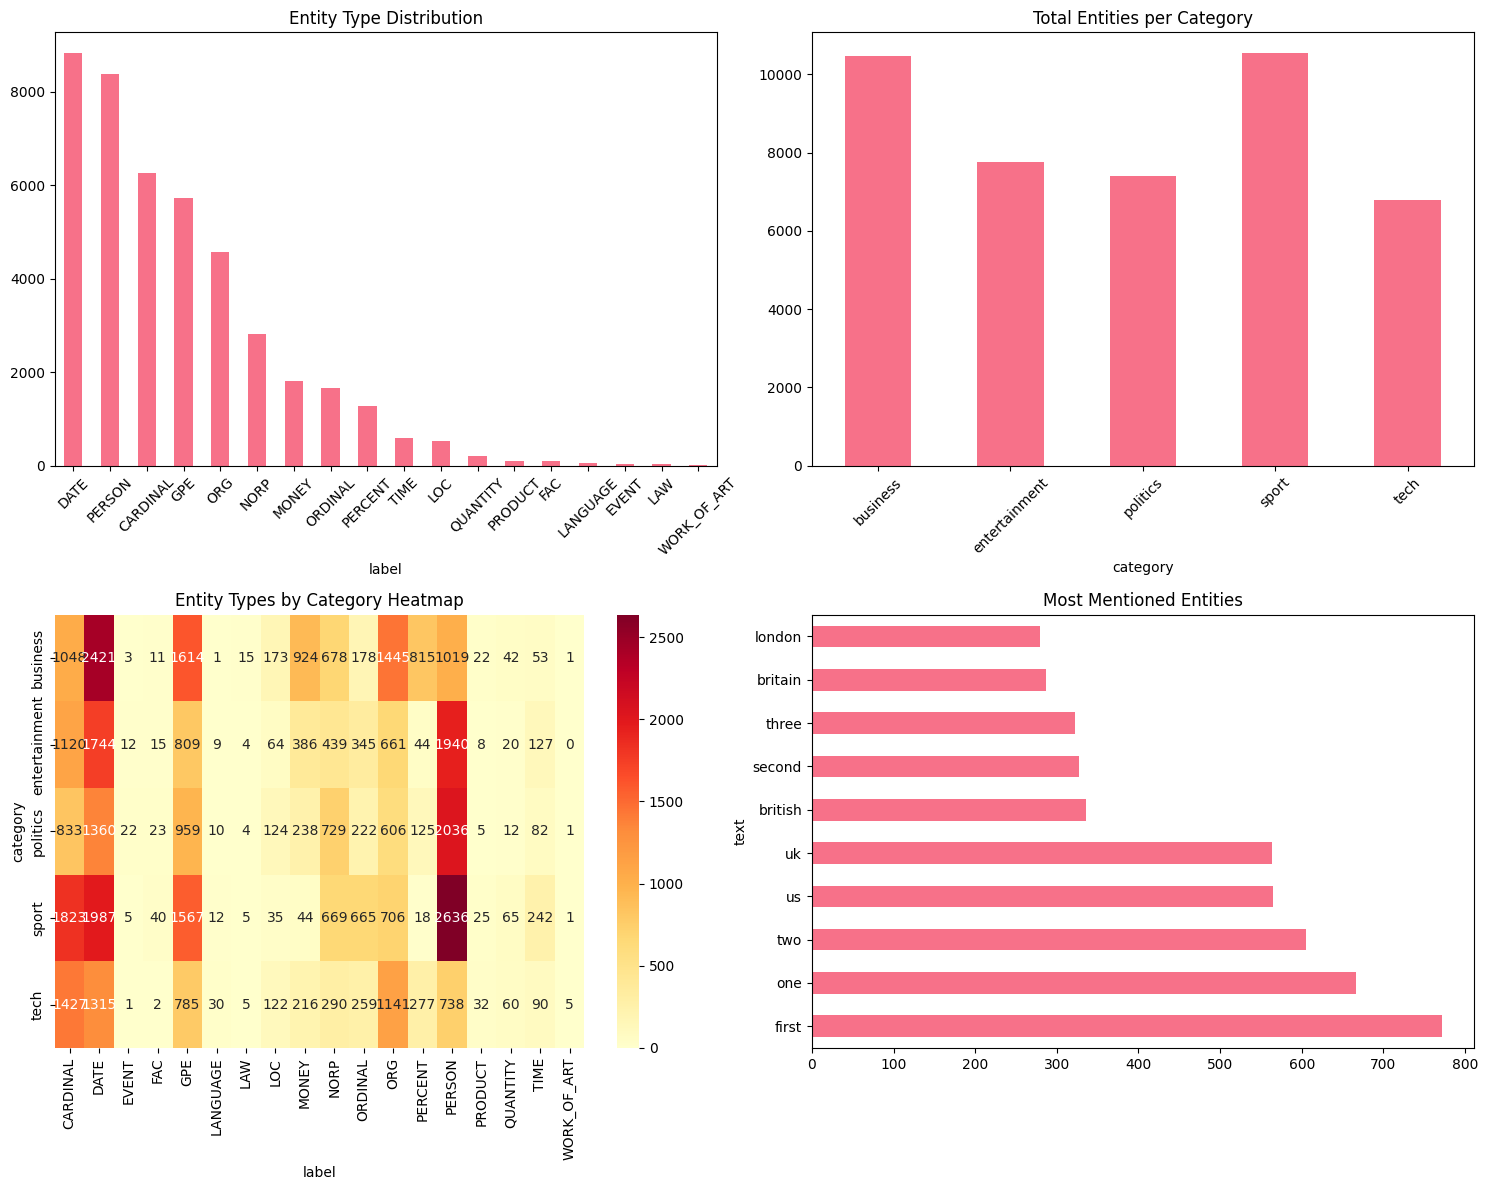


🔍 ADVANCED ENTITY ANALYSIS (STUDENT TASK)

1️⃣ ENTITY CO-OCCURRENCE NETWORK
------------------------------------------------------------
Network: 30 entities, 233 connections

Most connected entities:
  us                     connected to 28 others
  uk                     connected to 28 others
  london                 connected to 27 others
  britain                connected to 24 others
  bbc                    connected to 23 others

Groups of entities that appear together:
  Group 1: ['attack eu', 'bbc', 'bbc news', 'britain', 'england s', 'gordon brown', 'iraq', 'london']
  Group 2: ['china', 'india', 'japan', 'los angeles', 'microsoft', 'new york', 'russia', 'sony']
  Group 3: ['australia', 'england', 'france', 'germany', 'ireland', 'italy', 'paris', 'robbie williams']


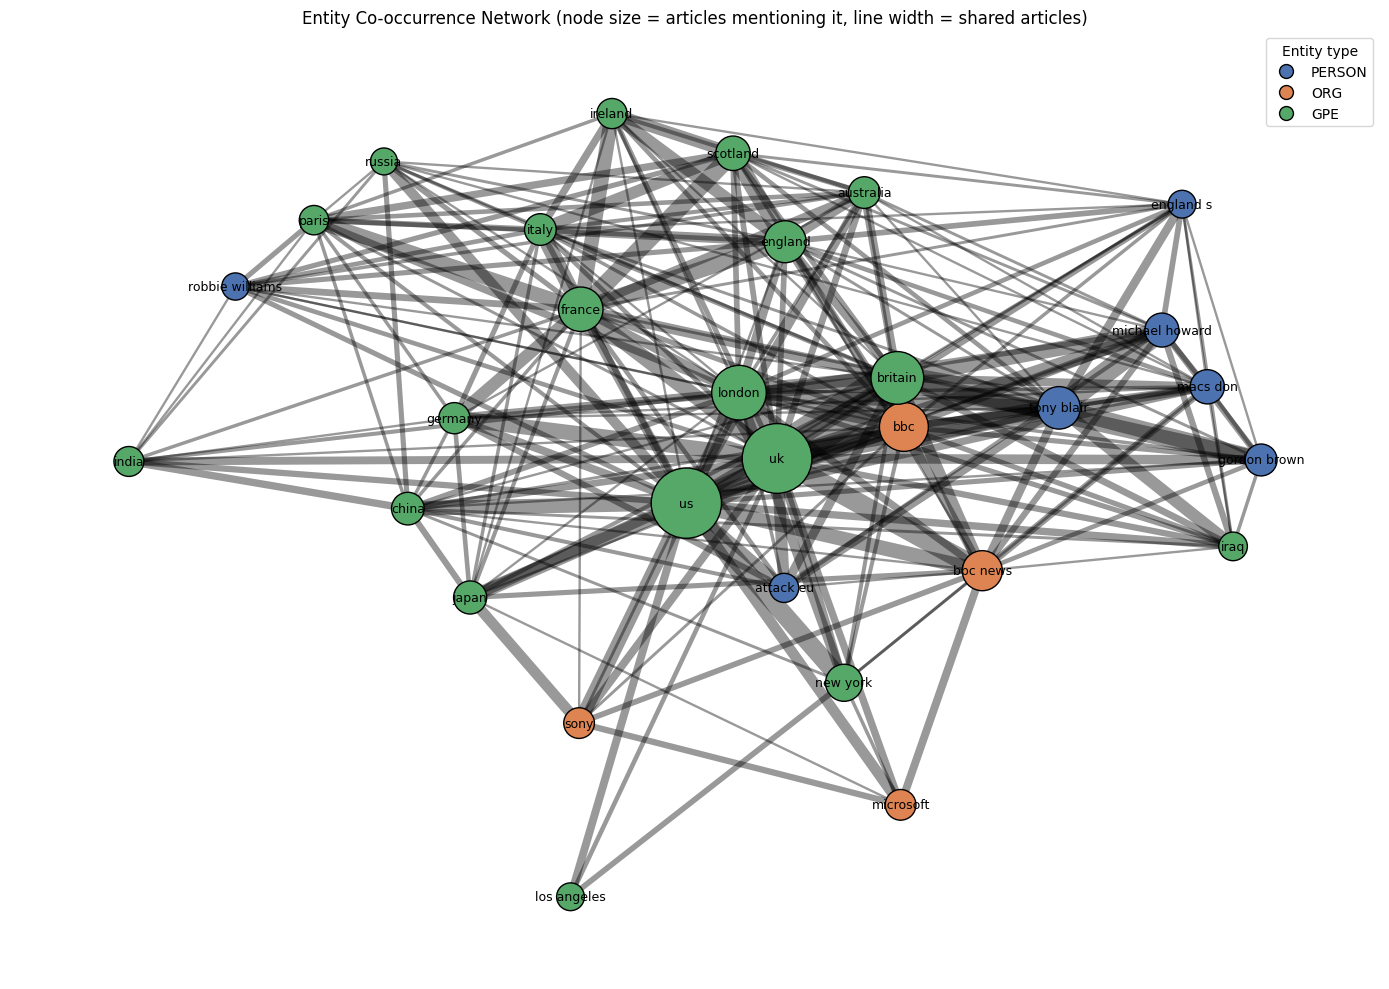


2️⃣ ENTITY MENTIONS OVER TIME
------------------------------------------------------------
The 'date' column holds one placeholder value for every article, so real publication
trends are not possible. Stand-in: the years mentioned inside the articles.
Years mentioned most often (articles): {'2004': 264, '2003': 207, '2005': 204, '2001': 105, '2002': 94, '2006': 75}

Articles mentioning each top person, by year mentioned in the story:
entity_norm  attack eu  gordon brown  macs don  michael howard  tony blair
year                                                                      
2001                 4             6         4               6           6
2002                 2             3         1               0           2
2003                 5            10         6               5          14
2004                 5             9         6               3           9
2005                 8             7         3               8          12
2006                 6             4

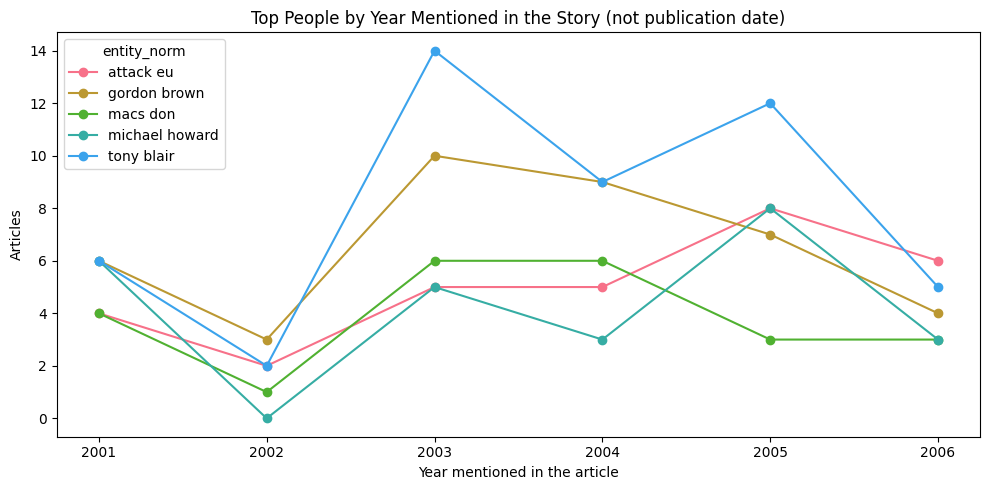


3️⃣ ENTITY RELATIONSHIP GRAPH
------------------------------------------------------------
Parsing 300 articles (about a minute)...
Found 52 entity-to-entity relations (50 distinct)

Most common relations (who -> did what -> to whom):
  cynthia musselman --tell--> bbc s  (2)
  kevin kim --defeat--> jeff morrison 4-6 7-6  (2)
  blair --split--> tony blair s feud  (1)
  charles kennedy --tell--> bbc news  (1)
  fox --tell--> bbc radio  (1)
  securities & exchange commission --accuse--> fannie mae  (1)
  andrew --tell--> bbc radio  (1)
  france --defeat--> irish  (1)
  julien bonnaire --yannick--> yannick nyanga  (1)
  thomas --miss--> scotland  (1)
  bennett --tell--> bbc radio  (1)
  wayne rooney --meet--> neville s cross  (1)
  martin bell --insist--> bbc radio 4  (1)
  moya --lead--> spain  (1)
  myskina --play--> france  (1)


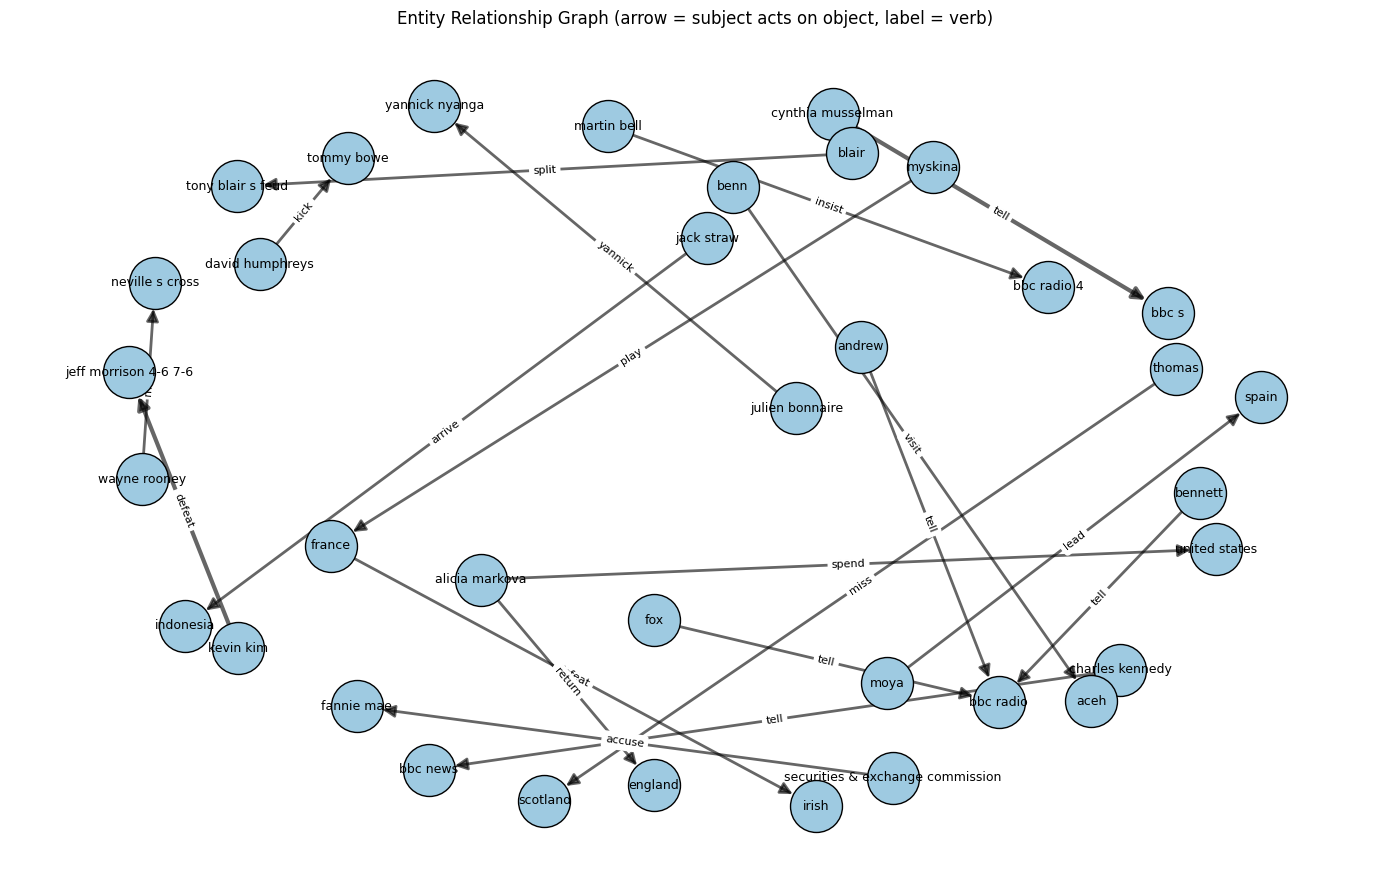


4️⃣ ENTITY SENTIMENT ASSOCIATIONS
------------------------------------------------------------

(a) Sentence-level sentiment (entities in at least 5 sentences):

🟢 Most positive surroundings:
         entity  sentences  mean_sentiment
imelda staunton          5           0.503
        nielsen          7           0.482
  united states          8           0.479
         kilroy          7           0.448
        english          6           0.390
             gb          5           0.368
      liverpool         23           0.366
       scottish         13           0.346

🔴 Most negative surroundings:
       entity  sentences  mean_sentiment
     thailand          5          -0.518
matt williams          5          -0.340
        yukos          7          -0.339
   jack straw          5          -0.277
       dublin          5          -0.269
          fbi         13          -0.268
        asian          5          -0.252
        kelly          5          -0.237


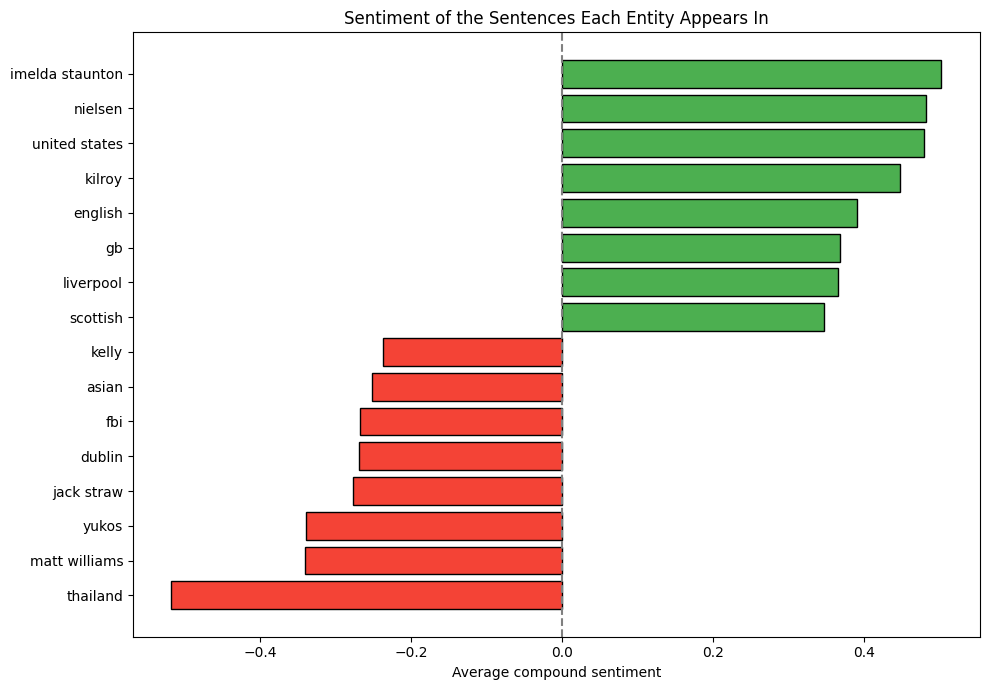


(b) Article-level sentiment (entities in at least 8 articles):

🟢 Most positive:
    entity_norm  label  articles  mean_sentiment
imelda staunton PERSON        16           0.996
     jamie foxx PERSON        13           0.996
          franz    ORG        12           0.995
     tim henman PERSON        10           0.993
     mike leigh PERSON         9           0.988
    ray charles PERSON        15           0.987
          chris PERSON         8           0.983
       motorola    ORG         8           0.983

🔴 Most negative:
         entity_norm  label  articles  mean_sentiment
      charles clarke PERSON        17          -0.704
          mark oaten PERSON        14          -0.701
     isn t. kenteris PERSON        11          -0.610
            katerina PERSON        10          -0.599
               texas    GPE        10          -0.586
                 sec    ORG         9          -0.511
           sri lanka    GPE        12          -0.506
mikhail khodorkovsky PERSON

In [34]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

    import networkx as nx
    from itertools import combinations
    from matplotlib.lines import Line2D
    from networkx.algorithms import community

    print("\n" + "=" * 60)
    print("🔍 ADVANCED ENTITY ANALYSIS (STUDENT TASK)")
    print("=" * 60)

    # Helper that cleans entity names so "Mr Blair" and "Blair" count as one entity
    def norm_name(text):
        t = re.sub(r'\s+', ' ', str(text).strip().lower())
        t = re.sub(r"'s$", '', t)
        t = re.sub(r'^(the|mr|mrs|ms|dr|sir)\.?\s+', '', t)
        return t.strip()

    # The previous NER cell may already have added this column; if not, build it here
    if 'entity_norm' not in entities_df.columns:
        entities_df['entity_norm'] = entities_df['text'].apply(norm_name)
    entities_df = entities_df[entities_df['entity_norm'] != ''].copy()

    # One row per (article, entity), so repeating a name five times in one article counts once
    net_labels = ['PERSON', 'ORG', 'GPE']
    ent_unique = (entities_df[entities_df['label'].isin(net_labels)]
                  .drop_duplicates(['article_id', 'entity_norm', 'label']))
    article_counts = ent_unique['entity_norm'].value_counts()
    label_of = ent_unique.groupby('entity_norm')['label'].agg(lambda s: s.value_counts().idxmax()).to_dict()
    node_colors = {'PERSON': '#4C72B0', 'ORG': '#DD8452', 'GPE': '#55A868'}

    # 1) ENTITY CO-OCCURRENCE NETWORK
    # Two entities are connected when they appear in the same article.
    # Only the 30 most-mentioned entities are kept so the picture stays readable.
    print("\n1️⃣ ENTITY CO-OCCURRENCE NETWORK")
    print("-" * 60)
    top_nodes = set(article_counts.head(30).index)
    cooc = Counter()
    for _, group in ent_unique[ent_unique['entity_norm'].isin(top_nodes)].groupby('article_id'):
        cooc.update(combinations(sorted(set(group['entity_norm'])), 2))

    G = nx.Graph()
    for name in top_nodes:
        G.add_node(name, articles=int(article_counts[name]))
    for (a, b), w in cooc.items():
        if w >= 3:   # only connections seen in at least 3 articles
            G.add_edge(a, b, weight=w)
    G.remove_nodes_from(list(nx.isolates(G)))

    if G.number_of_nodes() > 0:
        print(f"Network: {G.number_of_nodes()} entities, {G.number_of_edges()} connections")

        # Hubs: entities connected to the most other entities
        centrality = nx.degree_centrality(G)
        print("\nMost connected entities:")
        for name, score in sorted(centrality.items(), key=lambda kv: kv[1], reverse=True)[:5]:
            print(f"  {name:<22} connected to {G.degree(name)} others")

        # Communities: groups of entities that are covered together (e.g., one team and its rivals)
        print("\nGroups of entities that appear together:")
        for i, members in enumerate(community.greedy_modularity_communities(G, weight='weight'), 1):
            print(f"  Group {i}: {sorted(members)[:8]}")

        pos = nx.spring_layout(G, seed=42, k=0.9, weight='weight')
        plt.figure(figsize=(14, 10))
        nx.draw_networkx_edges(G, pos, alpha=0.4,
                               width=[0.5 + G[u][v]['weight'] * 0.4 for u, v in G.edges()])
        nx.draw_networkx_nodes(G, pos, edgecolors='black',
                               node_size=[80 + G.nodes[n]['articles'] * 8 for n in G.nodes()],
                               node_color=[node_colors.get(label_of.get(n), 'gray') for n in G.nodes()])
        nx.draw_networkx_labels(G, pos, font_size=9)
        plt.legend(handles=[Line2D([0], [0], marker='o', color='w', markerfacecolor=c,
                                   markeredgecolor='black', markersize=10, label=l)
                            for l, c in node_colors.items()], title='Entity type')
        plt.title('Entity Co-occurrence Network (node size = articles mentioning it, line width = shared articles)')
        plt.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough repeated connections to draw a network.")

    # 2) ENTITY MENTIONS OVER TIME
    print("\n2️⃣ ENTITY MENTIONS OVER TIME")
    print("-" * 60)
    top_people = ent_unique[ent_unique['label'] == 'PERSON']['entity_norm'].value_counts().head(5).index.tolist()
    dates_parsed = pd.to_datetime(df['date'], errors='coerce')

    if dates_parsed.nunique() > 1 and top_people:
        # Real publication dates exist, so track mentions per month
        date_map = pd.Series(dates_parsed.values, index=df['article_id'].values)
        tmp = ent_unique[ent_unique['entity_norm'].isin(top_people)].copy()
        tmp['month'] = tmp['article_id'].map(date_map).dt.to_period('M')
        monthly = tmp.pivot_table(index='month', columns='entity_norm', values='article_id',
                                  aggfunc='nunique', fill_value=0)
        print(monthly)
        monthly.plot(marker='o', figsize=(10, 5))
        plt.title('Articles Mentioning the Top 5 People, by Month')
        plt.xlabel('Month')
        plt.ylabel('Articles')
        plt.tight_layout()
        plt.show()
    else:
        # The date column is one placeholder value, so publication trends are not possible.
        # As a stand-in, track the YEARS MENTIONED inside the articles (DATE entities).
        print("The 'date' column holds one placeholder value for every article, so real publication")
        print("trends are not possible. Stand-in: the years mentioned inside the articles.")
        year_rows = entities_df[entities_df['label'] == 'DATE'].copy()
        year_rows['year'] = year_rows['text'].astype(str).str.extract(r'\b(19\d{2}|20\d{2})\b')[0]
        year_rows = year_rows.dropna(subset=['year']).drop_duplicates(['article_id', 'year'])
        year_counts = year_rows['year'].value_counts()
        keep_years = sorted(year_counts.head(6).index)
        print(f"Years mentioned most often (articles): {year_counts.head(6).to_dict()}")

        if len(keep_years) >= 2 and top_people:
            merged = (ent_unique[ent_unique['entity_norm'].isin(top_people)][['article_id', 'entity_norm']]
                      .merge(year_rows[year_rows['year'].isin(keep_years)][['article_id', 'year']],
                             on='article_id'))
            timeline = (merged.pivot_table(index='year', columns='entity_norm', values='article_id',
                                           aggfunc='nunique', fill_value=0)
                        .reindex(keep_years, fill_value=0))
            print("\nArticles mentioning each top person, by year mentioned in the story:")
            print(timeline)
            timeline.plot(marker='o', figsize=(10, 5))
            plt.title('Top People by Year Mentioned in the Story (not publication date)')
            plt.xlabel('Year mentioned in the article')
            plt.ylabel('Articles')
            plt.tight_layout()
            plt.show()
        else:
            print("Not enough different years mentioned to build a timeline.")

    # 3) ENTITY RELATIONSHIP GRAPH (from the dependency parse)
    # Co-occurrence only says two entities appear together. Here we pull directed relations
    # from sentences like "Microsoft (subject) bought (verb) Skype (object)".
    # Parsing every article is slow, so a random sample of 300 is used.
    print("\n3️⃣ ENTITY RELATIONSHIP GRAPH")
    print("-" * 60)
    sample_n = min(300, len(df))
    ent_sample = df.sample(n=sample_n, random_state=42)
    print(f"Parsing {sample_n} articles (about a minute)...")
    sample_docs = list(nlp.pipe(ent_sample['full_text'].astype(str).tolist(), batch_size=20))

    rel_labels = {'PERSON', 'ORG', 'GPE', 'NORP'}
    relations = Counter()                 # (subject entity, verb, object entity) -> count
    sent_sentiment = defaultdict(list)    # entity -> sentence-level sentiment scores

    for doc in sample_docs:
        # Map every token inside a relevant entity to that entity
        tok2ent = {}
        for ent in doc.ents:
            if ent.label_ in rel_labels:
                for t in ent:
                    tok2ent[t.i] = ent

        for sent in doc.sents:
            # Sentence-level sentiment is credited to every entity named in that sentence (used in section 4)
            sent_names = {norm_name(e.text) for e in sent.ents if e.label_ in rel_labels}
            if sent_names:
                score = sia.polarity_scores(sent.text)['compound']
                for name in sent_names:
                    sent_sentiment[name].append(score)

            # Passive sentences (nsubjpass) are skipped, since their subject receives the action
            for tok in sent:
                if tok.pos_ != 'VERB':
                    continue
                subjects = [c for c in tok.children if c.dep_ == 'nsubj']
                objects = [c for c in tok.children if c.dep_ == 'dobj']
                for prep in (c for c in tok.children if c.dep_ == 'prep'):
                    objects += [c for c in prep.children if c.dep_ == 'pobj']
                for s in subjects:
                    for o in objects:
                        if s.i in tok2ent and o.i in tok2ent:
                            a, b = norm_name(tok2ent[s.i].text), norm_name(tok2ent[o.i].text)
                            if a != b:
                                relations[(a, tok.lemma_.lower(), b)] += 1

    print(f"Found {sum(relations.values())} entity-to-entity relations "
          f"({len(relations)} distinct)")
    if relations:
        print("\nMost common relations (who -> did what -> to whom):")
        for (a, v, b), c in relations.most_common(15):
            print(f"  {a} --{v}--> {b}  ({c})")

        pair_verbs = defaultdict(Counter)
        for (a, v, b), c in relations.items():
            pair_verbs[(a, b)][v] += c
        pair_totals = {pair: sum(vc.values()) for pair, vc in pair_verbs.items()}
        top_pairs = sorted(pair_totals, key=pair_totals.get, reverse=True)[:20]

        D = nx.DiGraph()
        for (a, b) in top_pairs:
            D.add_edge(a, b, weight=pair_totals[(a, b)],
                       label=', '.join(v for v, _ in pair_verbs[(a, b)].most_common(2)))
        pos = nx.spring_layout(D, seed=42, k=1.2)
        plt.figure(figsize=(14, 9))
        nx.draw_networkx_nodes(D, pos, node_color='#9ecae1', node_size=1400, edgecolors='black')
        nx.draw_networkx_labels(D, pos, font_size=9)
        nx.draw_networkx_edges(D, pos, arrows=True, arrowsize=18, alpha=0.6, node_size=1400,
                               width=[1 + D[u][v]['weight'] for u, v in D.edges()])
        nx.draw_networkx_edge_labels(D, pos, font_size=8,
                                     edge_labels={(u, v): D[u][v]['label'] for u, v in D.edges()})
        plt.title('Entity Relationship Graph (arrow = subject acts on object, label = verb)')
        plt.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("No entity-to-entity relations found in the sample.")

    # 4) ENTITY SENTIMENT ASSOCIATIONS
    print("\n4️⃣ ENTITY SENTIMENT ASSOCIATIONS")
    print("-" * 60)

    # (a) Sentence level, from the 300-article sample: the average tone of the sentences
    # in which each entity appears. More precise, but fewer examples per entity.
    min_sentences = 5
    ent_sent = pd.DataFrame(
        [(name, len(v), float(np.mean(v))) for name, v in sent_sentiment.items() if len(v) >= min_sentences],
        columns=['entity', 'sentences', 'mean_sentiment']
    ).sort_values('mean_sentiment', ascending=False).reset_index(drop=True)

    if not ent_sent.empty:
        print(f"\n(a) Sentence-level sentiment (entities in at least {min_sentences} sentences):")
        print("\n🟢 Most positive surroundings:")
        print(ent_sent.head(8).round(3).to_string(index=False))
        print("\n🔴 Most negative surroundings:")
        print(ent_sent.tail(8).iloc[::-1].round(3).to_string(index=False))

        extremes = pd.concat([ent_sent.head(8), ent_sent.tail(8)]).drop_duplicates('entity')
        plt.figure(figsize=(10, 7))
        plt.barh(extremes['entity'][::-1], extremes['mean_sentiment'][::-1], edgecolor='black',
                 color=['#4CAF50' if s >= 0 else '#F44336' for s in extremes['mean_sentiment'][::-1]])
        plt.axvline(0, color='gray', linestyle='--')
        plt.title('Sentiment of the Sentences Each Entity Appears In')
        plt.xlabel('Average compound sentiment')
        plt.tight_layout()
        plt.show()
    else:
        print(f"No entity appears in {min_sentences}+ sampled sentences. Raise sample_n above for more data.")

    # (b) Article level, on the full dataset: the average sentiment of the articles
    # that mention each entity (needs the sentiment cell to have been run).
    if 'sentiment_df' in globals():
        art_sent = (ent_unique.merge(sentiment_df[['article_id', 'full_sentiment']], on='article_id')
                    .groupby(['entity_norm', 'label'])['full_sentiment']
                    .agg(articles='count', mean_sentiment='mean')
                    .reset_index())
        art_sent = art_sent[art_sent['articles'] >= 8].sort_values('mean_sentiment', ascending=False)
        if not art_sent.empty:
            print("\n(b) Article-level sentiment (entities in at least 8 articles):")
            print("\n🟢 Most positive:")
            print(art_sent.head(8).round(3).to_string(index=False))
            print("\n🔴 Most negative:")
            print(art_sent.tail(8).iloc[::-1].round(3).to_string(index=False))

    # SUMMARY
    print("\n📝 SUMMARY")
    print("-" * 60)
    print(f"• Co-occurrence network: {G.number_of_nodes()} entities, {G.number_of_edges()} connections")
    print(f"• Dependency-based relations found in the sample: {sum(relations.values())}")
    if not ent_sent.empty:
        print(f"• Most positive entity (sentence level): {ent_sent.iloc[0]['entity']}, "
              f"most negative: {ent_sent.iloc[-1]['entity']}")

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [35]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1490
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2267 characters
  Average Words per Article: 390 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Naive Bayes
  Best Accuracy: 0.9597

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3903

🔍 ENTITY INSIGHTS:
  Total Entities: 42941
  Unique Entities: 12130
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT, LANGUAGE, WORK_OF_ART, LAW

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy achieved - ready for automated content routing
  2. 📊 entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 politics articles are most negative - may need balanced covera

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [36]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify article category"""
        # 🚀 YOUR CODE HERE: Implement classification
        # Transform text to features
        features = self.vectorizer.transform([processed_text])

        # Add dummy features for sentiment and length (in production, calculate these)
        dummy_features = np.zeros((1, 7))  # 4 sentiment + 3 length features
        features_combined = np.hstack([features.toarray(), dummy_features])

        # Predict category and probability
        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        # Get class probabilities
        class_probs = dict(zip(self.classifier.classes_, probabilities))

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


ℱ TESTING NEWSBOT INTELLIGENCE SYSTEM

 TEST ARTICLE 1
----------------------------------------
 Title: Microsoft Acquires AI Startup for $2 Billion
 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

Predicted Category: tech (54.22% confidence)

 Category Probabilities:
  tech: 0.542
  business: 0.201
  politics: 0.118
  entertainment: 0.080
  sport: 0.060

 Sentiment: positive (score: 0.660)

 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

 Insights:
  ⚠️ Uncertain classification - consider manual review
  😊 Positive sentiment detected (0.66

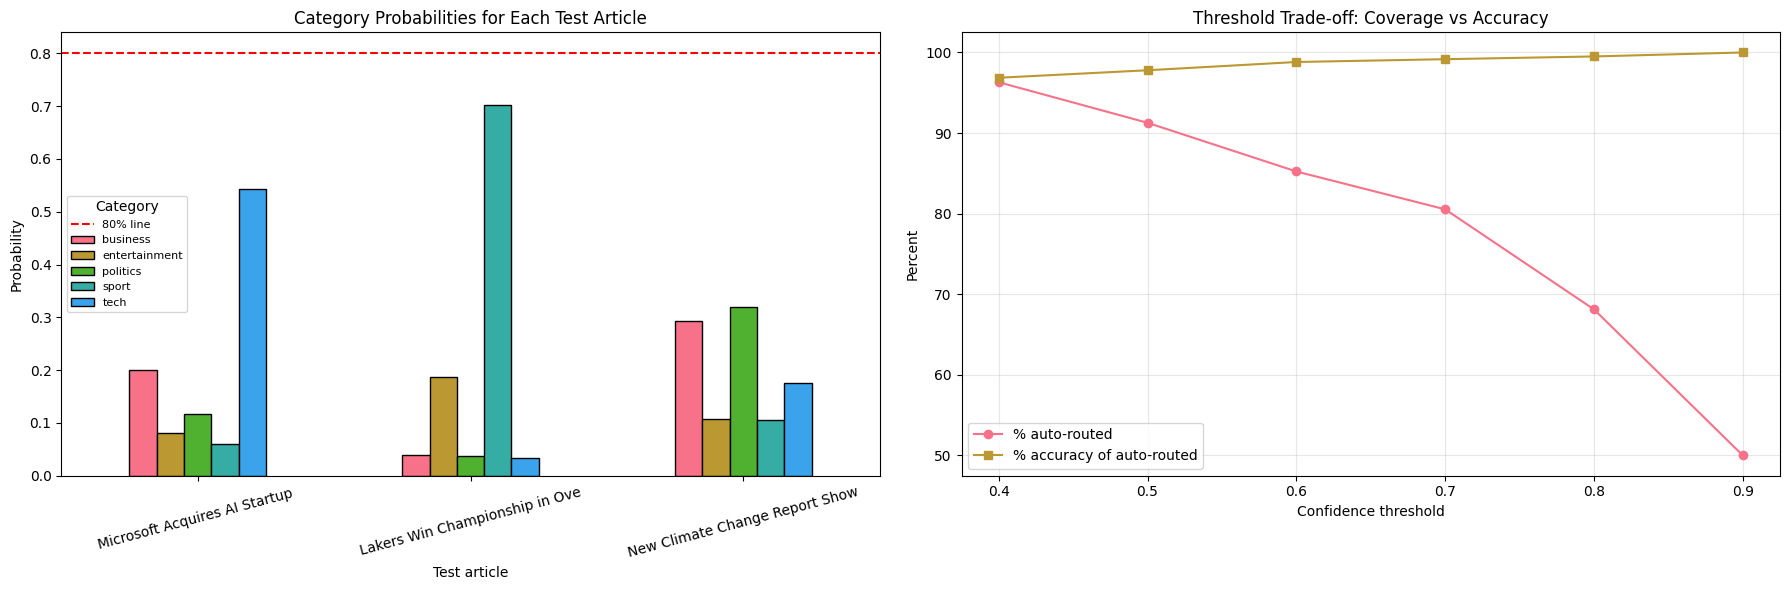


4  IDEAS TO IMPROVE PERFORMANCE
------------------------------------------------------------
  • Add an 'other / needs review' route for low-confidence articles instead of forcing a category
  • Set the review threshold from test-set results (section 3) instead of using a fixed 0.8
  • Add training articles for topics the model has not seen (science, climate, US sport)
  • Use a text-only model in production: it needs no feature alignment
  • Retrain regularly, because news vocabulary changes (new names, events, products)


In [40]:
# Test the complete system with new articles
print("ℱ TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Patch NewsBotIntelligenceSystem directly to avoid the feature mismatch
# We compute the expected metadata padding size dynamically
class FixedNewsBotIntelligenceSystem(NewsBotIntelligenceSystem):
    def classify_article(self, processed_text):
        """Classify article category with dynamic feature padding matching"""
        # Transform text to tfidf features
        features = self.vectorizer.transform([processed_text]).toarray()

        # Determine how many metadata features the classifier expects
        expected_dim = self.classifier.n_features_in_
        tfidf_dim = features.shape[1]
        extra_dim = expected_dim - tfidf_dim

        # Build the exact size of dummy features needed
        dummy_features = np.zeros((1, extra_dim))
        features_combined = np.hstack([features, dummy_features])

        # Predict category and probability
        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        # Get class probabilities
        class_probs = dict(zip(self.classifier.classes_, probabilities))

        return prediction, class_probs

# Re-instantiate the pipeline using our fixed class
newsbot = FixedNewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f" Title: {result['title']}")
    print(f" Content: {result['content']}")
    print(f"\nPredicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n No entities detected")

    print(f"\n Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("  NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# LinearSVC is used for a second opinion model below.
from sklearn.svm import LinearSVC

print("\n" + "=" * 60)
print("ὖ ANALYSIS OF THE TEST ARTICLES (STUDENT TASK)")
print("=" * 60)

# The model's category names, like 'sport' and 'tech'.
known_classes = list(newsbot.classifier.classes_)

def match_class(name):
    """Find the model's label for a name. Ignores capital letters."""
    for c in known_classes:
        if str(c).lower() == str(name).lower():
            return c
    return None

# These are the answers I count as reasonable for each of YOUR three articles.
# Microsoft: business or tech. Lakers: sport. Climate: no right answer.
# Climate has no category in the model, so it has to guess.
reasonable_answers = [
    {'type': 'Clear (business/tech)', 'expected': ['business', 'tech']},
    {'type': 'Clear (sport)',         'expected': ['sport']},
    {'type': 'Out of scope',          'expected': []},
]

# A simple second model that only uses the text.
# I use it to compare with the main model.
text_only_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8)),
    ('clf', LinearSVC(random_state=42))
])
text_only_model.fit(df['full_text_processed'], df['category'])

# Run your three articles through the system and save the results.
rows = []
all_probs = []
for article, rule in zip(test_articles, reasonable_answers):
    res = newsbot.process_article(article['title'], article['content'])
    probs = sorted(res['category_probabilities'].items(), key=lambda kv: kv[1], reverse=True)
    acceptable = [c for c in (match_class(x) for x in rule['expected']) if c is not None]
    all_probs.append(res['category_probabilities'])
    rows.append({
        'title': article['title'][:38],
        'type': rule['type'],
        'predicted': res['predicted_category'],
        'confidence': probs[0][1],
        'runner_up': probs[1][0],
        'margin': probs[0][1] - probs[1][1],
        'sentiment': res['sentiment']['compound'],
        'entities': len(res['entities']),
        'ok': float(res['predicted_category'] in acceptable) if acceptable else np.nan,
        'text_only': text_only_model.predict([preprocess_text(f"{article['title']} {article['content']}")])[0]
    })

results_table = pd.DataFrame(rows)

# 1) Show the result for each article.
print("\n1  RESULTS FOR EACH TEST ARTICLE")
print("-" * 60)
display_table = results_table.copy()
display_table['ok'] = display_table['ok'].map({1.0: '✅', 0.0: '❌'}).fillna('n/a')
print(display_table.round(3).to_string(index=False))

# 2) Strengths and weaknesses.
print("\n2  STRENGTHS AND WEAKNESSES")
print("-" * 60)
for _, r in results_table.iterrows():
    print(f"\n  '{r['title']}' ({r['type']})")
    print(f"    Predicted {r['predicted']} with {r['confidence']:.2%} confidence. "
          f"Runner-up: {r['runner_up']} (gap {r['margin']:.2%}).")
    if r['type'] == 'Out of scope':
        print("    This topic has no category, so the model had to guess.")
        if r['confidence'] >= 0.6:
            print("    Weakness: it still sounds fairly confident on a topic it has never seen.")
        else:
            print("    Strength: confidence is low, so this would go to human review.")
    elif r['ok'] == 1.0:
        print("    Strength: a reasonable answer.")
    else:
        print("    Weakness: not a reasonable answer for this article.")
    if r['predicted'] != r['text_only']:
        print(f"    The text-only model says {r['text_only']}, so the two models disagree.")

print(f"\n  Articles below the 80% confidence line used in the insights: "
      f"{(results_table['confidence'] < 0.8).sum()} of {len(results_table)}")

# 3) Pick a better confidence threshold.
print("\n3  CHOOSING A CONFIDENCE THRESHOLD (held-out test set)")
print("-" * 60)
test_proba = best_model.predict_proba(X_test)
test_conf = test_proba.max(axis=1)
test_pred = best_model.classes_[test_proba.argmax(axis=1)]
sweep = []
for th in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    mask = test_conf >= th
    sweep.append({
        'threshold': th,
        '% auto-routed': mask.mean() * 100,
        '% accuracy of auto-routed': (test_pred[mask] == y_test[mask]).mean() * 100 if mask.any() else np.nan,
        'sent to human review': int((~mask).sum())
    })
sweep_df = pd.DataFrame(sweep)
print(sweep_df.round(1).to_string(index=False))
print(f"\n  Overall test accuracy: {(test_pred == y_test).mean() * 100:.1f}%")

# Charts: probabilities for each of your articles, and the threshold trade-off.
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

probs_df = pd.DataFrame(all_probs, index=[t['title'][:30] for t in test_articles])
probs_df.plot(kind='bar', ax=axes[0], edgecolor='black')
axes[0].axhline(0.8, color='red', linestyle='--', label='80% line')
axes[0].set_title('Category Probabilities for Each Test Article')
axes[0].set_xlabel('Test article')
axes[0].set_ylabel('Probability')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(title='Category', fontsize=8)

axes[1].plot(sweep_df['threshold'], sweep_df['% auto-routed'], marker='o', label='% auto-routed')
axes[1].plot(sweep_df['threshold'], sweep_df['% accuracy of auto-routed'], marker='s',
             label='% accuracy of auto-routed')
axes[1].set_xlabel('Confidence threshold')
axes[1].set_ylabel('Percent')
axes[1].set_title('Threshold Trade-off: Coverage vs Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 4) Ideas to improve the system.
print("\n4  IDEAS TO IMPROVE PERFORMANCE")
print("-" * 60)
print("  • Add an 'other / needs review' route for low-confidence articles instead of forcing a category")
print("  • Set the review threshold from test-set results (section 3) instead of using a fixed 0.8")
print("  • Add training articles for topics the model has not seen (science, climate, US sport)")
print("  • Use a text-only model in production: it needs no feature alignment")
print("  • Retrain regularly, because news vocabulary changes (new names, events, products)")

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?

The most challenging aspect of this project was ensuring that all features aligned correctly, particularly the column names and the feature ordering expected by the trained model. TF-IDF proved to be the most valuable technique because it provided the foundation for accurate article classification. Text preprocessing was equally important, as the quality of the model's outputs depended heavily on having clean and consistent input data.

2. **Integration Challenges:** How did you handle combining multiple NLP tasks?

I addressed integration challenges by executing the notebook sequentially and validating the structure, dimensions, and column names of the dataset after each stage. Whenever issues arose, such as missing functions or mismatched feature names, I resolved them before proceeding. In the final implementation, I ensured that new articles underwent the same preprocessing and feature engineering pipeline used during model training, maintaining consistency between training and inference.

3. **Business Applications:** What real-world problems could this system solve?

This system has several practical business applications. Media organizations could use it to automatically categorize articles and route content to the appropriate departments. Businesses could also leverage the entity recognition and sentiment analysis components to monitor public perception and identify trends related to their brand. Similar techniques could be applied to large volumes of customer reviews, support tickets, or other text-based datasets to improve operational efficiency and decision-making.

4. **Ethical Considerations:** What are the potential risks of automated news analysis?

One significant concern is the possibility of model bias or misclassification, particularly if users place excessive trust in automated predictions. For example, the model occasionally assigned articles to incorrect categories, demonstrating the limitations of automated classification. Similarly, sentiment analysis tools may misinterpret tone or context, potentially leading to inaccurate conclusions. To mitigate these risks, human oversight should be incorporated, especially when predictions are uncertain or have important consequences.

5. **Future Learning:** What NLP topics are you most excited to explore next?

I am particularly interested in learning more about transformer-based models such as BERT, which are capable of capturing contextual relationships in text more effectively than traditional TF-IDF approaches. I would also like to explore topic modeling and text summarization techniques, as they could enhance the analytical capabilities and overall usefulness of systems like this one.

6. **Team Collaboration:** How did you divide work and ensure quality?

This project was completed independently and took me about three days to finish, which was challenging at times. To stay on track, I tested each section of the notebook as I worked and fixed errors as soon as they appeared instead of saving all debugging for the end. Working through the project on my own helped me improve my time management, troubleshooting skills, and confidence in solving technical problems independently.

7. **Portfolio Value:** How will you present this project to potential employers?

I would present this project as an end-to-end natural language processing (NLP) solution that transforms raw news articles into actionable insights through classification, entity recognition, and sentiment analysis. The project would be accompanied by a well-documented GitHub repository, including a detailed README that explains the methodology, challenges encountered, and solutions implemented. It demonstrates proficiency across the entire NLP workflow, from data preprocessing and feature engineering to model development and deployment.

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*